In [1]:
import requests

urls = {
    "Fakeddit GitHub": "https://github.com/entitize/Fakeddit",
    "Hugging Face": "https://huggingface.co"
}

for name, url in urls.items():
    try:
        r = requests.get(url, timeout=15)
        print(f"{name}: HTTP {r.status_code}")
    except Exception as e:
        print(f"{name}: FAILED - {e}")

Fakeddit GitHub: HTTP 200
Hugging Face: HTTP 200


In [2]:
!pip -q install gdown

import gdown
import os

os.makedirs("/kaggle/working/fakeddit", exist_ok=True)

folder_url = (
    "https://drive.google.com/drive/folders/"
    "1jU7qgDqU1je9Y0PMKJ_f31yXRo5uWGFm"
)

result = gdown.download_folder(
    url=folder_url,
    output="/kaggle/working/fakeddit",
    quiet=False
)

print("Download result:", result)
print("\nFiles downloaded:")

for root, dirs, files in os.walk("/kaggle/working/fakeddit"):
    for file in files:
        print(os.path.join(root, file))

Retrieving folder contents


Retrieving folder 1qYgeupmblRZDsUNaasJEtIJ6Sv-PEOlF all_samples (also includes non multimodal)
Processing file 1gPSV95sL7RU_vEG4-I9sp_rguqrDA8jL all_test_public.tsv
Processing file 1jfTO-aLbR_w2stAkijFOL0dbSE__LeOI all_train.tsv
Processing file 1C5_2_2M_6r7mtQJulrXizjAb95vxRibr all_validate.tsv
Retrieving folder 1DuH0YaEox08ZwzZDpRMOaFpMCeRyxiEF multimodal_only_samples
Processing file 1p9EewIKVcFbipVRLZNGYc2JbSC7A0SWv multimodal_test_public.tsv
Processing file 1XsOkD3yhxgWu8URMes0S9LVSwuFJ4pT6 multimodal_train.tsv
Processing file 1Z99QrwpthioZQY2U6HElmnx8jazf7-Kv multimodal_validate.tsv


Retrieving folder contents completed
Building directory structure
Building directory structure completed
Downloading...
From: https://drive.google.com/uc?id=1gPSV95sL7RU_vEG4-I9sp_rguqrDA8jL
To: /kaggle/working/fakeddit/all_samples (also includes non multimodal)/all_test_public.tsv
100%|██████████| 23.9M/23.9M [00:00<00:00, 70.1MB/s]
Downloading...
From (original): https://drive.google.com/uc?id=1jfTO-aLbR_w2stAkijFOL0dbSE__LeOI
From (redirected): https://drive.google.com/uc?id=1jfTO-aLbR_w2stAkijFOL0dbSE__LeOI&confirm=t&uuid=3dba8c8c-b025-4e5e-be60-6e64d54f7528
To: /kaggle/working/fakeddit/all_samples (also includes non multimodal)/all_train.tsv
100%|██████████| 229M/229M [00:01<00:00, 123MB/s] 
Downloading...
From: https://drive.google.com/uc?id=1C5_2_2M_6r7mtQJulrXizjAb95vxRibr
To: /kaggle/working/fakeddit/all_samples (also includes non multimodal)/all_validate.tsv
100%|██████████| 23.9M/23.9M [00:00<00:00, 93.9MB/s]
Downloading...
From: https://drive.google.com/uc?id=1p9EewIKVcFbip

Download result: ['/kaggle/working/fakeddit/all_samples (also includes non multimodal)/all_test_public.tsv', '/kaggle/working/fakeddit/all_samples (also includes non multimodal)/all_train.tsv', '/kaggle/working/fakeddit/all_samples (also includes non multimodal)/all_validate.tsv', '/kaggle/working/fakeddit/multimodal_only_samples/multimodal_test_public.tsv', '/kaggle/working/fakeddit/multimodal_only_samples/multimodal_train.tsv', '/kaggle/working/fakeddit/multimodal_only_samples/multimodal_validate.tsv']

Files downloaded:
/kaggle/working/fakeddit/multimodal_only_samples/multimodal_train.tsv
/kaggle/working/fakeddit/multimodal_only_samples/multimodal_validate.tsv
/kaggle/working/fakeddit/multimodal_only_samples/multimodal_test_public.tsv
/kaggle/working/fakeddit/all_samples (also includes non multimodal)/all_validate.tsv
/kaggle/working/fakeddit/all_samples (also includes non multimodal)/all_train.tsv
/kaggle/working/fakeddit/all_samples (also includes non multimodal)/all_test_public.t


Download completed


In [3]:
import glob
import pandas as pd
import os

tsv_files = glob.glob(
    "/kaggle/working/fakeddit/**/*.tsv",
    recursive=True
)

print("TSV files found:", len(tsv_files))

for file in tsv_files:
    print(os.path.basename(file), os.path.getsize(file) / (1024**2), "MB")

TSV files found: 6
multimodal_train.tsv 148.4459409713745 MB
multimodal_validate.tsv 15.58633804321289 MB
multimodal_test_public.tsv 15.642248153686523 MB
all_validate.tsv 22.80379009246826 MB
all_train.tsv 218.4253215789795 MB
all_test_public.tsv 22.835450172424316 MB


In [4]:

import os
import pandas as pd

DATA_DIR = "/kaggle/working/fakeddit/multimodal_only_samples"

files = {
    "train": os.path.join(DATA_DIR, "multimodal_train.tsv"),
    "validation": os.path.join(DATA_DIR, "multimodal_validate.tsv"),
    "test": os.path.join(DATA_DIR, "multimodal_test_public.tsv"),
}

for split, path in files.items():
    print(f"\n{'=' * 20} {split.upper()} {'=' * 20}")

    # Read only a small sample to inspect the schema
    sample = pd.read_csv(path, sep="\t", nrows=5)

    print("Columns:")
    print(sample.columns.tolist())

    print("\nFirst 2 records:")
    display(sample.head(2))

    print("\nFile size:", round(os.path.getsize(path) / (1024**2), 2), "MB")



==================== TRAIN ====================
Columns:
['author', 'clean_title', 'created_utc', 'domain', 'hasImage', 'id', 'image_url', 'linked_submission_id', 'num_comments', 'score', 'subreddit', 'title', 'upvote_ratio', '2_way_label', '3_way_label', '6_way_label']

First 2 records:


,author,clean_title,created_utc,domain,hasImage,id,image_url,linked_submission_id,num_comments,score,subreddit,title,upvote_ratio,2_way_label,3_way_label,6_way_label
0,Alexithymia,my walgreens offbrand mucinex was engraved wit...,1.551641e+09,i.imgur.com,True,awxhir,https://external-preview.redd.it/WylDbZrnbvZdB...,NaN,2.0,12,mildlyinteresting,My Walgreens offbrand Mucinex was engraved wit...,0.84,1,0,0
1,VIDCAs17,this concerned sink with a tiny hat,1.534727e+09,i.redd.it,True,98pbid,https://preview.redd.it/wsfx0gp0f5h11.jpg?widt...,NaN,2.0,119,pareidolia,This concerned sink with a tiny hat,0.99,0,2,2



File size: 148.45 MB

==================== VALIDATION ====================
Columns:
['author', 'clean_title', 'created_utc', 'domain', 'hasImage', 'id', 'image_url', 'linked_submission_id', 'num_comments', 'score', 'subreddit', 'title', 'upvote_ratio', '2_way_label', '3_way_label', '6_way_label']

First 2 records:


,author,clean_title,created_utc,domain,hasImage,id,image_url,linked_submission_id,num_comments,score,subreddit,title,upvote_ratio,2_way_label,3_way_label,6_way_label
0,singingdart7854,my xbox controller says hi,1.567436e+09,i.redd.it,True,cypw96,https://preview.redd.it/l0ga0tug17k31.jpg?widt...,NaN,4.0,25,mildlyinteresting,My Xbox controller says hi,0.72,1,0,0
1,mandal0re,new image from the mandalorian,1.567745e+09,i.imgur.com,True,d0bzlq,https://external-preview.redd.it/VX7bXDu9Gl8UZ...,NaN,5.0,21,photoshopbattles,PsBattle: New image from The Mandalorian,0.92,1,0,0



File size: 15.59 MB

==================== TEST ====================
Columns:
['author', 'clean_title', 'created_utc', 'domain', 'hasImage', 'id', 'image_url', 'linked_submission_id', 'num_comments', 'score', 'subreddit', 'title', 'upvote_ratio', '2_way_label', '3_way_label', '6_way_label']

First 2 records:


,author,clean_title,created_utc,domain,hasImage,id,image_url,linked_submission_id,num_comments,score,subreddit,title,upvote_ratio,2_way_label,3_way_label,6_way_label
0,trustbytrust,stargazer,1.425139e+09,NaN,True,cozywbv,http://i.imgur.com/BruWKDi.jpg,2xct9d,NaN,3,psbattle_artwork,stargazer,NaN,0,2,4
1,NaN,yeah,1.438173e+09,NaN,True,ctk61yw,http://i.imgur.com/JRZT727.jpg,3f0h7o,NaN,2,psbattle_artwork,yeah,NaN,0,2,4



File size: 15.64 MB


In [5]:

import pandas as pd
import os

train_path = (
    "/kaggle/working/fakeddit/multimodal_only_samples/"
    "multimodal_train.tsv"
)

# Load only the fields needed for initial dataset analysis
df = pd.read_csv(train_path, sep="\t")

print("Training samples:", len(df))
print("\nColumns:", df.columns.tolist())

if "2_way_label" in df.columns:
    print("\nBinary label distribution:")
    print(df["2_way_label"].value_counts(dropna=False).sort_index())

if "image_url" in df.columns:
    print("\nMissing image URLs:", df["image_url"].isna().sum())
    print("Non-empty image URLs:", df["image_url"].astype(str).str.strip().ne("").sum())

if "clean_title" in df.columns:
    print("Missing text:", df["clean_title"].isna().sum())


Training samples: 564000

Columns: ['author', 'clean_title', 'created_utc', 'domain', 'hasImage', 'id', 'image_url', 'linked_submission_id', 'num_comments', 'score', 'subreddit', 'title', 'upvote_ratio', '2_way_label', '3_way_label', '6_way_label']

Binary label distribution:
2_way_label
0    341919
1    222081
Name: count, dtype: int64

Missing image URLs: 1534
Non-empty image URLs: 564000
Missing text: 0


In [6]:
import tensorflow as tf

print("TensorFlow:", tf.__version__)
print("GPUs:", tf.config.list_physical_devices("GPU"))

!nvidia-smi

TensorFlow: 2.20.0
GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]
Thu Oct 29 13:14:55 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.178.04             Driver Version: 580.178.04     CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   43C    P8              9W /   70W |       3MiB /  15360MiB |      

In [7]:
import tensorflow as tf

for gpu in tf.config.list_physical_devices("GPU"):
    print(gpu)

print("\nTensorFlow GPU test:")

with tf.device("/GPU:0"):
    a = tf.random.normal((2000, 2000))
    b = tf.matmul(a, a)

print("GPU 0 test passed:", b.shape)

with tf.device("/GPU:1"):
    c = tf.random.normal((2000, 2000))
    d = tf.matmul(c, c)

print("GPU 1 test passed:", d.shape)

PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')
PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')

TensorFlow GPU test:
GPU 0 test passed: (2000, 2000)
GPU 1 test passed: (2000, 2000)


I0000 00:00:1793279695.950860      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1793279695.954406      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


# Short Experiment

In [8]:

import pandas as pd
import requests
from concurrent.futures import ThreadPoolExecutor

path = (
    "/kaggle/working/fakeddit/multimodal_only_samples/"
    "multimodal_train.tsv"
)

df = pd.read_csv(
    path,
    sep="\t",
    usecols=["id", "clean_title", "image_url", "2_way_label"]
)

# Keep records with valid text and an HTTP image URL
df = df.dropna(subset=["clean_title", "image_url"])
df = df[
    df["clean_title"].astype(str).str.strip().ne("")
    & df["image_url"].astype(str).str.startswith("http")
]

sample = df.sample(n=min(20, len(df)), random_state=42)

def check_image(url):
    try:
        response = requests.get(
            url,
            timeout=10,
            headers={"User-Agent": "Mozilla/5.0"},
            stream=True,
            allow_redirects=True
        )

        content_type = response.headers.get("Content-Type", "")
        result = (
            response.status_code == 200
            and "image" in content_type.lower()
        )

        response.close()
        return result

    except requests.RequestException:
        return False

with ThreadPoolExecutor(max_workers=5) as pool:
    results = list(pool.map(check_image, sample["image_url"]))

total = len(results)
success = sum(results)

print("URLs tested:", total)
print("Images accessible:", success)
print("Images inaccessible:", total - success)
print(
    "Accessible rate:",
    f"{success / total:.0%}" if total else "No records to test"
)


URLs tested: 20
Images accessible: 20
Images inaccessible: 0
Accessible rate: 100%


In [9]:

import os
import pandas as pd
from sklearn.model_selection import train_test_split

DATA_DIR = "/kaggle/working/fakeddit/multimodal_only_samples"
OUTPUT_DIR = "/kaggle/working/fakeddit/short_experiment"

os.makedirs(OUTPUT_DIR, exist_ok=True)

train_path = os.path.join(DATA_DIR, "multimodal_train.tsv")

# Read only the columns needed for this experiment
df = pd.read_csv(
    train_path,
    sep="\t",
    usecols=["id", "clean_title", "image_url", "2_way_label"]
)

# Keep records with text, image URL, and a valid binary label
df = df.dropna(subset=["id", "clean_title", "image_url", "2_way_label"])
df["clean_title"] = df["clean_title"].astype(str).str.strip()
df["image_url"] = df["image_url"].astype(str).str.strip()
df["2_way_label"] = pd.to_numeric(
    df["2_way_label"], errors="coerce"
)
df = df.dropna(subset=["2_way_label"])
df["2_way_label"] = df["2_way_label"].astype(int)

df = df[
    df["clean_title"].ne("")
    & df["image_url"].str.startswith("http")
    & df["2_way_label"].isin([0, 1])
]

# Select 1,500 examples from each class
balanced = (
    df.groupby("2_way_label", group_keys=False)
      .sample(n=1500, random_state=42)
      .reset_index(drop=True)
)

# Split into 80% train, 10% validation, 10% test
train_df, temp_df = train_test_split(
    balanced,
    test_size=0.20,
    random_state=42,
    stratify=balanced["2_way_label"]
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=42,
    stratify=temp_df["2_way_label"]
)

for name, split in [
    ("train", train_df),
    ("validation", val_df),
    ("test", test_df)
]:
    out_path = os.path.join(OUTPUT_DIR, f"{name}.csv")
    split.to_csv(out_path, index=False)

    print(f"\n{name.upper()}: {len(split)} records")
    print(split["2_way_label"].value_counts().sort_index())
    print("Saved:", out_path)

print("\nSubset created successfully.")



TRAIN: 2400 records
2_way_label
0    1200
1    1200
Name: count, dtype: int64
Saved: /kaggle/working/fakeddit/short_experiment/train.csv

VALIDATION: 300 records
2_way_label
0    150
1    150
Name: count, dtype: int64
Saved: /kaggle/working/fakeddit/short_experiment/validation.csv

TEST: 300 records
2_way_label
0    150
1    150
Name: count, dtype: int64
Saved: /kaggle/working/fakeddit/short_experiment/test.csv

Subset created successfully.


In [10]:

import os
import requests
import pandas as pd
from PIL import Image
from io import BytesIO
from concurrent.futures import ThreadPoolExecutor
from tqdm.auto import tqdm

BASE_DIR = "/kaggle/working/fakeddit/short_experiment"
IMAGE_DIR = os.path.join(BASE_DIR, "images")
os.makedirs(IMAGE_DIR, exist_ok=True)

session_headers = {
    "User-Agent": "Mozilla/5.0"
}

def download_image(row):
    image_id = str(row["id"])
    image_url = row["image_url"]
    save_path = os.path.join(IMAGE_DIR, f"{image_id}.jpg")

    try:
        # Reuse an image if it has already been downloaded
        if os.path.exists(save_path):
            with Image.open(save_path) as img:
                img.verify()
            return image_id, True

        response = requests.get(
            image_url,
            headers=session_headers,
            timeout=15
        )
        response.raise_for_status()

        # Validate the image and convert it to RGB JPEG
        with Image.open(BytesIO(response.content)) as img:
            img = img.convert("RGB")
            img.thumbnail((256, 256))
            img.save(save_path, format="JPEG", quality=90)

        return image_id, True

    except Exception:
        if os.path.exists(save_path):
            os.remove(save_path)
        return image_id, False


for split_name in ["train", "validation", "test"]:
    csv_path = os.path.join(BASE_DIR, f"{split_name}.csv")
    df = pd.read_csv(csv_path)

    print(f"\nDownloading {split_name} images: {len(df)} records")

    rows = df.to_dict("records")
    results = []

    with ThreadPoolExecutor(max_workers=12) as executor:
        for result in tqdm(
            executor.map(download_image, rows),
            total=len(rows)
        ):
            results.append(result)

    success_ids = {
        image_id for image_id, success in results if success
    }

    df["image_id"] = df["id"].astype(str)
    df = df[df["image_id"].isin(success_ids)].copy()

    output_path = os.path.join(
        BASE_DIR, f"{split_name}_verified.csv"
    )
    df.to_csv(output_path, index=False)

    print(f"Images downloaded successfully: {len(df)}")
    print(f"Images failed: {len(rows) - len(df)}")
    print(f"Verified CSV saved: {output_path}")

print("\nImage download and verification finished.")


  0%|          | 0/2400 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Images downloaded successfully: 2273
Images failed: 127
Verified CSV saved: /kaggle/working/fakeddit/short_experiment/train_verified.csv



  0%|          | 0/300 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Images downloaded successfully: 277
Images failed: 23
Verified CSV saved: /kaggle/working/fakeddit/short_experiment/validation_verified.csv



  0%|          | 0/300 [00:00<?, ?it/s]

Images downloaded successfully: 286
Images failed: 14
Verified CSV saved: /kaggle/working/fakeddit/short_experiment/test_verified.csv

Image download and verification finished.


In [11]:

import os
import pandas as pd

BASE_DIR = "/kaggle/working/fakeddit/short_experiment"

for split_name in ["train", "validation", "test"]:
    path = os.path.join(BASE_DIR, f"{split_name}_verified.csv")
    df = pd.read_csv(path)

    print(f"\n{split_name.upper()}")
    print("Total:", len(df))
    print("Class counts:")
    print(df["2_way_label"].value_counts().sort_index())
    print("Missing text:", df["clean_title"].isna().sum())
    print("Missing image ID:", df["image_id"].isna().sum())



TRAIN
Total: 2273
Class counts:
2_way_label
0    1155
1    1118
Name: count, dtype: int64
Missing text: 0
Missing image ID: 0

VALIDATION
Total: 277
Class counts:
2_way_label
0    144
1    133
Name: count, dtype: int64
Missing text: 0
Missing image ID: 0

TEST
Total: 286
Class counts:
2_way_label
0    150
1    136
Name: count, dtype: int64
Missing text: 0
Missing image ID: 0


In [12]:

import os
import pandas as pd
import numpy as np

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

BASE_DIR = "/kaggle/working/fakeddit/short_experiment"

train_df = pd.read_csv(os.path.join(BASE_DIR, "train_verified.csv"))
val_df = pd.read_csv(os.path.join(BASE_DIR, "validation_verified.csv"))
test_df = pd.read_csv(os.path.join(BASE_DIR, "test_verified.csv"))

# Text and labels
X_train_text = train_df["clean_title"].astype(str)
y_train = train_df["2_way_label"].astype(int)

X_val_text = val_df["clean_title"].astype(str)
y_val = val_df["2_way_label"].astype(int)

X_test_text = test_df["clean_title"].astype(str)
y_test = test_df["2_way_label"].astype(int)

# Convert text into TF-IDF features
tfidf = TfidfVectorizer(
    max_features=10000,
    ngram_range=(1, 2),
    stop_words="english",
    min_df=2,
    sublinear_tf=True
)

X_train = tfidf.fit_transform(X_train_text)
X_val = tfidf.transform(X_val_text)
X_test = tfidf.transform(X_test_text)

print("Feature shapes:")
print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

# Train baseline model
model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)

model.fit(X_train, y_train)

# Evaluate on validation set
val_pred = model.predict(X_val)

print("\nVALIDATION RESULTS")
print("Accuracy:", round(accuracy_score(y_val, val_pred), 4))
print("Precision:", round(precision_score(y_val, val_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_val, val_pred, zero_division=0), 4))
print("F1-score:", round(f1_score(y_val, val_pred, zero_division=0), 4))

# Final evaluation on test set
test_pred = model.predict(X_test)

print("\nTEST RESULTS")
print("Accuracy:", round(accuracy_score(y_test, test_pred), 4))
print("Precision:", round(precision_score(y_test, test_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, test_pred, zero_division=0), 4))
print("F1-score:", round(f1_score(y_test, test_pred, zero_division=0), 4))

print("\nClassification Report:")
print(classification_report(
    y_test, test_pred,
    target_names=["Label 0", "Label 1"],
    zero_division=0
))

print("Confusion Matrix:")
print(confusion_matrix(y_test, test_pred))

# Save the test predictions for later comparison
results = test_df[["id", "clean_title", "2_way_label"]].copy()
results["text_prediction"] = test_pred
results.to_csv(
    os.path.join(BASE_DIR, "text_baseline_predictions.csv"),
    index=False
)

print("\nSaved text_baseline_predictions.csv")


Feature shapes:
Train: (2273, 1904)
Validation: (277, 1904)
Test: (286, 1904)

VALIDATION RESULTS
Accuracy: 0.7004
Precision: 0.7083
Recall: 0.6391
F1-score: 0.6719

TEST RESULTS
Accuracy: 0.6958
Precision: 0.6899
Recall: 0.6544
F1-score: 0.6717

Classification Report:
              precision    recall  f1-score   support

     Label 0       0.70      0.73      0.72       150
     Label 1       0.69      0.65      0.67       136

    accuracy                           0.70       286
   macro avg       0.70      0.69      0.69       286
weighted avg       0.70      0.70      0.70       286

Confusion Matrix:
[[110  40]
 [ 47  89]]

Saved text_baseline_predictions.csv


In [13]:

import os
import numpy as np
import pandas as pd
import tensorflow as tf

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix
)

from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

# --------------------------------------------------
# 1. Configuration
# --------------------------------------------------
SEED = 42
tf.keras.utils.set_random_seed(SEED)

BASE_DIR = "/kaggle/working/fakeddit/short_experiment"
IMAGE_DIR = os.path.join(BASE_DIR, "images")

IMG_SIZE = 160
BATCH_SIZE = 32
EPOCHS = 15

# --------------------------------------------------
# 2. Load verified datasets
# --------------------------------------------------
train_df = pd.read_csv(os.path.join(BASE_DIR, "train_verified.csv"))
val_df = pd.read_csv(os.path.join(BASE_DIR, "validation_verified.csv"))
test_df = pd.read_csv(os.path.join(BASE_DIR, "test_verified.csv"))

def get_image_paths(df):
    paths = [
        os.path.join(IMAGE_DIR, f"{image_id}.jpg")
        for image_id in df["image_id"].astype(str)
    ]

    missing = [p for p in paths if not os.path.isfile(p)]
    if missing:
        raise FileNotFoundError(
            f"{len(missing)} image files are missing. "
            f"Example: {missing[0]}"
        )

    return paths

train_paths = get_image_paths(train_df)
val_paths = get_image_paths(val_df)
test_paths = get_image_paths(test_df)

y_train = train_df["2_way_label"].to_numpy(dtype="int32")
y_val = val_df["2_way_label"].to_numpy(dtype="int32")
y_test = test_df["2_way_label"].to_numpy(dtype="int32")

print("Dataset sizes:", len(train_df), len(val_df), len(test_df))
print("Images verified on disk.")

# --------------------------------------------------
# 3. Convert text to TF-IDF features
# Use the same settings as the baseline
# --------------------------------------------------
tfidf = TfidfVectorizer(
    max_features=10000,
    ngram_range=(1, 2),
    stop_words="english",
    min_df=2,
    sublinear_tf=True
)

X_train_text = tfidf.fit_transform(
    train_df["clean_title"].astype(str)
).toarray().astype("float32")

X_val_text = tfidf.transform(
    val_df["clean_title"].astype(str)
).toarray().astype("float32")

X_test_text = tfidf.transform(
    test_df["clean_title"].astype(str)
).toarray().astype("float32")

print("Text feature shape:", X_train_text.shape)

# --------------------------------------------------
# 4. Load pretrained MobileNetV2
# Keep the image backbone frozen
# --------------------------------------------------
image_model = MobileNetV2(
    weights="imagenet",
    include_top=False,
    pooling="avg",
    input_shape=(IMG_SIZE, IMG_SIZE, 3)
)
image_model.trainable = False

# --------------------------------------------------
# 5. Create image input pipeline
# --------------------------------------------------
def load_image(path):
    image_bytes = tf.io.read_file(path)
    image = tf.io.decode_image(
        image_bytes, channels=3, expand_animations=False
    )
    image.set_shape([None, None, 3])
    image = tf.image.resize(image, [IMG_SIZE, IMG_SIZE])
    image = preprocess_input(image)
    return image

def make_image_dataset(paths):
    ds = tf.data.Dataset.from_tensor_slices(paths)
    ds = ds.map(load_image, num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
    return ds

# --------------------------------------------------
# 6. Extract image features
# --------------------------------------------------
print("\nExtracting training image features...")
X_train_img = image_model.predict(
    make_image_dataset(train_paths), verbose=1
)

print("\nExtracting validation image features...")
X_val_img = image_model.predict(
    make_image_dataset(val_paths), verbose=1
)

print("\nExtracting test image features...")
X_test_img = image_model.predict(
    make_image_dataset(test_paths), verbose=1
)

print("Image feature shape:", X_train_img.shape)

# --------------------------------------------------
# 7. Scale image features and combine with text
# Fit the scaler on training data only
# --------------------------------------------------
scaler = StandardScaler()

X_train_img = scaler.fit_transform(X_train_img).astype("float32")
X_val_img = scaler.transform(X_val_img).astype("float32")
X_test_img = scaler.transform(X_test_img).astype("float32")

X_train = np.concatenate([X_train_text, X_train_img], axis=1)
X_val = np.concatenate([X_val_text, X_val_img], axis=1)
X_test = np.concatenate([X_test_text, X_test_img], axis=1)

print("\nCombined feature shapes:")
print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

# --------------------------------------------------
# 8. Build the multimodal classifier
# --------------------------------------------------
model = models.Sequential([
    layers.Input(shape=(X_train.shape[1],)),
    layers.Dense(256, activation="relu"),
    layers.Dropout(0.4),
    layers.Dense(64, activation="relu"),
    layers.Dropout(0.2),
    layers.Dense(1, activation="sigmoid")
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()

callbacks = [
    EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-5,
        verbose=1
    )
]

# --------------------------------------------------
# 9. Train
# --------------------------------------------------
history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=EPOCHS,
    batch_size=32,
    callbacks=callbacks,
    verbose=1
)

# --------------------------------------------------
# 10. Evaluate on the held-out test set
# --------------------------------------------------
test_prob = model.predict(X_test, verbose=0).ravel()
test_pred = (test_prob >= 0.5).astype("int32")

print("\nMULTIMODAL TEST RESULTS")
print("Accuracy:", round(accuracy_score(y_test, test_pred), 4))
print("Precision:", round(
    precision_score(y_test, test_pred, zero_division=0), 4
))
print("Recall:", round(
    recall_score(y_test, test_pred, zero_division=0), 4
))
print("F1-score:", round(
    f1_score(y_test, test_pred, zero_division=0), 4
))

print("\nClassification Report:")
print(classification_report(
    y_test,
    test_pred,
    labels=[0, 1],
    target_names=["Label 0", "Label 1"],
    zero_division=0
))

print("Confusion Matrix:")
print(confusion_matrix(y_test, test_pred, labels=[0, 1]))

# --------------------------------------------------
# 11. Save predictions and model
# --------------------------------------------------
results = test_df[["id", "clean_title", "2_way_label"]].copy()
results["multimodal_prediction"] = test_pred
results["probability_label_1"] = test_prob

results.to_csv(
    os.path.join(BASE_DIR, "multimodal_predictions.csv"),
    index=False
)

model.save(os.path.join(BASE_DIR, "multimodal_model.keras"))

print("\nSaved:")
print(os.path.join(BASE_DIR, "multimodal_predictions.csv"))
print(os.path.join(BASE_DIR, "multimodal_model.keras"))


Dataset sizes: 2273 277 286
Images verified on disk.
Text feature shape: (2273, 1904)
9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

Extracting training image features...


2026-10-29 13:16:35.706628: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-29 13:16:35.844548: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
I0000 00:00:1793279797.417266     159 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


70/72 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step

2026-10-29 13:16:47.694130: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-29 13:16:47.840004: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-29 13:16:47.973810: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


72/72 ━━━━━━━━━━━━━━━━━━━━ 25s 165ms/step

Extracting validation image features...
7/9 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step

...

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 256)            │       815,360 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │        16,448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 831,873 (3.17 MB)

 Trainable params: 831,873 (3.17 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/15
72/72 ━━━━━━━━━━━━━━━━━━━━ 5s 30ms/step - accuracy: 0.5856 - loss: 0.7220 - val_accuracy: 0.6606 - val_loss: 0.6372 - learning_rate: 0.0010
Epoch 2/15
72/72 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7739 - loss: 0.4869 - val_accuracy: 0.6498 - val_loss: 0.6472 - learning_rate: 0.0010
Epoch 3/15
70/72 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8250 - loss: 0.3824
Epoch 3: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
72/72 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8267 - loss: 0.3855 - val_accuracy: 0.6751 - val_loss: 0.6843 - learning_rate: 0.0010
Epoch 4/15
72/72 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9006 - loss: 0.2520 - val_accuracy: 0.6643 - val_loss: 0.7163 - learning_rate: 5.0000e-04
Epoch 4: early stopping
Restoring model weights from the end of the best epoch: 1.

MULTIMODAL TEST RESULTS
Accuracy: 0.6084
Precision: 0.5645
Recall: 0.7721
F1-score: 0.6522

Classification Report:
              precision    recall  f1-score   s

In [14]:

import os
import numpy as np
import tensorflow as tf

from tensorflow.keras import layers, Model, regularizers
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix
)

tf.keras.utils.set_random_seed(42)

BASE_DIR = "/kaggle/working/fakeddit/short_experiment"

# --------------------------------------------------
# 1. Prepare separate text and image inputs
# --------------------------------------------------
# These variables should already exist from Step 6:
# X_train_text, X_val_text, X_test_text
# X_train_img, X_val_img, X_test_img
# y_train, y_val, y_test

# Ensure correct data types
X_train_text = X_train_text.astype("float32")
X_val_text = X_val_text.astype("float32")
X_test_text = X_test_text.astype("float32")

X_train_img = X_train_img.astype("float32")
X_val_img = X_val_img.astype("float32")
X_test_img = X_test_img.astype("float32")

# --------------------------------------------------
# 2. Create separate branches
# --------------------------------------------------
text_input = layers.Input(
    shape=(X_train_text.shape[1],), name="text_input"
)
image_input = layers.Input(
    shape=(X_train_img.shape[1],), name="image_input"
)

# Text branch
text_features = layers.Dense(
    128,
    activation="relu",
    kernel_regularizer=regularizers.l2(1e-4)
)(text_input)
text_features = layers.Dropout(0.5)(text_features)

# Image branch
image_features = layers.Dense(
    128,
    activation="relu",
    kernel_regularizer=regularizers.l2(1e-4)
)(image_input)
image_features = layers.Dropout(0.5)(image_features)

# --------------------------------------------------
# 3. Fuse both branches
# --------------------------------------------------
combined = layers.Concatenate()([text_features, image_features])

combined = layers.Dense(
    64,
    activation="relu",
    kernel_regularizer=regularizers.l2(1e-4)
)(combined)
combined = layers.Dropout(0.4)(combined)

output = layers.Dense(1, activation="sigmoid")(combined)

model_v2 = Model(
    inputs=[text_input, image_input],
    outputs=output,
    name="Fakeddit_Improved_Fusion"
)

model_v2.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=3e-4),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model_v2.summary()

# --------------------------------------------------
# 4. Train with early stopping
# --------------------------------------------------
callbacks = [
    EarlyStopping(
        monitor="val_loss",
        patience=4,
        restore_best_weights=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-5,
        verbose=1
    )
]

history_v2 = model_v2.fit(
    [X_train_text, X_train_img],
    y_train,
    validation_data=(
        [X_val_text, X_val_img],
        y_val
    ),
    epochs=20,
    batch_size=32,
    callbacks=callbacks,
    verbose=1
)

# --------------------------------------------------
# 5. Evaluate on the same test records
# --------------------------------------------------
test_prob_v2 = model_v2.predict(
    [X_test_text, X_test_img], verbose=0
).ravel()

test_pred_v2 = (test_prob_v2 >= 0.5).astype("int32")

print("\nIMPROVED MULTIMODAL TEST RESULTS")
print("Accuracy:", round(accuracy_score(y_test, test_pred_v2), 4))
print("Precision:", round(
    precision_score(y_test, test_pred_v2, zero_division=0), 4
))
print("Recall:", round(
    recall_score(y_test, test_pred_v2, zero_division=0), 4
))
print("F1-score:", round(
    f1_score(y_test, test_pred_v2, zero_division=0), 4
))

print("\nClassification Report:")
print(classification_report(
    y_test,
    test_pred_v2,
    labels=[0, 1],
    target_names=["Label 0", "Label 1"],
    zero_division=0
))

print("Confusion Matrix:")
print(confusion_matrix(y_test, test_pred_v2, labels=[0, 1]))

# --------------------------------------------------
# 6. Save results
# --------------------------------------------------
results_v2 = test_df[
    ["id", "clean_title", "2_way_label"]
].copy()

results_v2["multimodal_v2_prediction"] = test_pred_v2
results_v2["probability_label_1"] = test_prob_v2

results_v2.to_csv(
    os.path.join(BASE_DIR, "multimodal_v2_predictions.csv"),
    index=False
)

model_v2.save(
    os.path.join(BASE_DIR, "multimodal_v2_model.keras")
)

print("\nSaved improved model and predictions.")


Model: "Fakeddit_Improved_Fusion"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ text_input          │ (None, 1904)      │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ image_input         │ (None, 1280)      │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_3 (Dense)     │ (None, 128)       │    243,840 │ text_input[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_4 (Dense)     │ (None, 128)       │    163,968 │ image_input[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 128)       │          0 │ dense_3[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_3 (Dropout) │ (None, 128)       │          0 │ dense_4[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 256)       │          0 │ dropout_2[0][0],  │
│ (Concatenate)       │                   │            │ dropout_3[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_5 (Dense)     │ (None, 64)        │     16,448 │ concatenate[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_4 (Dropout) │ (None, 64)        │          0 │ dense_5[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_6 (Dense)     │ (None, 1)         │         65 │ dropout_4[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 424,321 (1.62 MB)

 Trainable params: 424,321 (1.62 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
72/72 ━━━━━━━━━━━━━━━━━━━━ 7s 40ms/step - accuracy: 0.5156 - loss: 0.9382 - val_accuracy: 0.5632 - val_loss: 0.7069 - learning_rate: 3.0000e-04
Epoch 2/20
72/72 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.5882 - loss: 0.7675 - val_accuracy: 0.6065 - val_loss: 0.6829 - learning_rate: 3.0000e-04
Epoch 3/20
72/72 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6419 - loss: 0.6990 - val_accuracy: 0.6101 - val_loss: 0.6788 - learning_rate: 3.0000e-04
Epoch 4/20
72/72 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6634 - loss: 0.6451 - val_accuracy: 0.6173 - val_loss: 0.6756 - learning_rate: 3.0000e-04
Epoch 5/20
72/72 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6890 - loss: 0.6319 - val_accuracy: 0.6245 - val_loss: 0.6694 - learning_rate: 3.0000e-04
Epoch 6/20
72/72 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7299 - loss: 0.5722 - val_accuracy: 0.6209 - val_loss: 0.6682 - learning_rate: 3.0000e-04
Epoch 7/20
72/72 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7501 - loss

In [15]:

import os
import numpy as np
import tensorflow as tf

from tensorflow.keras import layers, Model, regularizers
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix
)

tf.keras.utils.set_random_seed(42)

BASE_DIR = "/kaggle/working/fakeddit/short_experiment"

# --------------------------------------------------
# 1. Build a text-only neural network
# --------------------------------------------------
text_input = layers.Input(
    shape=(X_train_text.shape[1],),
    name="text_input"
)

x = layers.Dense(
    128,
    activation="relu",
    kernel_regularizer=regularizers.l2(1e-4)
)(text_input)

x = layers.Dropout(0.5)(x)

x = layers.Dense(
    64,
    activation="relu",
    kernel_regularizer=regularizers.l2(1e-4)
)(x)

x = layers.Dropout(0.4)(x)

output = layers.Dense(1, activation="sigmoid")(x)

text_model = Model(
    inputs=text_input,
    outputs=output,
    name="Fakeddit_Text_Only_NN"
)

text_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=3e-4),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

text_model.summary()

# --------------------------------------------------
# 2. Train with the same validation set
# --------------------------------------------------
callbacks = [
    EarlyStopping(
        monitor="val_loss",
        patience=4,
        restore_best_weights=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-5,
        verbose=1
    )
]

text_history = text_model.fit(
    X_train_text,
    y_train,
    validation_data=(X_val_text, y_val),
    epochs=20,
    batch_size=32,
    callbacks=callbacks,
    verbose=1
)

# --------------------------------------------------
# 3. Evaluate on the same test set
# --------------------------------------------------
text_prob_nn = text_model.predict(
    X_test_text, verbose=0
).ravel()

text_pred_nn = (text_prob_nn >= 0.5).astype("int32")

text_nn_metrics = {
    "accuracy": accuracy_score(y_test, text_pred_nn),
    "precision": precision_score(
        y_test, text_pred_nn, zero_division=0
    ),
    "recall": recall_score(
        y_test, text_pred_nn, zero_division=0
    ),
    "f1": f1_score(y_test, text_pred_nn, zero_division=0)
}

print("\nMATCHED TEXT-ONLY NEURAL NETWORK")
for metric, value in text_nn_metrics.items():
    print(f"{metric.capitalize()}: {value:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_test,
    text_pred_nn,
    labels=[0, 1],
    target_names=["Label 0", "Label 1"],
    zero_division=0
))

print("Confusion Matrix:")
print(confusion_matrix(y_test, text_pred_nn, labels=[0, 1]))

# --------------------------------------------------
# 4. Save model and predictions
# --------------------------------------------------
text_results = test_df[
    ["id", "clean_title", "2_way_label"]
].copy()

text_results["text_nn_prediction"] = text_pred_nn
text_results["probability_label_1"] = text_prob_nn

text_results.to_csv(
    os.path.join(BASE_DIR, "text_nn_predictions.csv"),
    index=False
)

text_model.save(
    os.path.join(BASE_DIR, "text_nn_model.keras")
)

print("\nSaved text_nn_predictions.csv and text_nn_model.keras")


Model: "Fakeddit_Text_Only_NN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ text_input (InputLayer)         │ (None, 1904)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 128)            │       243,840 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 252,161 (985.00 KB)

 Trainable params: 252,161 (985.00 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
72/72 ━━━━━━━━━━━━━━━━━━━━ 5s 31ms/step - accuracy: 0.5381 - loss: 0.7172 - val_accuracy: 0.5632 - val_loss: 0.7106 - learning_rate: 3.0000e-04
Epoch 2/20
72/72 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.5944 - loss: 0.7050 - val_accuracy: 0.6354 - val_loss: 0.7031 - learning_rate: 3.0000e-04
Epoch 3/20
72/72 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6700 - loss: 0.6945 - val_accuracy: 0.7040 - val_loss: 0.6933 - learning_rate: 3.0000e-04
Epoch 4/20
72/72 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7637 - loss: 0.6700 - val_accuracy: 0.7076 - val_loss: 0.6727 - learning_rate: 3.0000e-04
Epoch 5/20
72/72 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8165 - loss: 0.6194 - val_accuracy: 0.7040 - val_loss: 0.6368 - learning_rate: 3.0000e-04
Epoch 6/20
72/72 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8553 - loss: 0.5353 - val_accuracy: 0.7220 - val_loss: 0.6001 - learning_rate: 3.0000e-04
Epoch 7/20
72/72 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8764 - loss

In [16]:

import os
import pandas as pd

BASE_DIR = "/kaggle/working/fakeddit"
OUT_DIR = os.path.join(BASE_DIR, "official_split_experiment")
os.makedirs(OUT_DIR, exist_ok=True)

# Official Fakeddit multimodal partitions
FILES = {
    "train": os.path.join(
        BASE_DIR, "multimodal_only_samples", "multimodal_train.tsv"
    ),
    "validation": os.path.join(
        BASE_DIR, "multimodal_only_samples", "multimodal_validate.tsv"
    ),
    "test": os.path.join(
        BASE_DIR, "multimodal_only_samples", "multimodal_test_public.tsv"
    )
}

# Number requested from each class in each split
SAMPLES_PER_CLASS = {
    "train": 1200,
    "validation": 150,
    "test": 150
}

required_columns = ["id", "clean_title", "image_url", "2_way_label"]
sampled_data = {}

for split, filepath in FILES.items():
    if not os.path.exists(filepath):
        raise FileNotFoundError(
            f"Cannot find {filepath}\n"
            "Check the folder and TSV filenames in your Kaggle notebook."
        )

    df = pd.read_csv(filepath, sep="\t", low_memory=False)

    missing = [c for c in required_columns if c not in df.columns]
    if missing:
        raise ValueError(f"{split}: missing columns {missing}")

    # Keep rows usable for a text + image experiment
    df = df[required_columns].copy()
    df["2_way_label"] = pd.to_numeric(
        df["2_way_label"], errors="coerce"
    )
    df = df.dropna(
        subset=["id", "clean_title", "image_url", "2_way_label"]
    )
    df = df[df["2_way_label"].isin([0, 1])].copy()

    df["id"] = df["id"].astype(str)
    df["clean_title"] = df["clean_title"].astype(str)
    df["image_url"] = df["image_url"].astype(str)

    df = df[
        df["clean_title"].str.strip().ne("")
        & df["image_url"].str.startswith(("http://", "https://"))
    ]

    # Sample each label separately to create a balanced pilot split
    pieces = []
    for label in [0, 1]:
        group = df[df["2_way_label"] == label]
        n = min(SAMPLES_PER_CLASS[split], len(group))
        pieces.append(group.sample(n=n, random_state=42))

    sampled = (
        pd.concat(pieces)
        .sample(frac=1, random_state=42)
        .reset_index(drop=True)
    )

    sampled.to_csv(
        os.path.join(OUT_DIR, f"{split}.csv"), index=False
    )
    sampled_data[split] = sampled

    print(f"\n{split.upper()}")
    print("Rows selected:", len(sampled))
    print("Label counts:")
    print(sampled["2_way_label"].value_counts().sort_index())

print("\nSaved sampled official partitions to:", OUT_DIR)



TRAIN
Rows selected: 2400
Label counts:
2_way_label
0    1200
1    1200
Name: count, dtype: int64

VALIDATION
Rows selected: 300
Label counts:
2_way_label
0    150
1    150
Name: count, dtype: int64

TEST
Rows selected: 300
Label counts:
2_way_label
0    150
1    150
Name: count, dtype: int64

Saved sampled official partitions to: /kaggle/working/fakeddit/official_split_experiment


In [17]:

for split in ["train", "validation", "test"]:
    path = os.path.join(OUT_DIR, f"{split}.csv")
    df = pd.read_csv(path)

    print(
        f"{split:10s} | rows={len(df):4d} | "
        f"unique IDs={df['id'].nunique():4d}"
    )

print("\nFiles created:")
print(os.listdir(OUT_DIR))


train      | rows=2400 | unique IDs=2400
validation | rows= 300 | unique IDs= 300
test       | rows= 300 | unique IDs= 300

Files created:
['test.csv', 'validation.csv', 'train.csv']


In [18]:

import os
import time
import requests
import pandas as pd
from concurrent.futures import ThreadPoolExecutor, as_completed
from PIL import Image, UnidentifiedImageError
from io import BytesIO

BASE_DIR = "/kaggle/working/fakeddit/official_split_experiment"
IMAGE_DIR = os.path.join(BASE_DIR, "images")
os.makedirs(IMAGE_DIR, exist_ok=True)

HEADERS = {
    "User-Agent": "Mozilla/5.0 (compatible; FakedditResearch/1.0)"
}
TIMEOUT = 15
MAX_WORKERS = 16

def download_image(row):
    image_id = str(row["id"])
    image_path = os.path.join(IMAGE_DIR, f"{image_id}.jpg")

    # Reuse a previously downloaded, valid image
    if os.path.exists(image_path):
        try:
            with Image.open(image_path) as im:
                im.verify()
            return image_id, True, "already downloaded"
        except Exception:
            try:
                os.remove(image_path)
            except OSError:
                pass

    try:
        response = requests.get(
            row["image_url"],
            headers=HEADERS,
            timeout=TIMEOUT
        )
        response.raise_for_status()

        with Image.open(BytesIO(response.content)) as im:
            im = im.convert("RGB")
            im.save(image_path, format="JPEG", quality=95)

        return image_id, True, "downloaded"

    except Exception as e:
        return image_id, False, str(e)[:120]


for split in ["train", "validation", "test"]:
    csv_path = os.path.join(BASE_DIR, f"{split}.csv")
    df = pd.read_csv(csv_path)

    print(f"\nDownloading {split}: {len(df)} images")

    results = {}
    with ThreadPoolExecutor(max_workers=MAX_WORKERS) as executor:
        futures = {
            executor.submit(download_image, row): str(row["id"])
            for _, row in df.iterrows()
        }

        for i, future in enumerate(as_completed(futures), start=1):
            image_id, success, message = future.result()
            results[image_id] = success

            if i % 200 == 0 or i == len(futures):
                print(f"Processed {i}/{len(futures)}")

    df["image_exists"] = df["id"].astype(str).map(results).fillna(False)
    verified = df[df["image_exists"]].drop(
        columns=["image_exists"]
    ).copy()

    verified_path = os.path.join(BASE_DIR, f"{split}_verified.csv")
    verified.to_csv(verified_path, index=False)

    print(f"{split}: {len(verified)}/{len(df)} images verified")
    print("Verified label counts:")
    print(verified["2_way_label"].value_counts().sort_index())

print("\nImage verification complete.")
print("Experiment directory:", BASE_DIR)



Processed 200/2400
Processed 400/2400


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Processed 600/2400
Processed 800/2400
Processed 1000/2400
Processed 1200/2400
Processed 1400/2400
Processed 1600/2400
Processed 1800/2400
Processed 2000/2400
Processed 2200/2400
Processed 2400/2400
train: 2274/2400 images verified
Verified label counts:
2_way_label
0    1162
1    1112
Name: count, dtype: int64

Processed 200/300
Processed 300/300
validation: 286/300 images verified
Verified label counts:
2_way_label
0    144
1    142
Name: count, dtype: int64



/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Processed 200/300
Processed 300/300
test: 286/300 images verified
Verified label counts:
2_way_label
0    145
1    141
Name: count, dtype: int64

Image verification complete.
Experiment directory: /kaggle/working/fakeddit/official_split_experiment


In [19]:

for split in ["train", "validation", "test"]:
    path = os.path.join(BASE_DIR, f"{split}_verified.csv")
    df = pd.read_csv(path)

    print(f"\n{split.upper()}")
    print("Verified records:", len(df))
    print("Class counts:")
    print(df["2_way_label"].value_counts().sort_index())

print("\nTotal verified records:",
      sum(
          len(pd.read_csv(os.path.join(BASE_DIR, f"{s}_verified.csv")))
          for s in ["train", "validation", "test"]
      ))



TRAIN
Verified records: 2274
Class counts:
2_way_label
0    1162
1    1112
Name: count, dtype: int64

VALIDATION
Verified records: 286
Class counts:
2_way_label
0    144
1    142
Name: count, dtype: int64

TEST
Verified records: 286
Class counts:
2_way_label
0    145
1    141
Name: count, dtype: int64

Total verified records: 2846


In [20]:

import os
import numpy as np
import pandas as pd
import tensorflow as tf

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, classification_report
)

BASE_DIR = "/kaggle/working/fakeddit/official_split_experiment"
IMAGE_DIR = os.path.join(BASE_DIR, "images")

train_df = pd.read_csv(os.path.join(BASE_DIR, "train_verified.csv"))
val_df = pd.read_csv(os.path.join(BASE_DIR, "validation_verified.csv"))
test_df = pd.read_csv(os.path.join(BASE_DIR, "test_verified.csv"))

# Fit the vocabulary on training text only to prevent leakage
vectorizer = TfidfVectorizer(
    max_features=10000,
    ngram_range=(1, 2),
    stop_words="english",
    min_df=2,
    sublinear_tf=True
)

X_train_text = vectorizer.fit_transform(
    train_df["clean_title"].fillna("").astype(str)
).astype("float32").toarray()

X_val_text = vectorizer.transform(
    val_df["clean_title"].fillna("").astype(str)
).astype("float32").toarray()

X_test_text = vectorizer.transform(
    test_df["clean_title"].fillna("").astype(str)
).astype("float32").toarray()

y_train = train_df["2_way_label"].astype("float32").to_numpy()
y_val = val_df["2_way_label"].astype("float32").to_numpy()
y_test = test_df["2_way_label"].astype("int32").to_numpy()

print("Text feature shapes:")
print("Train:", X_train_text.shape)
print("Validation:", X_val_text.shape)
print("Test:", X_test_text.shape)

print("\nTensorFlow:", tf.__version__)
print("GPUs:", tf.config.list_physical_devices("GPU"))


Text feature shapes:
Train: (2274, 1826)
Validation: (286, 1826)
Test: (286, 1826)

TensorFlow: 2.20.0
GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


In [21]:

from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from tensorflow.keras.utils import load_img, img_to_array

IMG_SIZE = (160, 160)
BATCH_SIZE = 32

image_backbone = MobileNetV2(
    weights="imagenet",
    include_top=False,
    pooling="avg",
    input_shape=(160, 160, 3)
)
image_backbone.trainable = False

def extract_image_features(df, split_name):
    features = []
    failed = []

    paths = [
        os.path.join(IMAGE_DIR, f"{str(image_id)}.jpg")
        for image_id in df["id"]
    ]

    for start in range(0, len(paths), BATCH_SIZE):
        batch_paths = paths[start:start + BATCH_SIZE]
        batch_images = []

        for offset, path in enumerate(batch_paths):
            try:
                img = load_img(path, target_size=IMG_SIZE)
                arr = img_to_array(img)
                batch_images.append(arr)
            except Exception as e:
                failed.append(start + offset)

        # Preserve alignment if an image fails to load
        batch_features = {}
        valid_indices = [
            i for i, path in enumerate(batch_paths)
            if start + i not in failed
        ]

        if batch_images:
            x = np.asarray(batch_images, dtype=np.float32)
            x = preprocess_input(x)
            z = image_backbone.predict(x, verbose=0)

            for idx, feature in zip(valid_indices, z):
                batch_features[idx] = feature

        for i in range(len(batch_paths)):
            features.append(batch_features.get(i, None))

        if min(start + BATCH_SIZE, len(paths)) % 200 < BATCH_SIZE:
            print(
                f"{split_name}: "
                f"{min(start + BATCH_SIZE, len(paths))}/{len(paths)}"
            )

    if failed:
        raise RuntimeError(
            f"{split_name}: {len(failed)} images could not be loaded. "
            "Recheck the verified image files before training."
        )

    return np.asarray(features, dtype=np.float32)

X_train_img = extract_image_features(train_df, "Train")
X_val_img = extract_image_features(val_df, "Validation")
X_test_img = extract_image_features(test_df, "Test")

print("\nImage feature shapes:")
print("Train:", X_train_img.shape)
print("Validation:", X_val_img.shape)
print("Test:", X_test_img.shape)


Train: 224/2274
Train: 416/2274
Train: 608/2274
Train: 800/2274
Train: 1024/2274
Train: 1216/2274
Train: 1408/2274
Train: 1600/2274
Train: 1824/2274
Train: 2016/2274
Train: 2208/2274


2026-10-29 13:19:24.863178: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-29 13:19:25.000441: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


Validation: 224/286
Test: 224/286

Image feature shapes:
Train: (2274, 1280)
Validation: (286, 1280)
Test: (286, 1280)


In [22]:

from tensorflow.keras import Model, Input, regularizers
from tensorflow.keras.layers import Dense, Dropout, Concatenate
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(42)

# Text branch
text_input = Input(shape=(X_train_text.shape[1],), name="text_input")
t = Dense(
    128, activation="relu",
    kernel_regularizer=regularizers.l2(1e-4)
)(text_input)
t = Dropout(0.5)(t)

# Image branch
image_input = Input(shape=(X_train_img.shape[1],), name="image_input")
v = Dense(
    128, activation="relu",
    kernel_regularizer=regularizers.l2(1e-4)
)(image_input)
v = Dropout(0.5)(v)

# Multimodal fusion
fused = Concatenate(name="multimodal_fusion")([t, v])
fused = Dense(
    64, activation="relu",
    kernel_regularizer=regularizers.l2(1e-4)
)(fused)
fused = Dropout(0.4)(fused)
output = Dense(1, activation="sigmoid", name="prediction")(fused)

multimodal_model = Model(
    inputs=[text_input, image_input],
    outputs=output,
    name="Fakeddit_Multimodal_Fusion"
)

multimodal_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=3e-4),
    loss="binary_crossentropy",
    metrics=["accuracy", tf.keras.metrics.Precision(), tf.keras.metrics.Recall()]
)

multimodal_model.summary()

callbacks = [
    EarlyStopping(
        monitor="val_loss",
        patience=4,
        restore_best_weights=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-6,
        verbose=1
    )
]

history = multimodal_model.fit(
    [X_train_text, X_train_img],
    y_train,
    validation_data=([X_val_text, X_val_img], y_val),
    epochs=20,
    batch_size=32,
    callbacks=callbacks,
    verbose=1
)

multimodal_model.save(
    os.path.join(BASE_DIR, "official_multimodal_model.keras")
)


Model: "Fakeddit_Multimodal_Fusion"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ text_input          │ (None, 1826)      │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ image_input         │ (None, 1280)      │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 128)       │    233,856 │ text_input[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 128)       │    163,968 │ image_input[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 128)       │          0 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 128)       │          0 │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multimodal_fusion   │ (None, 256)       │          0 │ dropout[0][0],    │
│ (Concatenate)       │                   │            │ dropout_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 64)        │     16,448 │ multimodal_fusio… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 64)        │          0 │ dense_2[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ prediction (Dense)  │ (None, 1)         │         65 │ dropout_2[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 414,337 (1.58 MB)

 Trainable params: 414,337 (1.58 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
72/72 ━━━━━━━━━━━━━━━━━━━━ 7s 49ms/step - accuracy: 0.5422 - loss: 0.7826 - precision: 0.5316 - recall: 0.5378 - val_accuracy: 0.6993 - val_loss: 0.6439 - val_precision: 0.7295 - val_recall: 0.6268 - learning_rate: 3.0000e-04
Epoch 2/20
72/72 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6464 - loss: 0.6709 - precision: 0.6418 - recall: 0.6268 - val_accuracy: 0.7168 - val_loss: 0.5955 - val_precision: 0.7226 - val_recall: 0.6972 - learning_rate: 3.0000e-04
Epoch 3/20
72/72 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6865 - loss: 0.6158 - precision: 0.6812 - recall: 0.6745 - val_accuracy: 0.7483 - val_loss: 0.5573 - val_precision: 0.7536 - val_recall: 0.7324 - learning_rate: 3.0000e-04
Epoch 4/20
72/72 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7344 - loss: 0.5726 - precision: 0.7182 - recall: 0.7518 - val_accuracy: 0.7517 - val_loss: 0.5384 - val_precision: 0.7483 - val_recall: 0.7535 - learning_rate: 3.0000e-04
Epoch 5/20
72/72 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - acc

In [23]:

test_prob = multimodal_model.predict(
    [X_test_text, X_test_img], verbose=0
).ravel()

test_pred = (test_prob >= 0.5).astype("int32")

print("Official-split pilot results")
print(f"Accuracy:  {accuracy_score(y_test, test_pred):.4f}")
print(f"Precision: {precision_score(y_test, test_pred, zero_division=0):.4f}")
print(f"Recall:    {recall_score(y_test, test_pred, zero_division=0):.4f}")
print(f"F1-score:  {f1_score(y_test, test_pred, zero_division=0):.4f}")

print("\nConfusion matrix:")
print(confusion_matrix(y_test, test_pred))

print("\nClassification report:")
print(classification_report(y_test, test_pred, zero_division=0))

predictions_df = test_df[["id", "clean_title", "2_way_label"]].copy()
predictions_df["probability_class_1"] = test_prob
predictions_df["predicted_label"] = test_pred

predictions_df.to_csv(
    os.path.join(BASE_DIR, "official_multimodal_predictions.csv"),
    index=False
)

print("\nSaved model and test predictions to:", BASE_DIR)


Official-split pilot results
Accuracy:  0.8077
Precision: 0.8071
Recall:    0.8014
F1-score:  0.8043

Confusion matrix:
[[118  27]
 [ 28 113]]

Classification report:
              precision    recall  f1-score   support

           0       0.81      0.81      0.81       145
           1       0.81      0.80      0.80       141

    accuracy                           0.81       286
   macro avg       0.81      0.81      0.81       286
weighted avg       0.81      0.81      0.81       286


Saved model and test predictions to: /kaggle/working/fakeddit/official_split_experiment


In [24]:

import os
import numpy as np
import pandas as pd
import tensorflow as tf

from tensorflow.keras import Model, Input, regularizers
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

BASE_DIR = "/kaggle/working/fakeddit/official_split_experiment"

def build_single_modality_model(input_dim, model_name):
    inputs = Input(shape=(input_dim,), name=f"{model_name}_input")

    x = Dense(
        128,
        activation="relu",
        kernel_regularizer=regularizers.l2(1e-4)
    )(inputs)
    x = Dropout(0.5)(x)

    x = Dense(
        64,
        activation="relu",
        kernel_regularizer=regularizers.l2(1e-4)
    )(x)
    x = Dropout(0.4)(x)

    outputs = Dense(1, activation="sigmoid")(x)

    model = Model(inputs, outputs, name=model_name)
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=3e-4),
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )
    return model


def train_and_evaluate(X_train, X_val, X_test, modality_name):
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(42)

    model = build_single_modality_model(
        X_train.shape[1],
        f"{modality_name}_only_model"
    )

    callbacks = [
        EarlyStopping(
            monitor="val_loss",
            patience=4,
            restore_best_weights=True,
            verbose=1
        ),
        ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.5,
            patience=2,
            min_lr=1e-6,
            verbose=1
        )
    ]

    model.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=20,
        batch_size=32,
        callbacks=callbacks,
        verbose=1
    )

    probabilities = model.predict(X_test, verbose=0).ravel()
    predictions = (probabilities >= 0.5).astype("int32")

    from sklearn.metrics import (
        accuracy_score, precision_score,
        recall_score, f1_score, confusion_matrix
    )

    results = {
        "Model": modality_name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1-score": f1_score(
            y_test, predictions, zero_division=0
        )
    }

    print(f"\n{modality_name} results")
    print(pd.Series(results).to_string())
    print("Confusion matrix:")
    print(confusion_matrix(y_test, predictions))

    model.save(
        os.path.join(BASE_DIR, f"{modality_name.lower()}_model.keras")
    )

    return model, results, probabilities


# Model A: text only
text_model, text_results, text_prob = train_and_evaluate(
    X_train_text, X_val_text, X_test_text, "Text"
)

# Model B: image only
image_model, image_results, image_prob = train_and_evaluate(
    X_train_img, X_val_img, X_test_img, "Image"
)

# Compare against the already-trained multimodal model
multimodal_prob = multimodal_model.predict(
    [X_test_text, X_test_img], verbose=0
).ravel()

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

multimodal_pred = (multimodal_prob >= 0.5).astype("int32")

multimodal_results = {
    "Model": "Multimodal",
    "Accuracy": accuracy_score(y_test, multimodal_pred),
    "Precision": precision_score(y_test, multimodal_pred, zero_division=0),
    "Recall": recall_score(y_test, multimodal_pred, zero_division=0),
    "F1-score": f1_score(y_test, multimodal_pred, zero_division=0)
}

comparison = pd.DataFrame([
    text_results,
    image_results,
    multimodal_results
])

print("\nFINAL COMPARISON")
print(comparison.round(4).to_string(index=False))

comparison.to_csv(
    os.path.join(BASE_DIR, "modality_comparison.csv"),
    index=False
)
print("\nComparison saved.")


Epoch 1/20
72/72 ━━━━━━━━━━━━━━━━━━━━ 5s 34ms/step - accuracy: 0.5255 - loss: 0.7173 - val_accuracy: 0.5979 - val_loss: 0.7109 - learning_rate: 3.0000e-04
Epoch 2/20
72/72 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6121 - loss: 0.7063 - val_accuracy: 0.6399 - val_loss: 0.7045 - learning_rate: 3.0000e-04
Epoch 3/20
72/72 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6803 - loss: 0.6972 - val_accuracy: 0.6818 - val_loss: 0.6965 - learning_rate: 3.0000e-04
Epoch 4/20
72/72 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7533 - loss: 0.6795 - val_accuracy: 0.7028 - val_loss: 0.6811 - learning_rate: 3.0000e-04
Epoch 5/20
72/72 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8039 - loss: 0.6376 - val_accuracy: 0.7098 - val_loss: 0.6500 - learning_rate: 3.0000e-04
Epoch 6/20
72/72 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8377 - loss: 0.5579 - val_accuracy: 0.7168 - val_loss: 0.6111 - learning_rate: 3.0000e-04
Epoch 7/20
72/72 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8580 - loss

# Checkpoint 1

In [25]:

import os
import importlib.util
import torch
import torchvision

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    for i in range(torch.cuda.device_count()):
        print(f"GPU {i}:", torch.cuda.get_device_name(i))

print("Transformers installed:",
      importlib.util.find_spec("transformers") is not None)

BASE_DIR = "/kaggle/working/fakeddit/official_split_experiment"
IMAGE_DIR = os.path.join(BASE_DIR, "images")

for split in ["train", "validation", "test"]:
    csv_path = os.path.join(BASE_DIR, f"{split}_verified.csv")
    assert os.path.exists(csv_path), f"Missing file: {csv_path}"

print("Verified dataset files are ready.")


PyTorch: 2.11.0+cu128
Torchvision: 0.26.0+cu128
GPU available: True
GPU 0: Tesla T4
GPU 1: Tesla T4
Transformers installed: True
Verified dataset files are ready.


In [26]:

import os
import numpy as np
import pandas as pd
import torch
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
from transformers import AutoTokenizer, AutoModel

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
MAX_LENGTH = 48
BATCH_SIZE = 16

torch.manual_seed(42)
np.random.seed(42)

# Pretrained text encoder
TEXT_MODEL_NAME = "distilbert/distilbert-base-uncased"

tokenizer = AutoTokenizer.from_pretrained(TEXT_MODEL_NAME)
text_encoder = AutoModel.from_pretrained(TEXT_MODEL_NAME).to(DEVICE)
text_encoder.eval()

for param in text_encoder.parameters():
    param.requires_grad = False

# Pretrained image encoder, retaining spatial features
image_weights = models.MobileNet_V2_Weights.DEFAULT
image_encoder = models.mobilenet_v2(weights=image_weights).to(DEVICE)
image_encoder.eval()

for param in image_encoder.parameters():
    param.requires_grad = False

image_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

class MultimodalFeatureDataset(Dataset):
    def __init__(self, dataframe):
        self.df = dataframe.reset_index(drop=True)

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        image_path = os.path.join(
            IMAGE_DIR, f"{str(row['id'])}.jpg"
        )

        with Image.open(image_path) as img:
            image = image_transform(img.convert("RGB"))

        return {
            "text": str(row["clean_title"]),
            "image": image,
            "label": int(row["2_way_label"])
        }

def collate_batch(items):
    texts = [item["text"] for item in items]

    tokens = tokenizer(
        texts,
        padding="max_length",
        truncation=True,
        max_length=MAX_LENGTH,
        return_tensors="pt"
    )

    return {
        "input_ids": tokens["input_ids"],
        "attention_mask": tokens["attention_mask"],
        "images": torch.stack([item["image"] for item in items]),
        "labels": torch.tensor(
            [item["label"] for item in items],
            dtype=torch.long
        )
    }

def extract_features(split):
    csv_path = os.path.join(BASE_DIR, f"{split}_verified.csv")
    df = pd.read_csv(csv_path)

    loader = DataLoader(
        MultimodalFeatureDataset(df),
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=2,
        collate_fn=collate_batch
    )

    text_features, image_features = [], []
    masks, labels = [], []

    with torch.inference_mode():
        for step, batch in enumerate(loader, start=1):
            input_ids = batch["input_ids"].to(DEVICE)
            attention_mask = batch["attention_mask"].to(DEVICE)
            images = batch["images"].to(DEVICE)

            # [batch, tokens, 768]
            text_out = text_encoder(
                input_ids=input_ids,
                attention_mask=attention_mask
            ).last_hidden_state

            # [batch, 1280, 7, 7] -> [batch, 49, 1280]
            image_out = image_encoder.features(images)
            image_out = image_out.flatten(2).transpose(1, 2)

            text_features.append(
                text_out.cpu().numpy().astype(np.float16)
            )
            image_features.append(
                image_out.cpu().numpy().astype(np.float16)
            )
            masks.append(attention_mask.cpu().numpy().astype(np.int8))
            labels.append(batch["labels"].numpy())

            if step % 20 == 0 or step == len(loader):
                print(f"{split}: batch {step}/{len(loader)}")

    output_path = os.path.join(BASE_DIR, f"{split}_cross_features.npz")

    np.savez_compressed(
        output_path,
        text=np.concatenate(text_features),
        image=np.concatenate(image_features),
        mask=np.concatenate(masks),
        labels=np.concatenate(labels)
    )

    print(
        f"{split}: saved {len(df)} records; "
        f"text shape={text_features[0].shape[1:]}, "
        f"image shape={image_features[0].shape[1:]}"
    )

for split in ["train", "validation", "test"]:
    extract_features(split)

print("All feature files saved.")


config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

...

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert/distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Downloading: "https://download.pytorch.org/models/mobilenet_v2-7ebf99e0.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-7ebf99e0.pth


100%|██████████| 13.6M/13.6M [00:00<00:00, 146MB/s]


train: batch 20/143
train: batch 40/143
train: batch 60/143
train: batch 80/143
train: batch 100/143
train: batch 120/143
train: batch 140/143
train: batch 143/143
train: saved 2274 records; text shape=(48, 768), image shape=(49, 1280)
validation: batch 18/18
validation: saved 286 records; text shape=(48, 768), image shape=(49, 1280)
test: batch 18/18
test: saved 286 records; text shape=(48, 768), image shape=(49, 1280)
All feature files saved.


In [27]:

import copy
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, classification_report
)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
PROJ_DIM = 256
TRAIN_BATCH = 32

def load_feature_file(split):
    data = np.load(
        os.path.join(BASE_DIR, f"{split}_cross_features.npz")
    )
    return (
        torch.from_numpy(data["text"].astype(np.float32)),
        torch.from_numpy(data["image"].astype(np.float32)),
        torch.from_numpy(data["mask"].astype(np.int64)),
        torch.from_numpy(data["labels"].astype(np.float32))
    )

Xtr_text, Xtr_img, Mtr, ytr = load_feature_file("train")
Xva_text, Xva_img, Mva, yva = load_feature_file("validation")
Xte_text, Xte_img, Mte, yte = load_feature_file("test")

print("Train:", Xtr_text.shape, Xtr_img.shape)
print("Validation:", Xva_text.shape, Xva_img.shape)
print("Test:", Xte_text.shape, Xte_img.shape)

class CrossAttentionClassifier(nn.Module):
    def __init__(self):
        super().__init__()

        self.text_projection = nn.Linear(768, PROJ_DIM)
        self.image_projection = nn.Linear(1280, PROJ_DIM)

        self.text_to_image = nn.MultiheadAttention(
            PROJ_DIM, num_heads=4, batch_first=True
        )
        self.image_to_text = nn.MultiheadAttention(
            PROJ_DIM, num_heads=4, batch_first=True
        )

        self.text_norm = nn.LayerNorm(PROJ_DIM)
        self.image_norm = nn.LayerNorm(PROJ_DIM)

        self.classifier = nn.Sequential(
            nn.Linear(PROJ_DIM * 2, 128),
            nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(64, 1)
        )

    def forward(self, text, image, mask):
        text = self.text_projection(text)
        image = self.image_projection(image)

        # Text tokens query visual regions
        text_context, _ = self.text_to_image(
            query=text,
            key=image,
            value=image,
            need_weights=False
        )

        # Visual regions query valid text tokens
        image_context, _ = self.image_to_text(
            query=image,
            key=text,
            value=text,
            key_padding_mask=(mask == 0),
            need_weights=False
        )

        text = self.text_norm(text + text_context)
        image = self.image_norm(image + image_context)

        # Mask padding tokens when pooling the text sequence
        mask_float = mask.unsqueeze(-1).float()
        text_pooled = (
            (text * mask_float).sum(dim=1)
            / mask_float.sum(dim=1).clamp(min=1.0)
        )

        image_pooled = image.mean(dim=1)

        fused = torch.cat([text_pooled, image_pooled], dim=1)
        return self.classifier(fused).squeeze(1)


def make_loader(text, image, mask, labels, shuffle=False):
    dataset = TensorDataset(text, image, mask, labels)
    return DataLoader(
        dataset,
        batch_size=TRAIN_BATCH,
        shuffle=shuffle,
        num_workers=0
    )

train_loader = make_loader(Xtr_text, Xtr_img, Mtr, ytr, shuffle=True)
val_loader = make_loader(Xva_text, Xva_img, Mva, yva)
test_loader = make_loader(Xte_text, Xte_img, Mte, yte)

torch.manual_seed(42)
model = CrossAttentionClassifier().to(DEVICE)

optimizer = torch.optim.AdamW(
    model.parameters(), lr=3e-4, weight_decay=1e-4
)
criterion = nn.BCEWithLogitsLoss()

best_val_loss = float("inf")
best_state = None
patience = 4
wait = 0
history = []

for epoch in range(1, 16):
    model.train()
    train_loss_sum = 0.0
    train_count = 0

    for text, image, mask, labels in train_loader:
        text = text.to(DEVICE)
        image = image.to(DEVICE)
        mask = mask.to(DEVICE)
        labels = labels.to(DEVICE)

        optimizer.zero_grad(set_to_none=True)
        logits = model(text, image, mask)
        loss = criterion(logits, labels)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()

        train_loss_sum += loss.item() * len(labels)
        train_count += len(labels)

    model.eval()
    val_loss_sum = 0.0
    val_count = 0
    correct = 0

    with torch.no_grad():
        for text, image, mask, labels in val_loader:
            text = text.to(DEVICE)
            image = image.to(DEVICE)
            mask = mask.to(DEVICE)
            labels = labels.to(DEVICE)

            logits = model(text, image, mask)
            loss = criterion(logits, labels)

            val_loss_sum += loss.item() * len(labels)
            val_count += len(labels)
            correct += (
                (torch.sigmoid(logits) >= 0.5).long() == labels.long()
            ).sum().item()

    train_loss = train_loss_sum / train_count
    val_loss = val_loss_sum / val_count
    val_accuracy = correct / val_count

    history.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "val_loss": val_loss,
        "val_accuracy": val_accuracy
    })

    print(
        f"Epoch {epoch:02d} | "
        f"train_loss={train_loss:.4f} | "
        f"val_loss={val_loss:.4f} | "
        f"val_accuracy={val_accuracy:.4f}"
    )

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_state = copy.deepcopy(model.state_dict())
        wait = 0
    else:
        wait += 1
        if wait >= patience:
            print("Early stopping.")
            break

if best_state is None:
    raise RuntimeError("Training did not produce a valid checkpoint.")

model.load_state_dict(best_state)

model_path = os.path.join(BASE_DIR, "cross_attention_model.pt")
torch.save(model.state_dict(), model_path)

print("Best validation loss:", round(best_val_loss, 4))
print("Saved:", model_path)


Train: torch.Size([2274, 48, 768]) torch.Size([2274, 49, 1280])
Validation: torch.Size([286, 48, 768]) torch.Size([286, 49, 1280])
Test: torch.Size([286, 48, 768]) torch.Size([286, 49, 1280])
Epoch 01 | train_loss=0.5522 | val_loss=0.3587 | val_accuracy=0.8427
Epoch 02 | train_loss=0.3816 | val_loss=0.3766 | val_accuracy=0.8392
Epoch 03 | train_loss=0.3049 | val_loss=0.3584 | val_accuracy=0.8566
Epoch 04 | train_loss=0.2526 | val_loss=0.4110 | val_accuracy=0.8531
Epoch 05 | train_loss=0.1997 | val_loss=0.4492 | val_accuracy=0.8147
Epoch 06 | train_loss=0.1682 | val_loss=0.6011 | val_accuracy=0.8357
Epoch 07 | train_loss=0.1277 | val_loss=0.6806 | val_accuracy=0.8462
Early stopping.
Best validation loss: 0.3584
Saved: /kaggle/working/fakeddit/official_split_experiment/cross_attention_model.pt


In [28]:

model.eval()
all_probabilities = []
all_labels = []

with torch.no_grad():
    for text, image, mask, labels in test_loader:
        logits = model(
            text.to(DEVICE),
            image.to(DEVICE),
            mask.to(DEVICE)
        )

        all_probabilities.extend(torch.sigmoid(logits).cpu().numpy())
        all_labels.extend(labels.numpy())

test_prob = np.asarray(all_probabilities)
test_labels = np.asarray(all_labels).astype(int)
test_pred = (test_prob >= 0.5).astype(int)

print("CROSS-ATTENTION TEST RESULTS")
print(f"Accuracy:  {accuracy_score(test_labels, test_pred):.4f}")
print(f"Precision: {precision_score(test_labels, test_pred, zero_division=0):.4f}")
print(f"Recall:    {recall_score(test_labels, test_pred, zero_division=0):.4f}")
print(f"F1-score:  {f1_score(test_labels, test_pred, zero_division=0):.4f}")

print("\nConfusion matrix:")
print(confusion_matrix(test_labels, test_pred))

print("\nClassification report:")
print(classification_report(test_labels, test_pred, zero_division=0))

pd.DataFrame(history).to_csv(
    os.path.join(BASE_DIR, "cross_attention_training_history.csv"),
    index=False
)

pd.DataFrame({
    "true_label": test_labels,
    "probability_class_1": test_prob,
    "predicted_label": test_pred
}).to_csv(
    os.path.join(BASE_DIR, "cross_attention_predictions.csv"),
    index=False
)


CROSS-ATTENTION TEST RESULTS
Accuracy:  0.8322
Precision: 0.8444
Recall:    0.8085
F1-score:  0.8261

Confusion matrix:
[[124  21]
 [ 27 114]]

Classification report:
              precision    recall  f1-score   support

           0       0.82      0.86      0.84       145
           1       0.84      0.81      0.83       141

    accuracy                           0.83       286
   macro avg       0.83      0.83      0.83       286
weighted avg       0.83      0.83      0.83       286



# controlled ablation

In [29]:
import os
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, classification_report
)

# Experiment directory
EXP_DIR = "/kaggle/working/fakeddit/official_split_experiment"

# Reproducibility
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

def load_features(split):
    path = os.path.join(EXP_DIR, f"{split}_cross_features.npz")

    if not os.path.exists(path):
        raise FileNotFoundError(f"Feature file not found: {path}")

    data = np.load(path)
    print(f"\n{split} keys:", data.files)

    # Expected keys from the feature-extraction notebook
    text = data["text"].astype(np.float32)
    image = data["image"].astype(np.float32)
    mask = data["mask"].astype(np.float32)
    labels = data["labels"].astype(np.float32).reshape(-1)

    # Masked mean pooling for text
    mask_expanded = mask[..., None]
    text_pooled = (
        (text * mask_expanded).sum(axis=1)
        / np.maximum(mask_expanded.sum(axis=1), 1.0)
    )

    # Mean pooling across the 49 image regions
    image_pooled = image.mean(axis=1)

    print("Text token features:", text.shape)
    print("Image spatial features:", image.shape)
    print("Pooled text:", text_pooled.shape)
    print("Pooled image:", image_pooled.shape)
    print("Labels:", labels.shape)

    data.close()
    return text_pooled, image_pooled, labels

X_text_train, X_image_train, y_train = load_features("train")
X_text_val, X_image_val, y_val = load_features("validation")
X_text_test, X_image_test, y_test = load_features("test")

assert len(X_text_train) == len(y_train)
assert len(X_text_val) == len(y_val)
assert len(X_text_test) == len(y_test)

print("\nFeature preparation complete.")

Device: cuda

train keys: ['text', 'image', 'mask', 'labels']
Text token features: (2274, 48, 768)
Image spatial features: (2274, 49, 1280)
Pooled text: (2274, 768)
Pooled image: (2274, 1280)
Labels: (2274,)

validation keys: ['text', 'image', 'mask', 'labels']
Text token features: (286, 48, 768)
Image spatial features: (286, 49, 1280)
Pooled text: (286, 768)
Pooled image: (286, 1280)
Labels: (286,)

test keys: ['text', 'image', 'mask', 'labels']
Text token features: (286, 48, 768)
Image spatial features: (286, 49, 1280)
Pooled text: (286, 768)
Pooled image: (286, 1280)
Labels: (286,)

Feature preparation complete.


In [30]:
# Convert cached pooled features to PyTorch tensors
def make_tensor(x):
    return torch.tensor(x, dtype=torch.float32)

Xt_train = make_tensor(X_text_train)
Xi_train = make_tensor(X_image_train)
yt_train = torch.tensor(y_train, dtype=torch.float32)

Xt_val = make_tensor(X_text_val)
Xi_val = make_tensor(X_image_val)
yt_val = torch.tensor(y_val, dtype=torch.float32)

Xt_test = make_tensor(X_text_test)
Xi_test = make_tensor(X_image_test)
yt_test = torch.tensor(y_test, dtype=torch.float32)


class AblationClassifier(nn.Module):
    def __init__(self, mode, text_dim, image_dim):
        super().__init__()
        self.mode = mode

        if mode in ("text", "multimodal"):
            self.text_branch = nn.Sequential(
                nn.Linear(text_dim, 128),
                nn.ReLU(),
                nn.Dropout(0.4)
            )

        if mode in ("image", "multimodal"):
            self.image_branch = nn.Sequential(
                nn.Linear(image_dim, 128),
                nn.ReLU(),
                nn.Dropout(0.4)
            )

        input_dim = 256 if mode == "multimodal" else 128

        self.classifier = nn.Sequential(
            nn.Linear(input_dim, 128),
            nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(128, 1)
        )

    def forward(self, text_features=None, image_features=None):
        if self.mode == "text":
            features = self.text_branch(text_features)

        elif self.mode == "image":
            features = self.image_branch(image_features)

        else:
            text_vector = self.text_branch(text_features)
            image_vector = self.image_branch(image_features)
            features = torch.cat([text_vector, image_vector], dim=1)

        return self.classifier(features).squeeze(1)


def train_ablation(mode, epochs=15, batch_size=32, patience=4):
    torch.manual_seed(SEED)

    model = AblationClassifier(
        mode=mode,
        text_dim=Xt_train.shape[1],
        image_dim=Xi_train.shape[1]
    ).to(device)

    optimizer = torch.optim.AdamW(
        model.parameters(), lr=3e-4, weight_decay=1e-4
    )
    criterion = nn.BCEWithLogitsLoss()

    def make_loader(text, image, labels, shuffle):
        dataset = TensorDataset(text, image, labels)
        generator = torch.Generator().manual_seed(SEED)
        return DataLoader(
            dataset,
            batch_size=batch_size,
            shuffle=shuffle,
            generator=generator if shuffle else None,
            num_workers=0
        )

    train_loader = make_loader(
        Xt_train, Xi_train, yt_train, True
    )
    val_loader = make_loader(
        Xt_val, Xi_val, yt_val, False
    )

    best_val_loss = float("inf")
    best_state = None
    best_epoch = 0
    patience_count = 0
    history = []

    for epoch in range(epochs):
        model.train()
        train_loss_sum = 0.0
        train_count = 0

        for text_batch, image_batch, labels in train_loader:
            text_batch = text_batch.to(device)
            image_batch = image_batch.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            if mode == "text":
                logits = model(text_features=text_batch)
            elif mode == "image":
                logits = model(image_features=image_batch)
            else:
                logits = model(
                    text_features=text_batch,
                    image_features=image_batch
                )

            loss = criterion(logits, labels)
            loss.backward()
            optimizer.step()

            train_loss_sum += loss.item() * len(labels)
            train_count += len(labels)

        model.eval()
        val_loss_sum = 0.0
        val_count = 0

        with torch.no_grad():
            for text_batch, image_batch, labels in val_loader:
                text_batch = text_batch.to(device)
                image_batch = image_batch.to(device)
                labels = labels.to(device)

                if mode == "text":
                    logits = model(text_features=text_batch)
                elif mode == "image":
                    logits = model(image_features=image_batch)
                else:
                    logits = model(
                        text_features=text_batch,
                        image_features=image_batch
                    )

                loss = criterion(logits, labels)
                val_loss_sum += loss.item() * len(labels)
                val_count += len(labels)

        train_loss = train_loss_sum / train_count
        val_loss = val_loss_sum / val_count

        history.append({
            "epoch": epoch + 1,
            "train_loss": train_loss,
            "val_loss": val_loss
        })

        print(
            f"{mode:10s} | Epoch {epoch + 1:02d} | "
            f"Train loss: {train_loss:.4f} | "
            f"Val loss: {val_loss:.4f}"
        )

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_state = {
                key: value.detach().cpu().clone()
                for key, value in model.state_dict().items()
            }
            best_epoch = epoch + 1
            patience_count = 0
        else:
            patience_count += 1

        if patience_count >= patience:
            print(f"Early stopping at epoch {epoch + 1}.")
            break

    model.load_state_dict(best_state)
    model.to(device)

    # Save each trained baseline
    torch.save(
        model.state_dict(),
        os.path.join(EXP_DIR, f"ablation_{mode}_model.pt")
    )

    pd.DataFrame(history).to_csv(
        os.path.join(EXP_DIR, f"ablation_{mode}_history.csv"),
        index=False
    )

    print(f"Best epoch for {mode}: {best_epoch}")
    return model


text_ablation_model = train_ablation("text")
image_ablation_model = train_ablation("image")
concat_ablation_model = train_ablation("multimodal")

text       | Epoch 01 | Train loss: 0.6409 | Val loss: 0.5288
text       | Epoch 02 | Train loss: 0.5113 | Val loss: 0.4554
text       | Epoch 03 | Train loss: 0.4606 | Val loss: 0.4305
text       | Epoch 04 | Train loss: 0.4383 | Val loss: 0.4296
text       | Epoch 05 | Train loss: 0.4186 | Val loss: 0.4305
text       | Epoch 06 | Train loss: 0.4111 | Val loss: 0.4271
text       | Epoch 07 | Train loss: 0.4006 | Val loss: 0.4260
text       | Epoch 08 | Train loss: 0.3921 | Val loss: 0.4306
text       | Epoch 09 | Train loss: 0.3940 | Val loss: 0.4362
text       | Epoch 10 | Train loss: 0.3634 | Val loss: 0.4351
text       | Epoch 11 | Train loss: 0.3645 | Val loss: 0.4384
Early stopping at epoch 11.
Best epoch for text: 7
image      | Epoch 01 | Train loss: 0.6687 | Val loss: 0.6145
image      | Epoch 02 | Train loss: 0.5761 | Val loss: 0.5019
image      | Epoch 03 | Train loss: 0.5081 | Val loss: 0.4794
image      | Epoch 04 | Train loss: 0.4693 | Val loss: 0.4768
image      | Epoch 

In [31]:
def evaluate_ablation(model, mode):
    model.eval()
    all_logits = []

    test_loader = DataLoader(
        TensorDataset(Xt_test, Xi_test, yt_test),
        batch_size=32,
        shuffle=False
    )

    with torch.no_grad():
        for text_batch, image_batch, labels in test_loader:
            text_batch = text_batch.to(device)
            image_batch = image_batch.to(device)

            if mode == "text":
                logits = model(text_features=text_batch)
            elif mode == "image":
                logits = model(image_features=image_batch)
            else:
                logits = model(
                    text_features=text_batch,
                    image_features=image_batch
                )

            all_logits.extend(logits.cpu().numpy())

    probabilities = 1 / (1 + np.exp(-np.asarray(all_logits)))
    predictions = (probabilities >= 0.5).astype(int)
    true_labels = y_test.astype(int)

    metrics = {
        "Model": mode,
        "Accuracy": accuracy_score(true_labels, predictions),
        "Precision": precision_score(
            true_labels, predictions, zero_division=0
        ),
        "Recall": recall_score(
            true_labels, predictions, zero_division=0
        ),
        "F1": f1_score(
            true_labels, predictions, zero_division=0
        )
    }

    print(f"\n{'=' * 45}\nModel: {mode}")
    print(classification_report(
        true_labels, predictions, digits=4, zero_division=0
    ))
    print("Confusion matrix:\n", confusion_matrix(
        true_labels, predictions
    ))

    return metrics


results = []

results.append(evaluate_ablation(text_ablation_model, "text"))
results.append(evaluate_ablation(image_ablation_model, "image"))
results.append(evaluate_ablation(concat_ablation_model, "multimodal"))

ablation_results = pd.DataFrame(results)
ablation_results.to_csv(
    os.path.join(EXP_DIR, "controlled_ablation_results.csv"),
    index=False
)

print("\nControlled ablation results:")
display(
    ablation_results.style.format({
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1": "{:.4f}"
    })
)


Model: text
              precision    recall  f1-score   support

           0     0.8769    0.7862    0.8291       145
           1     0.8013    0.8865    0.8418       141

    accuracy                         0.8357       286
   macro avg     0.8391    0.8364    0.8354       286
weighted avg     0.8396    0.8357    0.8353       286

Confusion matrix:
 [[114  31]
 [ 16 125]]

Model: image
              precision    recall  f1-score   support

           0     0.8443    0.7103    0.7715       145
           1     0.7439    0.8652    0.8000       141

    accuracy                         0.7867       286
   macro avg     0.7941    0.7878    0.7858       286
weighted avg     0.7948    0.7867    0.7856       286

Confusion matrix:
 [[103  42]
 [ 19 122]]

Model: multimodal
              precision    recall  f1-score   support

           0     0.8864    0.8069    0.8448       145
           1     0.8182    0.8936    0.8542       141

    accuracy                         0.8497       28

,Model,Accuracy,Precision,Recall,F1
0,text,0.8357,0.8013,0.8865,0.8418
1,image,0.7867,0.7439,0.8652,0.8000
2,multimodal,0.8497,0.8182,0.8936,0.8542


In [32]:
cross_attention_result = {
    "Model": "cross_attention",
    "Accuracy": 0.8322,
    "Precision": 0.8444,
    "Recall": 0.8085,
    "F1": 0.8261
}

final_comparison = pd.concat(
    [
        ablation_results,
        pd.DataFrame([cross_attention_result])
    ],
    ignore_index=True
).sort_values("F1", ascending=False)

final_comparison.to_csv(
    os.path.join(EXP_DIR, "all_model_comparison.csv"),
    index=False
)

display(
    final_comparison.style.format({
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1": "{:.4f}"
    })
)

,Model,Accuracy,Precision,Recall,F1
2,multimodal,0.8497,0.8182,0.8936,0.8542
0,text,0.8357,0.8013,0.8865,0.8418
3,cross_attention,0.8322,0.8444,0.8085,0.8261
1,image,0.7867,0.7439,0.8652,0.8000


In [33]:
import numpy as np
import pandas as pd
import torch
from sklearn.metrics import f1_score, accuracy_score

def get_test_predictions(model, mode):
    model.eval()
    predictions = []

    loader = DataLoader(
        TensorDataset(Xt_test, Xi_test, yt_test),
        batch_size=32,
        shuffle=False
    )

    with torch.no_grad():
        for text_batch, image_batch, _ in loader:
            text_batch = text_batch.to(device)
            image_batch = image_batch.to(device)

            if mode == "text":
                logits = model(text_features=text_batch)
            elif mode == "image":
                logits = model(image_features=image_batch)
            else:
                logits = model(
                    text_features=text_batch,
                    image_features=image_batch
                )

            predictions.extend(
                (torch.sigmoid(logits).cpu().numpy() >= 0.5).astype(int)
            )

    return np.asarray(predictions)

y_true = y_test.astype(int)

pred_text = get_test_predictions(text_ablation_model, "text")
pred_image = get_test_predictions(image_ablation_model, "image")
pred_multi = get_test_predictions(concat_ablation_model, "multimodal")

# Paired bootstrap: resample the same test indices for both models
def paired_bootstrap_comparison(
    y_true, pred_a, pred_b,
    name_a="Multimodal", name_b="Text-only",
    n_bootstrap=5000, seed=42
):
    rng = np.random.default_rng(seed)
    n = len(y_true)

    f1_deltas = []
    accuracy_deltas = []

    for _ in range(n_bootstrap):
        idx = rng.integers(0, n, size=n)

        f1_a = f1_score(
            y_true[idx], pred_a[idx], zero_division=0
        )
        f1_b = f1_score(
            y_true[idx], pred_b[idx], zero_division=0
        )

        acc_a = accuracy_score(y_true[idx], pred_a[idx])
        acc_b = accuracy_score(y_true[idx], pred_b[idx])

        f1_deltas.append(f1_a - f1_b)
        accuracy_deltas.append(acc_a - acc_b)

    f1_ci = np.percentile(f1_deltas, [2.5, 97.5])
    acc_ci = np.percentile(accuracy_deltas, [2.5, 97.5])

    observed_f1_delta = (
        f1_score(y_true, pred_a, zero_division=0)
        - f1_score(y_true, pred_b, zero_division=0)
    )
    observed_acc_delta = (
        accuracy_score(y_true, pred_a)
        - accuracy_score(y_true, pred_b)
    )

    result = {
        "Comparison": f"{name_a} vs {name_b}",
        "F1 difference": observed_f1_delta,
        "F1 95% CI lower": f1_ci[0],
        "F1 95% CI upper": f1_ci[1],
        "Accuracy difference": observed_acc_delta,
        "Accuracy 95% CI lower": acc_ci[0],
        "Accuracy 95% CI upper": acc_ci[1],
    }

    return result

comparison_results = [
    paired_bootstrap_comparison(
        y_true, pred_multi, pred_text,
        "Multimodal", "Text-only"
    ),
    paired_bootstrap_comparison(
        y_true, pred_multi, pred_image,
        "Multimodal", "Image-only",
        seed=43
    )
]

display(pd.DataFrame(comparison_results).round(4))

,Comparison,F1 difference,F1 95% CI lower,F1 95% CI upper,Accuracy difference,Accuracy 95% CI lower,Accuracy 95% CI upper
0,Multimodal vs Text-only,0.0125,-0.0244,0.0485,0.0140,-0.0245,0.0524
1,Multimodal vs Image-only,0.0542,0.0124,0.0979,0.0629,0.0175,0.1084


In [34]:

import os
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score
)

SEEDS = [11, 42, 123]
EPOCHS = 15
PATIENCE = 4
BATCH_SIZE = 32

os.makedirs(EXP_DIR, exist_ok=True)


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


class RobustnessClassifier(nn.Module):
    def __init__(self, mode, text_dim, image_dim):
        super().__init__()
        self.mode = mode

        if mode in ("text", "multimodal"):
            self.text_branch = nn.Sequential(
                nn.Linear(text_dim, 128),
                nn.ReLU(),
                nn.Dropout(0.4)
            )

        if mode == "multimodal":
            self.image_branch = nn.Sequential(
                nn.Linear(image_dim, 128),
                nn.ReLU(),
                nn.Dropout(0.4)
            )

        input_dim = 128 if mode == "text" else 256

        self.classifier = nn.Sequential(
            nn.Linear(input_dim, 128),
            nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(128, 1)
        )

    def forward(self, text_features, image_features=None):
        text_vector = self.text_branch(text_features)

        if self.mode == "text":
            features = text_vector
        else:
            image_vector = self.image_branch(image_features)
            features = torch.cat([text_vector, image_vector], dim=1)

        return self.classifier(features).squeeze(1)


def run_seed_experiment(mode, seed):
    set_seed(seed)

    model = RobustnessClassifier(
        mode=mode,
        text_dim=Xt_train.shape[1],
        image_dim=Xi_train.shape[1]
    ).to(device)

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=3e-4,
        weight_decay=1e-4
    )
    criterion = nn.BCEWithLogitsLoss()

    train_dataset = TensorDataset(Xt_train, Xi_train, yt_train)
    val_dataset = TensorDataset(Xt_val, Xi_val, yt_val)

    generator = torch.Generator()
    generator.manual_seed(seed)

    train_loader = DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        generator=generator,
        num_workers=0
    )
    val_loader = DataLoader(
        val_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=0
    )

    best_val_loss = float("inf")
    best_state = None
    best_epoch = 0
    wait = 0

    for epoch in range(EPOCHS):
        model.train()
        train_loss_sum = 0.0

        for text_batch, image_batch, labels in train_loader:
            text_batch = text_batch.to(device)
            image_batch = image_batch.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            logits = model(
                text_batch,
                image_batch if mode == "multimodal" else None
            )

            loss = criterion(logits, labels)
            loss.backward()
            optimizer.step()

            train_loss_sum += loss.item() * len(labels)

        model.eval()
        val_loss_sum = 0.0
        val_count = 0

        with torch.no_grad():
            for text_batch, image_batch, labels in val_loader:
                text_batch = text_batch.to(device)
                image_batch = image_batch.to(device)
                labels = labels.to(device)

                logits = model(
                    text_batch,
                    image_batch if mode == "multimodal" else None
                )

                loss = criterion(logits, labels)
                val_loss_sum += loss.item() * len(labels)
                val_count += len(labels)

        train_loss = train_loss_sum / len(train_dataset)
        val_loss = val_loss_sum / val_count

        print(
            f"Seed {seed} | {mode:10s} | "
            f"Epoch {epoch+1:02d} | "
            f"Train {train_loss:.4f} | Val {val_loss:.4f}"
        )

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_epoch = epoch + 1
            best_state = {
                k: v.detach().cpu().clone()
                for k, v in model.state_dict().items()
            }
            wait = 0
        else:
            wait += 1

        if wait >= PATIENCE:
            break

    model.load_state_dict(best_state)
    model.eval()

    # Test only after selecting the best checkpoint using validation loss
    test_loader = DataLoader(
        TensorDataset(Xt_test, Xi_test, yt_test),
        batch_size=BATCH_SIZE,
        shuffle=False
    )

    predictions = []

    with torch.no_grad():
        for text_batch, image_batch, _ in test_loader:
            text_batch = text_batch.to(device)
            image_batch = image_batch.to(device)

            logits = model(
                text_batch,
                image_batch if mode == "multimodal" else None
            )

            predictions.extend(
                (torch.sigmoid(logits).cpu().numpy() >= 0.5).astype(int)
            )

    y_true = np.asarray(y_test).astype(int)
    predictions = np.asarray(predictions).astype(int)

    result = {
        "Seed": seed,
        "Model": mode,
        "Best_epoch": best_epoch,
        "Accuracy": accuracy_score(y_true, predictions),
        "Precision": precision_score(
            y_true, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_true, predictions, zero_division=0
        ),
        "F1": f1_score(
            y_true, predictions, zero_division=0
        )
    }

    # Save predictions to support paired comparisons
    pd.DataFrame({
        "y_true": y_true,
        "prediction": predictions
    }).to_csv(
        os.path.join(EXP_DIR, f"robust_{mode}_seed{seed}_predictions.csv"),
        index=False
    )

    torch.save(
        model.state_dict(),
        os.path.join(EXP_DIR, f"robust_{mode}_seed{seed}.pt")
    )

    return result


# Train both models for each seed
all_results = []

for seed in SEEDS:
    for mode in ["text", "multimodal"]:
        all_results.append(run_seed_experiment(mode, seed))

results_df = pd.DataFrame(all_results)

results_df.to_csv(
    os.path.join(EXP_DIR, "three_seed_robustness_results.csv"),
    index=False
)

print("\nIndividual seed results:")
display(
    results_df.style.format({
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1": "{:.4f}"
    })
)

# Mean and sample standard deviation across seeds
summary = (
    results_df.groupby("Model")[
        ["Accuracy", "Precision", "Recall", "F1"]
    ]
    .agg(["mean", "std"])
    .round(4)
)

print("\nMean and standard deviation across seeds:")
display(summary)

# Compare models within each seed
paired = results_df.pivot(
    index="Seed", columns="Model", values="F1"
)

paired["F1_difference_multimodal_minus_text"] = (
    paired["multimodal"] - paired["text"]
)

print("\nPaired F1 differences by seed:")
display(paired.round(4))

print(
    "\nMean F1 difference:",
    round(
        paired["F1_difference_multimodal_minus_text"].mean(), 4
    )
)
print(
    "Standard deviation of F1 differences:",
    round(
        paired["F1_difference_multimodal_minus_text"].std(ddof=1), 4
    )
)


Seed 11 | text       | Epoch 01 | Train 0.6340 | Val 0.5083
Seed 11 | text       | Epoch 02 | Train 0.5085 | Val 0.4521
Seed 11 | text       | Epoch 03 | Train 0.4493 | Val 0.4336
Seed 11 | text       | Epoch 04 | Train 0.4358 | Val 0.4350
Seed 11 | text       | Epoch 05 | Train 0.4133 | Val 0.4412
Seed 11 | text       | Epoch 06 | Train 0.4040 | Val 0.4333
Seed 11 | text       | Epoch 07 | Train 0.3957 | Val 0.4469
Seed 11 | text       | Epoch 08 | Train 0.3885 | Val 0.4396
Seed 11 | text       | Epoch 09 | Train 0.3748 | Val 0.4397
Seed 11 | text       | Epoch 10 | Train 0.3692 | Val 0.4359
Seed 11 | multimodal | Epoch 01 | Train 0.6250 | Val 0.4681
Seed 11 | multimodal | Epoch 02 | Train 0.4497 | Val 0.3605
Seed 11 | multimodal | Epoch 03 | Train 0.3880 | Val 0.3417
Seed 11 | multimodal | Epoch 04 | Train 0.3424 | Val 0.3395
Seed 11 | multimodal | Epoch 05 | Train 0.3091 | Val 0.3623
Seed 11 | multimodal | Epoch 06 | Train 0.2727 | Val 0.3560
Seed 11 | multimodal | Epoch 07 | Train 

,Seed,Model,Best_epoch,Accuracy,Precision,Recall,F1
0,11,text,6,0.8357,0.8052,0.8794,0.8407
1,11,multimodal,4,0.8497,0.8182,0.8936,0.8542
2,42,text,7,0.8357,0.8013,0.8865,0.8418
3,42,multimodal,3,0.8497,0.8182,0.8936,0.8542
4,123,text,3,0.7972,0.7399,0.9078,0.8153
5,123,multimodal,4,0.8531,0.8113,0.9149,0.8600



Mean and standard deviation across seeds:


Accuracy         Precision          Recall              F1        
               mean     std      mean     std    mean     std    mean     std
Model                                                                        
multimodal   0.8508  0.0020    0.8159  0.0040  0.9007  0.0123  0.8562  0.0033
text         0.8228  0.0222    0.7821  0.0366  0.8913  0.0148  0.8326  0.0150


Paired F1 differences by seed:


Model,multimodal,text,F1_difference_multimodal_minus_text
Seed,,,
11,0.8542,0.8407,0.0136
42,0.8542,0.8418,0.0125
123,0.8600,0.8153,0.0447



Mean F1 difference: 0.0236
Standard deviation of F1 differences: 0.0183


In [35]:
import os
import numpy as np
import pandas as pd
from itertools import combinations

def load_predictions(mode, seed):
    path = os.path.join(
        EXP_DIR,
        f"robust_{mode}_seed{seed}_predictions.csv"
    )
    df = pd.read_csv(path)
    return (
        df["y_true"].to_numpy().astype(int),
        df["prediction"].to_numpy().astype(int)
    )

# Confirm prediction counts and errors
summary_rows = []

for mode in ["text", "multimodal"]:
    for seed in [11, 42, 123]:
        y_true, pred = load_predictions(mode, seed)
        summary_rows.append({
            "Model": mode,
            "Seed": seed,
            "Positive predictions": int(pred.sum()),
            "Prediction rate": round(float(pred.mean()), 4),
            "Errors": int(np.sum(pred != y_true))
        })

display(pd.DataFrame(summary_rows))

# Compare predictions between seeds
agreement_rows = []

for mode in ["text", "multimodal"]:
    predictions = {
        seed: load_predictions(mode, seed)[1]
        for seed in [11, 42, 123]
    }

    for a, b in combinations([11, 42, 123], 2):
        agreement_rows.append({
            "Model": mode,
            "Seed A": a,
            "Seed B": b,
            "Agreement": np.mean(predictions[a] == predictions[b]),
            "Different predictions": np.sum(predictions[a] != predictions[b])
        })

display(pd.DataFrame(agreement_rows).round(4))

,Model,Seed,Positive predictions,Prediction rate,Errors
0,text,11,154,0.5385,47
1,text,42,156,0.5455,47
2,text,123,173,0.6049,58
3,multimodal,11,154,0.5385,43
4,multimodal,42,154,0.5385,43
5,multimodal,123,159,0.5559,42


,Model,Seed A,Seed B,Agreement,Different predictions
0,text,11,42,0.9790,6
1,text,11,123,0.9266,21
2,text,42,123,0.9266,21
3,multimodal,11,42,0.9510,14
4,multimodal,11,123,0.9615,11
5,multimodal,42,123,0.9685,9


In [36]:

import os
import numpy as np
import pandas as pd

def load_predictions(mode, seed):
    path = os.path.join(
        EXP_DIR,
        f"robust_{mode}_seed{seed}_predictions.csv"
    )
    df = pd.read_csv(path)
    return (
        df["y_true"].to_numpy().astype(int),
        df["prediction"].to_numpy().astype(int)
    )

rows = []

for seed in [11, 42, 123]:
    y_text, pred_text = load_predictions("text", seed)
    y_multi, pred_multi = load_predictions("multimodal", seed)

    assert np.array_equal(y_text, y_multi), (
        f"Test labels do not match for seed {seed}"
    )

    text_correct = pred_text == y_text
    multi_correct = pred_multi == y_multi

    text_wrong_multi_right = np.sum(~text_correct & multi_correct)
    text_right_multi_wrong = np.sum(text_correct & ~multi_correct)

    rows.append({
        "Seed": seed,
        "Text-only errors": int((~text_correct).sum()),
        "Multimodal errors": int((~multi_correct).sum()),
        "Text wrong, multimodal correct": int(text_wrong_multi_right),
        "Text correct, multimodal wrong": int(text_right_multi_wrong),
        "Net errors reduced": int(
            text_wrong_multi_right - text_right_multi_wrong
        )
    })

display(pd.DataFrame(rows))


,Seed,Text-only errors,Multimodal errors,"Text wrong, multimodal correct","Text correct, multimodal wrong",Net errors reduced
0,11,47,43,17,13,4
1,42,47,43,18,14,4
2,123,58,42,24,8,16


# The Main Experiment with larger dataset

In [37]:
import os
import pandas as pd

TEST_TSV = (
    "/kaggle/working/fakeddit/"
    "multimodal_only_samples/multimodal_test_public.tsv"
)

test_df = pd.read_csv(TEST_TSV, sep="\t")

print("Full official test file shape:", test_df.shape)
print("\nColumns:")
print(test_df.columns.tolist())

display(test_df.head())

if "2_way_label" in test_df.columns:
    print("\nLabel distribution:")
    print(test_df["2_way_label"].value_counts(dropna=False).sort_index())

if "image_url" in test_df.columns:
    print("\nMissing image URLs:", test_df["image_url"].isna().sum())

if "id" in test_df.columns:
    print("Missing IDs:", test_df["id"].isna().sum())

print("\nDuplicate IDs:", test_df["id"].duplicated().sum()
      if "id" in test_df.columns else "ID column not found")

Full official test file shape: (59319, 16)

Columns:
['author', 'clean_title', 'created_utc', 'domain', 'hasImage', 'id', 'image_url', 'linked_submission_id', 'num_comments', 'score', 'subreddit', 'title', 'upvote_ratio', '2_way_label', '3_way_label', '6_way_label']


,author,clean_title,created_utc,domain,hasImage,id,image_url,linked_submission_id,num_comments,score,subreddit,title,upvote_ratio,2_way_label,3_way_label,6_way_label
0,trustbytrust,stargazer,1.425139e+09,NaN,True,cozywbv,http://i.imgur.com/BruWKDi.jpg,2xct9d,NaN,3,psbattle_artwork,stargazer,NaN,0,2,4
1,NaN,yeah,1.438173e+09,NaN,True,ctk61yw,http://i.imgur.com/JRZT727.jpg,3f0h7o,NaN,2,psbattle_artwork,yeah,NaN,0,2,4
2,chaseoes,pd phoenix car thief gets instructions from yo...,1.560492e+09,abc15.com,True,c0gl7r,https://external-preview.redd.it/1A2_4VwgS8Qd2...,NaN,2.0,16,nottheonion,PD: Phoenix car thief gets instructions from Y...,0.89,1,0,0
3,SFepicure,as trump accuses iran he has one problem his o...,1.560606e+09,nytimes.com,True,c0xdqy,https://external-preview.redd.it/9BKRcgvaobpTo...,NaN,4.0,45,neutralnews,"As Trump Accuses Iran, He Has One Problem: His...",0.78,1,0,0
4,fragments_from_Work,believers hezbollah,1.515139e+09,i.imgur.com,True,7o9rmx,https://external-preview.redd.it/rbwXHncnjVh51...,NaN,40.0,285,propagandaposters,"""Believers"" - Hezbollah 2011",0.95,0,1,5



Label distribution:
2_way_label
0    35812
1    23507
Name: count, dtype: int64

Missing image URLs: 156
Missing IDs: 0

Duplicate IDs: 0


In [38]:
import os
import pandas as pd
from sklearn.model_selection import train_test_split

TEST_TSV = (
    "/kaggle/working/fakeddit/"
    "multimodal_only_samples/multimodal_test_public.tsv"
)

EXP_DIR = "/kaggle/working/fakeddit/official_split_experiment"
SAMPLE_SIZE = 5000
SEED = 2026

df = pd.read_csv(TEST_TSV, sep="\t")

# Keep rows with the fields needed for evaluation
df = df.dropna(
    subset=["id", "clean_title", "2_way_label", "image_url"]
).copy()

df["2_way_label"] = pd.to_numeric(
    df["2_way_label"], errors="coerce"
)
df = df.dropna(subset=["2_way_label"])
df["2_way_label"] = df["2_way_label"].astype(int)

# Keep only the intended binary labels
df = df[df["2_way_label"].isin([0, 1])].copy()

# Defensive duplicate check
df = df.drop_duplicates(subset=["id"])

if len(df) < SAMPLE_SIZE:
    raise ValueError(
        f"Only {len(df)} eligible rows available; "
        f"cannot sample {SAMPLE_SIZE}."
    )

sample_df, _ = train_test_split(
    df,
    train_size=SAMPLE_SIZE,
    stratify=df["2_way_label"],
    random_state=SEED
)

sample_df = sample_df.reset_index(drop=True)

sample_path = os.path.join(
    EXP_DIR, "larger_official_test_sample_5000.csv"
)
sample_df.to_csv(sample_path, index=False)

print("Eligible rows:", len(df))
print("Sample size:", len(sample_df))
print("\nSample label counts:")
print(sample_df["2_way_label"].value_counts().sort_index())
print("\nSample label proportions:")
print(sample_df["2_way_label"].value_counts(normalize=True).sort_index())
print("\nSaved to:", sample_path)

display(
    sample_df[
        ["id", "clean_title", "image_url", "2_way_label"]
    ].head()
)

Eligible rows: 59163
Sample size: 5000

Sample label counts:
2_way_label
0    3022
1    1978
Name: count, dtype: int64

Sample label proportions:
2_way_label
0    0.6044
1    0.3956
Name: proportion, dtype: float64

Saved to: /kaggle/working/fakeddit/official_split_experiment/larger_official_test_sample_5000.csv


,id,clean_title,image_url,2_way_label
0,8eqfbu,skynet achieves its first kill circa,https://preview.redd.it/yh2mggot1zt01.jpg?widt...,0
1,3coidz,the latest war map of europe,https://external-preview.redd.it/CV9i1trjggSzO...,0
2,28fkh7,flying tommy,https://external-preview.redd.it/LIqvjYkqtCFkG...,1
3,982hpc,hitler visiting auschwitz,https://preview.redd.it/2ho7knlltng11.jpg?widt...,0
4,bs1i5w,a letter from the ceiling on heavy duty tools ...,https://external-preview.redd.it/eTa9diEoxwrNJ...,0


In [39]:

import os
import pandas as pd
import numpy as np

# Existing dataset paths
BASE = "/kaggle/working/fakeddit/multimodal_only_samples"

FILES = {
    "Train": os.path.join(BASE, "multimodal_train.tsv"),
    "Validation": os.path.join(BASE, "multimodal_validate.tsv"),
    "Official Test": os.path.join(BASE, "multimodal_test_public.tsv"),
}

# Verify that all files exist before reading
for split, path in FILES.items():
    print(f"{split}: {'FOUND' if os.path.exists(path) else 'NOT FOUND'} — {path}")

missing_files = [path for path in FILES.values() if not os.path.exists(path)]
if missing_files:
    raise FileNotFoundError(
        "Some dataset files were not found. Check the paths printed above."
    )

# Load metadata only
data = {
    split: pd.read_csv(path, sep="\t", low_memory=False)
    for split, path in FILES.items()
}

# 1. Dataset size and structure
print("\n" + "=" * 65)
print("1. DATASET SIZE AND STRUCTURE")
print("=" * 65)

for split, df in data.items():
    print(f"\n{split}: {df.shape[0]:,} rows × {df.shape[1]} columns")
    print("Columns:", df.columns.tolist())

# Confirm required columns
required = {"2_way_label", "clean_title", "image_url", "id"}
for split, df in data.items():
    missing = required - set(df.columns)
    if missing:
        raise ValueError(f"{split} is missing required columns: {missing}")

# 2. Label distribution
print("\n" + "=" * 65)
print("2. LABEL DISTRIBUTION")
print("=" * 65)

for split, df in data.items():
    labels = df["2_way_label"].value_counts(dropna=False).sort_index()
    print(f"\n{split}")
    print(pd.DataFrame({
        "count": labels,
        "percentage": (labels / len(df) * 100).round(2)
    }))

# 3. Missing values and duplicates
print("\n" + "=" * 65)
print("3. DATA QUALITY")
print("=" * 65)

for split, df in data.items():
    print(f"\n{split}")
    print("Missing values:")
    print(df[["id", "clean_title", "image_url", "2_way_label"]]
          .isna().sum().to_string())
    print("Duplicate IDs:", df["id"].duplicated().sum())
    print("Duplicate titles:", df["clean_title"].duplicated().sum())
    print("Missing image URLs:", df["image_url"].isna().sum())

# 4. Text length distribution
print("\n" + "=" * 65)
print("4. TEXT LENGTH")
print("=" * 65)

for split, df in data.items():
    lengths = df["clean_title"].fillna("").astype(str).str.split().str.len()
    print(f"\n{split}")
    print(lengths.describe(percentiles=[0.25, 0.50, 0.75, 0.95]).round(2))

# 5. Cross-split ID overlap
print("\n" + "=" * 65)
print("5. CROSS-SPLIT ID OVERLAP")
print("=" * 65)

split_names = list(data.keys())

for i in range(len(split_names)):
    for j in range(i + 1, len(split_names)):
        a, b = split_names[i], split_names[j]
        ids_a = set(data[a]["id"].dropna().astype(str))
        ids_b = set(data[b]["id"].dropna().astype(str))
        overlap = ids_a.intersection(ids_b)
        print(f"{a} ∩ {b}: {len(overlap):,} shared IDs")

# 6. Basic image URL availability
print("\n" + "=" * 65)
print("6. IMAGE URL AVAILABILITY")
print("=" * 65)

for split, df in data.items():
    url = df["image_url"].fillna("").astype(str).str.strip()
    available = url.ne("")
    print(
        f"{split}: {available.sum():,}/{len(df):,} rows "
        f"({available.mean() * 100:.2f}%) have a non-empty image URL"
    )

print("\nMetadata EDA complete. No model training or image downloads were performed.")


Train: FOUND — /kaggle/working/fakeddit/multimodal_only_samples/multimodal_train.tsv
Validation: FOUND — /kaggle/working/fakeddit/multimodal_only_samples/multimodal_validate.tsv
Official Test: FOUND — /kaggle/working/fakeddit/multimodal_only_samples/multimodal_test_public.tsv

1. DATASET SIZE AND STRUCTURE

Train: 564,000 rows × 16 columns
Columns: ['author', 'clean_title', 'created_utc', 'domain', 'hasImage', 'id', 'image_url', 'linked_submission_id', 'num_comments', 'score', 'subreddit', 'title', 'upvote_ratio', '2_way_label', '3_way_label', '6_way_label']

Validation: 59,342 rows × 16 columns
Columns: ['author', 'clean_title', 'created_utc', 'domain', 'hasImage', 'id', 'image_url', 'linked_submission_id', 'num_comments', 'score', 'subreddit', 'title', 'upvote_ratio', '2_way_label', '3_way_label', '6_way_label']

Official Test: 59,319 rows × 16 columns
Columns: ['author', 'clean_title', 'created_utc', 'domain', 'hasImage', 'id', 'image_url', 'linked_submission_id', 'num_comments', 's

In [40]:

import pandas as pd

# Reuse the data dictionary from the previous EDA cell.
# Normalize whitespace and case for a basic duplicate-text check.
normalized = {}

for split, df in data.items():
    titles = (
        df["clean_title"]
        .fillna("")
        .astype(str)
        .str.lower()
        .str.replace(r"\s+", " ", regex=True)
        .str.strip()
    )

    normalized[split] = pd.DataFrame({
        "id": df["id"].astype(str),
        "title_norm": titles,
        "label": df["2_way_label"]
    })

print("=" * 65)
print("1. WITHIN-SPLIT DUPLICATE TITLE ANALYSIS")
print("=" * 65)

for split, df in normalized.items():
    nonempty = df[df["title_norm"] != ""]
    repeated_rows = nonempty.duplicated("title_norm", keep=False).sum()

    # Number of unique normalized titles that have multiple labels
    label_counts = nonempty.groupby("title_norm")["label"].nunique()
    conflicting_titles = (label_counts > 1).sum()

    print(f"\n{split}")
    print(f"Rows with a repeated title: {repeated_rows:,}")
    print(f"Unique titles with conflicting labels: {conflicting_titles:,}")

print("\n" + "=" * 65)
print("2. CROSS-SPLIT EXACT TITLE OVERLAP")
print("=" * 65)

title_sets = {
    split: set(df.loc[df["title_norm"] != "", "title_norm"])
    for split, df in normalized.items()
}

split_names = list(normalized.keys())

for i in range(len(split_names)):
    for j in range(i + 1, len(split_names)):
        a, b = split_names[i], split_names[j]
        overlap = title_sets[a] & title_sets[b]
        print(f"{a} ∩ {b}: {len(overlap):,} unique titles")

print("\n" + "=" * 65)
print("3. EXAMPLES OF TITLES WITH CONFLICTING LABELS")
print("=" * 65)

for split, df in normalized.items():
    nonempty = df[df["title_norm"] != ""]
    label_counts = nonempty.groupby("title_norm")["label"].nunique()
    conflict_titles = label_counts[label_counts > 1].index

    if len(conflict_titles):
        examples = (
            nonempty[nonempty["title_norm"].isin(conflict_titles)]
            .sort_values("title_norm")
            .drop_duplicates(["title_norm", "label"])
            .head(10)
        )
        print(f"\n{split}:")
        print(examples[["title_norm", "label"]].to_string(index=False))
    else:
        print(f"\n{split}: No conflicting labels found.")


1. WITHIN-SPLIT DUPLICATE TITLE ANALYSIS

Train
Rows with a repeated title: 77,538
Unique titles with conflicting labels: 1,716

Validation
Rows with a repeated title: 4,621
Unique titles with conflicting labels: 35

Official Test
Rows with a repeated title: 4,417
Unique titles with conflicting labels: 37

2. CROSS-SPLIT EXACT TITLE OVERLAP
Train ∩ Validation: 4,647 unique titles
Train ∩ Official Test: 4,754 unique titles
Validation ∩ Official Test: 1,380 unique titles

3. EXAMPLES OF TITLES WITH CONFLICTING LABELS

Train:
                                                    title_norm  label
                        a baby turtle tucked away in its shell      0
                        a baby turtle tucked away in its shell      1
                             a baby wallaby enjoying the beach      0
                             a baby wallaby enjoying the beach      1
                                                 a baby wombat      1
                                                 a 

In [41]:

# Inspect examples of identical normalized titles with conflicting labels.
# Uses the `data` dictionary loaded in the first EDA step.

def normalize_title(series):
    return (
        series.fillna("")
        .astype(str)
        .str.lower()
        .str.replace(r"\s+", " ", regex=True)
        .str.strip()
    )

train = data["Train"].copy()
train["title_norm"] = normalize_title(train["clean_title"])

# Find titles associated with both labels
label_counts = train.groupby("title_norm")["2_way_label"].nunique()
conflicting_titles = label_counts[label_counts > 1].index

# Select a few readable examples
examples_to_inspect = [
    "a baby turtle tucked away in its shell",
    "a baby wallaby enjoying the beach",
    "a baby wombat",
    "a bird",
]

for title in examples_to_inspect:
    if title not in conflicting_titles:
        continue

    rows = train.loc[
        train["title_norm"] == title,
        ["id", "title", "clean_title", "2_way_label", "image_url", "domain", "subreddit"]
    ]

    print("\n" + "=" * 80)
    print("NORMALIZED TITLE:", title)
    print("=" * 80)
    print(rows.head(6).to_string(index=False))



NORMALIZED TITLE: a baby turtle tucked away in its shell
     id                                             title                            clean_title  2_way_label                                                                                                                                                  image_url      domain        subreddit
cna3a3u            A baby turtle tucked away in its shell a baby turtle tucked away in its shell            0                                                                                                                             http://i.imgur.com/W2kgRRb.jpg         NaN psbattle_artwork
 2q6k95 PsBattle: A baby turtle tucked away in its shell. a baby turtle tucked away in its shell            1 https://external-preview.redd.it/HgMPxpiyywmuoTfdzTW8gJ4mWdX_KZLm2qYJBqf7hEU.jpg?width=320&crop=smart&auto=webp&s=b4d4da08592724a8a1b39034e2f9f9a7a5039c9f i.imgur.com photoshopbattles

NORMALIZED TITLE: a baby wallaby enjoying the beach
     id

In [42]:

# Check exact image URL overlap across official splits.
# This does not download images or modify any files.

url_sets = {}

for split, df in data.items():
    urls = (
        df["image_url"]
        .dropna()
        .astype(str)
        .str.strip()
    )
    urls = urls[urls != ""]
    url_sets[split] = set(urls)

print("=" * 65)
print("EXACT IMAGE URL OVERLAP")
print("=" * 65)

split_names = list(url_sets.keys())

for i in range(len(split_names)):
    for j in range(i + 1, len(split_names)):
        a, b = split_names[i], split_names[j]
        overlap = url_sets[a] & url_sets[b]
        print(f"{a} ∩ {b}: {len(overlap):,} shared URLs")

# Also check overlap after removing query parameters.
# This catches URLs that differ only in parameters such as width or crop.
def canonicalize_url(url):
    return url.split("?", 1)[0].rstrip("/").lower()

canonical_sets = {
    split: {canonicalize_url(url) for url in urls}
    for split, urls in url_sets.items()
}

print("\n" + "=" * 65)
print("IMAGE URL OVERLAP AFTER REMOVING QUERY PARAMETERS")
print("=" * 65)

for i in range(len(split_names)):
    for j in range(i + 1, len(split_names)):
        a, b = split_names[i], split_names[j]
        overlap = canonical_sets[a] & canonical_sets[b]
        print(f"{a} ∩ {b}: {len(overlap):,} shared canonical URLs")


EXACT IMAGE URL OVERLAP
Train ∩ Validation: 1,515 shared URLs
Train ∩ Official Test: 1,500 shared URLs
Validation ∩ Official Test: 298 shared URLs

IMAGE URL OVERLAP AFTER REMOVING QUERY PARAMETERS
Train ∩ Validation: 1,515 shared canonical URLs
Train ∩ Official Test: 1,501 shared canonical URLs
Validation ∩ Official Test: 298 shared canonical URLs


In [43]:

# Quantify cross-split image URL overlap.
# Metadata only: no downloads, training, or file modifications.

def get_url_label_map(df):
    temp = df[["image_url", "2_way_label"]].copy()
    temp["image_url"] = temp["image_url"].fillna("").astype(str).str.strip()
    temp = temp[temp["image_url"] != ""]
    return temp

url_data = {
    split: get_url_label_map(df)
    for split, df in data.items()
}

url_sets = {
    split: set(df["image_url"])
    for split, df in url_data.items()
}

print("=" * 70)
print("AFFECTED RECORDS AND CROSS-SPLIT URL OVERLAP")
print("=" * 70)

for split in url_data:
    other_urls = set()
    for other_split in url_data:
        if other_split != split:
            other_urls |= url_sets[other_split]

    affected = url_data[split]["image_url"].isin(other_urls)
    print(
        f"{split}: {affected.sum():,} records use a URL found in "
        f"another split ({affected.mean() * 100:.3f}% of records with URLs)"
    )

print("\n" + "=" * 70)
print("LABEL CONSISTENCY FOR SHARED URLS")
print("=" * 70)

for i, a in enumerate(url_data):
    for b in list(url_data)[i + 1:]:
        shared = url_sets[a] & url_sets[b]

        a_labels = (
            url_data[a][url_data[a]["image_url"].isin(shared)]
            .groupby("image_url")["2_way_label"].agg(set)
        )
        b_labels = (
            url_data[b][url_data[b]["image_url"].isin(shared)]
            .groupby("image_url")["2_way_label"].agg(set)
        )

        conflicting = [
            url for url in shared
            if url in a_labels.index
            and url in b_labels.index
            and a_labels[url].isdisjoint(b_labels[url])
        ]

        print(
            f"{a} ↔ {b}: {len(shared):,} shared URLs; "
            f"{len(conflicting):,} have completely disjoint label sets"
        )


AFFECTED RECORDS AND CROSS-SPLIT URL OVERLAP
Train: 11,401 records use a URL found in another split (2.027% of records with URLs)
Validation: 2,344 records use a URL found in another split (3.962% of records with URLs)
Official Test: 2,381 records use a URL found in another split (4.024% of records with URLs)

LABEL CONSISTENCY FOR SHARED URLS
Train ↔ Validation: 1,515 shared URLs; 144 have completely disjoint label sets
Train ↔ Official Test: 1,500 shared URLs; 168 have completely disjoint label sets
Validation ↔ Official Test: 298 shared URLs; 22 have completely disjoint label sets


In [44]:

import os
import pandas as pd

TEST_SAMPLE = (
    "/kaggle/working/fakeddit/official_split_experiment/"
    "larger_official_test_sample_5000.csv"
)

if not os.path.exists(TEST_SAMPLE):
    raise FileNotFoundError(f"Test sample not found: {TEST_SAMPLE}")

test_sample = pd.read_csv(TEST_SAMPLE, low_memory=False)

print("Sample shape:", test_sample.shape)
print("Columns:", test_sample.columns.tolist())

required_cols = {"id", "2_way_label", "clean_title", "image_url"}
missing = required_cols - set(test_sample.columns)
if missing:
    raise ValueError(f"Sample is missing required columns: {missing}")

print("\nLabel counts:")
print(test_sample["2_way_label"].value_counts(dropna=False).sort_index())

print("\nDuplicate IDs:", test_sample["id"].duplicated().sum())
print("Missing IDs:", test_sample["id"].isna().sum())

# Verify every sampled ID exists in the official test TSV with the same label.
official_test = data["Official Test"].copy()
official_test["id"] = official_test["id"].astype(str)
test_sample["id"] = test_sample["id"].astype(str)

check = test_sample[["id", "2_way_label"]].merge(
    official_test[["id", "2_way_label"]],
    on="id",
    how="left",
    suffixes=("_sample", "_official"),
    indicator=True
)

print("\nSample IDs absent from official test:",
      (check["_merge"] != "both").sum())

matched = check["_merge"] == "both"
print("Sample labels inconsistent with official test:",
      (check.loc[matched, "2_way_label_sample"].astype(str) !=
       check.loc[matched, "2_way_label_official"].astype(str)).sum())

# URL overlap with full training and validation metadata
def valid_urls(df):
    return set(
        df["image_url"].dropna().astype(str).str.strip().loc[
            lambda s: s.ne("")
        ]
    )

sample_urls = valid_urls(test_sample)
train_urls = valid_urls(data["Train"])
val_urls = valid_urls(data["Validation"])

print("\nSample URLs overlapping training:", len(sample_urls & train_urls))
print("Sample URLs overlapping validation:", len(sample_urls & val_urls))

# Conflicting normalized title groups within the sample
def norm_title(series):
    return (
        series.fillna("").astype(str).str.lower()
        .str.replace(r"\s+", " ", regex=True).str.strip()
    )

test_sample["title_norm"] = norm_title(test_sample["clean_title"])
nonempty = test_sample[test_sample["title_norm"] != ""]
label_counts = nonempty.groupby("title_norm")["2_way_label"].nunique()

print("Unique title groups with conflicting labels:",
      int((label_counts > 1).sum()))

print("\nAudit complete. No files were modified.")


Sample shape: (5000, 16)
Columns: ['author', 'clean_title', 'created_utc', 'domain', 'hasImage', 'id', 'image_url', 'linked_submission_id', 'num_comments', 'score', 'subreddit', 'title', 'upvote_ratio', '2_way_label', '3_way_label', '6_way_label']

Label counts:
2_way_label
0    3022
1    1978
Name: count, dtype: int64

Duplicate IDs: 0
Missing IDs: 0

Sample IDs absent from official test: 0
Sample labels inconsistent with official test: 0

Sample URLs overlapping training: 164
Sample URLs overlapping validation: 53
Unique title groups with conflicting labels: 0

Audit complete. No files were modified.


In [45]:

import os
import pandas as pd

OUT_DIR = "/kaggle/working/fakeddit/clean_subset"
os.makedirs(OUT_DIR, exist_ok=True)

def normalize_title(series):
    return (
        series.fillna("")
        .astype(str)
        .str.lower()
        .str.replace(r"\s+", " ", regex=True)
        .str.strip()
    )

# Load the reserved 5,000-row official test sample
test = pd.read_csv(TEST_SAMPLE, low_memory=False)

# Create normalized columns for every split independently
for split_name in ["Train", "Validation"]:
    data[split_name]["title_norm"] = normalize_title(
        data[split_name]["clean_title"]
    )
    data[split_name]["url_norm"] = (
        data[split_name]["image_url"].fillna("").astype(str).str.strip()
    )

test["title_norm"] = normalize_title(test["clean_title"])
test["url_norm"] = test["image_url"].fillna("").astype(str).str.strip()

# Identify titles associated with both labels across the original splits
all_titles = pd.concat(
    [
        df.loc[df["title_norm"].ne(""), ["title_norm", "2_way_label"]]
        for df in [data["Train"], data["Validation"], test]
    ],
    ignore_index=True
)

labels_per_title = all_titles.groupby("title_norm")["2_way_label"].nunique()
conflicting_titles = set(labels_per_title[labels_per_title > 1].index)

print("Conflicting title groups:", f"{len(conflicting_titles):,}")

# Exclude URLs appearing in the reserved test sample
test_urls = set(test.loc[test["url_norm"].ne(""), "url_norm"])

def filter_candidates(df, split_name):
    start = len(df)

    keep = (
        df["title_norm"].ne("")
        & df["url_norm"].ne("")
        & ~df["title_norm"].isin(conflicting_titles)
        & ~df["url_norm"].isin(test_urls)
    )

    result = df.loc[keep].copy()

    print(f"\n{split_name}")
    print(f"Starting rows: {start:,}")
    print(f"Eligible rows: {len(result):,}")
    print(f"Removed rows: {start - len(result):,}")
    print("Label counts:")
    print(result["2_way_label"].value_counts().sort_index())

    return result

train_candidates = filter_candidates(data["Train"], "Train candidates")
val_candidates = filter_candidates(data["Validation"], "Validation candidates")

# Save candidate pools; these are not yet the final sampled datasets
train_path = os.path.join(OUT_DIR, "train_candidates.csv")
val_path = os.path.join(OUT_DIR, "validation_candidates.csv")

train_candidates.drop(
    columns=["title_norm", "url_norm"]
).to_csv(train_path, index=False)

val_candidates.drop(
    columns=["title_norm", "url_norm"]
).to_csv(val_path, index=False)

print("\nSaved candidate pools:")
print(train_path)
print(val_path)


Conflicting title groups: 2,041

Train candidates
Starting rows: 564,000
Eligible rows: 550,102
Removed rows: 13,898
Label counts:
2_way_label
0    334602
1    215500
Name: count, dtype: int64

Validation candidates
Starting rows: 59,342
Eligible rows: 57,858
Removed rows: 1,484
Label counts:
2_way_label
0    35199
1    22659
Name: count, dtype: int64

Saved candidate pools:
/kaggle/working/fakeddit/clean_subset/train_candidates.csv
/kaggle/working/fakeddit/clean_subset/validation_candidates.csv


In [46]:

# Remove train rows whose image URLs appear in validation
validation_urls = set(
    val_candidates.loc[
        val_candidates["url_norm"].ne(""), "url_norm"
    ]
)

train_before = len(train_candidates)

train_candidates = train_candidates.loc[
    ~train_candidates["url_norm"].isin(validation_urls)
].copy()

print("Train rows before URL filtering:", f"{train_before:,}")
print("Train rows after URL filtering:", f"{len(train_candidates):,}")
print("Train rows removed:", f"{train_before - len(train_candidates):,}")

# Verify no exact URL overlap between train and validation
train_urls = set(
    train_candidates.loc[
        train_candidates["url_norm"].ne(""), "url_norm"
    ]
)

remaining_overlap = train_urls.intersection(validation_urls)

print("Train-validation shared URLs:", len(remaining_overlap))
print("\nTrain label counts:")
print(train_candidates["2_way_label"].value_counts().sort_index())

print("\nValidation label counts:")
print(val_candidates["2_way_label"].value_counts().sort_index())

# Save the updated candidate pools
train_candidates.drop(
    columns=["title_norm", "url_norm"]
).to_csv(train_path, index=False)

val_candidates.drop(
    columns=["title_norm", "url_norm"]
).to_csv(val_path, index=False)

print("\nUpdated candidate files saved.")


Train rows before URL filtering: 550,102
Train rows after URL filtering: 545,697
Train rows removed: 4,405
Train-validation shared URLs: 0

Train label counts:
2_way_label
0    333214
1    212483
Name: count, dtype: int64

Validation label counts:
2_way_label
0    35199
1    22659
Name: count, dtype: int64

Updated candidate files saved.


In [47]:

import os
import pandas as pd

OUT_DIR = "/kaggle/working/fakeddit/clean_subset"
SEED = 42

# Sample equal numbers from each class
train_final = (
    train_candidates.groupby("2_way_label", group_keys=False)
    .sample(n=10_000, random_state=SEED)
    .sample(frac=1, random_state=SEED)
    .reset_index(drop=True)
)

val_final = (
    val_candidates.groupby("2_way_label", group_keys=False)
    .sample(n=1_500, random_state=SEED)
    .sample(frac=1, random_state=SEED)
    .reset_index(drop=True)
)

# Load the reserved test sample without modifying it
test_final = pd.read_csv(TEST_SAMPLE, low_memory=False)

# Verify split sizes and labels
for name, df in [
    ("Train", train_final),
    ("Validation", val_final),
    ("Test", test_final),
]:
    print(f"\n{name}: {len(df):,} rows")
    print(df["2_way_label"].value_counts().sort_index())

# Verify ID overlap
def overlap_count(a, b, column):
    left = set(a[column].dropna().astype(str))
    right = set(b[column].dropna().astype(str))
    return len(left & right)

print("\nCross-split overlap checks:")
for a_name, a, b_name, b in [
    ("Train", train_final, "Validation", val_final),
    ("Train", train_final, "Test", test_final),
    ("Validation", val_final, "Test", test_final),
]:
    print(
        f"{a_name} vs {b_name}: "
        f"IDs={overlap_count(a, b, 'id'):,}, "
        f"URLs={overlap_count(a, b, 'image_url'):,}"
    )

# Save final datasets
for name, df in [
    ("train_20k.csv", train_final),
    ("validation_3k.csv", val_final),
]:
    path = os.path.join(OUT_DIR, name)
    df.drop(
        columns=["title_norm", "url_norm"],
        errors="ignore"
    ).to_csv(path, index=False)
    print("Saved:", path)

print("\nTest sample remains unchanged:", TEST_SAMPLE)



Train: 20,000 rows
2_way_label
0    10000
1    10000
Name: count, dtype: int64

Validation: 3,000 rows
2_way_label
0    1500
1    1500
Name: count, dtype: int64

Test: 5,000 rows
2_way_label
0    3022
1    1978
Name: count, dtype: int64

Cross-split overlap checks:
Train vs Validation: IDs=0, URLs=0
Train vs Test: IDs=0, URLs=0
Validation vs Test: IDs=0, URLs=0
Saved: /kaggle/working/fakeddit/clean_subset/train_20k.csv
Saved: /kaggle/working/fakeddit/clean_subset/validation_3k.csv

Test sample remains unchanged: /kaggle/working/fakeddit/official_split_experiment/larger_official_test_sample_5000.csv


In [48]:
import pandas as pd
import os

BASE = "/kaggle/working/fakeddit/clean_subset"

for filename in ["train_20k.csv", "validation_3k.csv"]:
    path = os.path.join(BASE, filename)
    df = pd.read_csv(path)
    print(f"{filename}: {df.shape}")
    print("Missing titles:", df["clean_title"].isna().sum())
    print("Missing image URLs:", df["image_url"].isna().sum())
    print("Duplicate IDs:", df["id"].duplicated().sum())
    print()

test_path = (
    "/kaggle/working/fakeddit/official_split_experiment/"
    "larger_official_test_sample_5000.csv"
)
test_df = pd.read_csv(test_path)
print("Test sample:", test_df.shape)

train_20k.csv: (20000, 16)
Missing titles: 0
Missing image URLs: 0
Duplicate IDs: 0

validation_3k.csv: (3000, 16)
Missing titles: 0
Missing image URLs: 0
Duplicate IDs: 0

Test sample: (5000, 16)


In [49]:

import os
import pandas as pd
import requests
from concurrent.futures import ThreadPoolExecutor, as_completed
from io import BytesIO
from PIL import Image, UnidentifiedImageError

BASE = "/kaggle/working/fakeddit"
OUT_DIR = os.path.join(BASE, "clean_subset")
IMAGE_DIR = os.path.join(OUT_DIR, "images")

os.makedirs(IMAGE_DIR, exist_ok=True)

train_df = pd.read_csv(os.path.join(OUT_DIR, "train_20k.csv"))
val_df = pd.read_csv(os.path.join(OUT_DIR, "validation_3k.csv"))

# Audit training + validation first; keep the test untouched for now.
records = pd.concat(
    [
        train_df.assign(split="train"),
        val_df.assign(split="validation"),
    ],
    ignore_index=True,
)

def check_image(row):
    url = str(row["image_url"]).strip()
    image_id = str(row["id"])
    split = row["split"]

    try:
        response = requests.get(
            url,
            timeout=15,
            headers={"User-Agent": "Mozilla/5.0"},
        )
        response.raise_for_status()

        # Verify that the response contains a decodable image.
        with Image.open(BytesIO(response.content)) as img:
            img.verify()

        return {
            "id": image_id,
            "split": split,
            "image_url": url,
            "status": "ok",
            "http_status": response.status_code,
            "content_bytes": len(response.content),
            "error": "",
        }

    except Exception as e:
        return {
            "id": image_id,
            "split": split,
            "image_url": url,
            "status": "failed",
            "http_status": getattr(
                getattr(e, "response", None), "status_code", None
            ),
            "content_bytes": 0,
            "error": str(e)[:250],
        }

# Start with a small pilot rather than making 23,000 requests at once.
pilot = records.sample(n=100, random_state=42)

results = []
with ThreadPoolExecutor(max_workers=8) as executor:
    futures = [executor.submit(check_image, row) for _, row in pilot.iterrows()]
    for future in as_completed(futures):
        results.append(future.result())

pilot_audit = pd.DataFrame(results)
audit_path = os.path.join(OUT_DIR, "image_download_pilot.csv")
pilot_audit.to_csv(audit_path, index=False)

print("Pilot records:", len(pilot_audit))
print("\nStatus counts:")
print(pilot_audit["status"].value_counts())
print("\nFailure examples:")
print(
    pilot_audit.loc[
        pilot_audit["status"] == "failed",
        ["id", "error"]
    ].head(10).to_string(index=False)
)
print("\nAudit saved to:", audit_path)


Pilot records: 100

Status counts:
status
ok        94
failed     6
Name: count, dtype: int64

Failure examples:
    id                                                                                                                                                    error
d2xdrp 404 Client Error: Not Found for url: https://preview.redd.it/iek5rt6q91m31.jpg?width=320&crop=smart&auto=webp&s=9ca25e23c84a98b78831436b8ab9723a1cc4b721
bj6zr5 404 Client Error: Not Found for url: https://preview.redd.it/c77rvyyf6gv21.jpg?width=320&crop=smart&auto=webp&s=4214e57d216e98f0792ccba7f1fc23b2997fd275
cixqpq 404 Client Error: Not Found for url: https://preview.redd.it/14z4s5xck2d31.jpg?width=320&crop=smart&auto=webp&s=956e2661c380156e8d14c82ceb06da0dccec0e07
czk69e 404 Client Error: Not Found for url: https://preview.redd.it/87wf7vf6mkk31.jpg?width=320&crop=smart&auto=webp&s=927d9febd361e2bfc7c5481d05db00b526435f78
9k8305 404 Client Error: Not Found for url: https://preview.redd.it/5alvo7nwsep11.jpg?w

In [50]:

import os
import pandas as pd
import requests
from concurrent.futures import ThreadPoolExecutor, as_completed
from PIL import Image
from io import BytesIO

BASE = "/kaggle/working/fakeddit/clean_subset"

train_df = pd.read_csv(os.path.join(BASE, "train_20k.csv"))
val_df = pd.read_csv(os.path.join(BASE, "validation_3k.csv"))

records = pd.concat([
    train_df.assign(split="train"),
    val_df.assign(split="validation"),
], ignore_index=True)

def check_image(row):
    try:
        response = requests.get(
            str(row["image_url"]).strip(),
            timeout=15,
            headers={"User-Agent": "Mozilla/5.0"},
        )
        response.raise_for_status()

        with Image.open(BytesIO(response.content)) as img:
            img.verify()

        return {
            "id": str(row["id"]),
            "split": row["split"],
            "image_url": row["image_url"],
            "status": "ok",
            "http_status": response.status_code,
            "error": "",
        }

    except Exception as e:
        status_code = getattr(
            getattr(e, "response", None), "status_code", None
        )
        return {
            "id": str(row["id"]),
            "split": row["split"],
            "image_url": row["image_url"],
            "status": "failed",
            "http_status": status_code,
            "error": str(e)[:250],
        }

results = []

with ThreadPoolExecutor(max_workers=8) as executor:
    futures = [
        executor.submit(check_image, row)
        for _, row in records.iterrows()
    ]

    for i, future in enumerate(as_completed(futures), 1):
        results.append(future.result())

        if i % 1000 == 0:
            print(f"Checked {i:,}/{len(records):,} URLs")

audit = pd.DataFrame(results)
audit_path = os.path.join(BASE, "train_validation_image_audit.csv")
audit.to_csv(audit_path, index=False)

print("\nOverall status:")
print(audit["status"].value_counts())

print("\nStatus by split:")
print(pd.crosstab(audit["split"], audit["status"]))

print("\nHTTP status codes for failures:")
print(audit.loc[audit["status"] == "failed", "http_status"]
      .value_counts(dropna=False))

print("\nAudit saved to:", audit_path)


Checked 1,000/23,000 URLs
Checked 2,000/23,000 URLs
Checked 3,000/23,000 URLs
Checked 4,000/23,000 URLs
Checked 5,000/23,000 URLs
Checked 6,000/23,000 URLs
Checked 7,000/23,000 URLs
Checked 8,000/23,000 URLs
Checked 9,000/23,000 URLs
Checked 10,000/23,000 URLs
Checked 11,000/23,000 URLs
Checked 12,000/23,000 URLs
Checked 13,000/23,000 URLs
Checked 14,000/23,000 URLs
Checked 15,000/23,000 URLs
Checked 16,000/23,000 URLs
Checked 17,000/23,000 URLs
Checked 18,000/23,000 URLs
Checked 19,000/23,000 URLs
Checked 20,000/23,000 URLs
Checked 21,000/23,000 URLs
Checked 22,000/23,000 URLs
Checked 23,000/23,000 URLs

Overall status:
status
ok        21910
failed     1090
Name: count, dtype: int64

Status by split:
status      failed     ok
split                    
train          931  19069
validation     159   2841

HTTP status codes for failures:
http_status
404.0    1054
NaN        20
403.0       7
429.0       3
400.0       2
503.0       2
530.0       1
500.0       1
Name: count, dtype: int64



In [51]:

import os
import pandas as pd

BASE = "/kaggle/working/fakeddit/clean_subset"

train_df = pd.read_csv(os.path.join(BASE, "train_20k.csv"))
val_df = pd.read_csv(os.path.join(BASE, "validation_3k.csv"))
audit = pd.read_csv(os.path.join(BASE, "train_validation_image_audit.csv"))

# Only retain records whose images passed the audit
valid_ids = set(audit.loc[audit["status"] == "ok", "id"].astype(str))

train_df["id"] = train_df["id"].astype(str)
val_df["id"] = val_df["id"].astype(str)

train_valid = train_df[train_df["id"].isin(valid_ids)].copy()
val_valid = val_df[val_df["id"].isin(valid_ids)].copy()

print("Valid train:", len(train_valid))
print("Train labels:")
print(train_valid["2_way_label"].value_counts().sort_index())

print("\nValid validation:", len(val_valid))
print("Validation labels:")
print(val_valid["2_way_label"].value_counts().sort_index())

print("\nTrain class balance before resampling:")
print((train_valid["2_way_label"].value_counts(normalize=True) * 100).round(2))

print("\nValidation class balance before resampling:")
print((val_valid["2_way_label"].value_counts(normalize=True) * 100).round(2))

# Save the valid pools before balancing
train_valid.to_csv(
    os.path.join(BASE, "train_image_valid_pool.csv"), index=False
)
val_valid.to_csv(
    os.path.join(BASE, "validation_image_valid_pool.csv"), index=False
)

print("\nSaved valid candidate pools.")


Valid train: 19069
Train labels:
2_way_label
0    9677
1    9392
Name: count, dtype: int64

Valid validation: 2841
Validation labels:
2_way_label
0    1439
1    1402
Name: count, dtype: int64

Train class balance before resampling:
2_way_label
0    50.75
1    49.25
Name: proportion, dtype: float64

Validation class balance before resampling:
2_way_label
0    50.65
1    49.35
Name: proportion, dtype: float64

Saved valid candidate pools.


In [52]:

import os
import pandas as pd
import requests
from io import BytesIO
from PIL import Image
from concurrent.futures import ThreadPoolExecutor, as_completed

BASE = "/kaggle/working/fakeddit/clean_subset"
IMAGE_ROOT = os.path.join(BASE, "downloaded_images")

train_df = pd.read_csv(os.path.join(BASE, "train_image_valid_pool.csv"))
val_df = pd.read_csv(os.path.join(BASE, "validation_image_valid_pool.csv"))

def download_one(row, split):
    image_id = str(row["id"])
    url = str(row["image_url"]).strip()
    save_dir = os.path.join(IMAGE_ROOT, split)
    os.makedirs(save_dir, exist_ok=True)
    save_path = os.path.join(save_dir, f"{image_id}.jpg")
    temp_path = save_path + ".tmp"

    try:
        response = requests.get(
            url,
            timeout=20,
            headers={"User-Agent": "Mozilla/5.0"},
        )
        response.raise_for_status()

        # Decode, verify, and convert to RGB JPEG
        with Image.open(BytesIO(response.content)) as img:
            img.load()
            img = img.convert("RGB")
            img.save(temp_path, format="JPEG", quality=95)

        os.replace(temp_path, save_path)

        return {
            "id": image_id,
            "split": split,
            "image_path": save_path,
            "status": "ok",
            "error": "",
        }

    except Exception as e:
        if os.path.exists(temp_path):
            os.remove(temp_path)

        return {
            "id": image_id,
            "split": split,
            "image_path": "",
            "status": "failed",
            "error": str(e)[:250],
        }

jobs = (
    [(row, "train") for _, row in train_df.iterrows()]
    + [(row, "validation") for _, row in val_df.iterrows()]
)

results = []

with ThreadPoolExecutor(max_workers=6) as executor:
    futures = [
        executor.submit(download_one, row, split)
        for row, split in jobs
    ]

    for i, future in enumerate(as_completed(futures), 1):
        results.append(future.result())

        if i % 1000 == 0:
            print(f"Downloaded/checked {i:,}/{len(jobs):,}")

manifest = pd.DataFrame(results)
manifest_path = os.path.join(BASE, "download_manifest.csv")
manifest.to_csv(manifest_path, index=False)

print("\nDownload results:")
print(pd.crosstab(manifest["split"], manifest["status"]))
print("\nManifest saved:", manifest_path)
print("Image folder:", IMAGE_ROOT)


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Downloaded/checked 1,000/21,910
Downloaded/checked 2,000/21,910
Downloaded/checked 3,000/21,910
Downloaded/checked 4,000/21,910
Downloaded/checked 5,000/21,910
Downloaded/checked 6,000/21,910
Downloaded/checked 7,000/21,910
Downloaded/checked 8,000/21,910
Downloaded/checked 9,000/21,910
Downloaded/checked 10,000/21,910
Downloaded/checked 11,000/21,910
Downloaded/checked 12,000/21,910
Downloaded/checked 13,000/21,910
Downloaded/checked 14,000/21,910
Downloaded/checked 15,000/21,910
Downloaded/checked 16,000/21,910
Downloaded/checked 17,000/21,910
Downloaded/checked 18,000/21,910
Downloaded/checked 19,000/21,910
Downloaded/checked 20,000/21,910
Downloaded/checked 21,000/21,910

Download results:
status         ok
split            
train       19069
validation   2841

Manifest saved: /kaggle/working/fakeddit/clean_subset/download_manifest.csv
Image folder: /kaggle/working/fakeddit/clean_subset/downloaded_images


In [53]:

import os
import pandas as pd
from PIL import Image

BASE = "/kaggle/working/fakeddit/clean_subset"

train_df = pd.read_csv(os.path.join(BASE, "train_image_valid_pool.csv"))
val_df = pd.read_csv(os.path.join(BASE, "validation_image_valid_pool.csv"))
manifest = pd.read_csv(os.path.join(BASE, "download_manifest.csv"))

manifest["id"] = manifest["id"].astype(str)
train_df["id"] = train_df["id"].astype(str)
val_df["id"] = val_df["id"].astype(str)

# Keep only successfully downloaded images
ok = manifest[manifest["status"] == "ok"].copy()

train_ok_ids = set(ok.loc[ok["split"] == "train", "id"])
val_ok_ids = set(ok.loc[ok["split"] == "validation", "id"])

train_final = train_df[train_df["id"].isin(train_ok_ids)].copy()
val_final = val_df[val_df["id"].isin(val_ok_ids)].copy()

# Add local image paths
train_final["image_path"] = train_final["id"].map(
    lambda x: os.path.join(BASE, "downloaded_images", "train", f"{x}.jpg")
)
val_final["image_path"] = val_final["id"].map(
    lambda x: os.path.join(BASE, "downloaded_images", "validation", f"{x}.jpg")
)

# Confirm all paths exist and images can be opened
def valid_image(path):
    try:
        with Image.open(path) as img:
            img.verify()
        return True
    except Exception:
        return False

train_final = train_final[
    train_final["image_path"].map(valid_image)
].copy()

val_final = val_final[
    val_final["image_path"].map(valid_image)
].copy()

train_path = os.path.join(BASE, "train_final.csv")
val_path = os.path.join(BASE, "validation_final.csv")

train_final.to_csv(train_path, index=False)
val_final.to_csv(val_path, index=False)

print("Final training rows:", len(train_final))
print(train_final["2_way_label"].value_counts().sort_index())

print("\nFinal validation rows:", len(val_final))
print(val_final["2_way_label"].value_counts().sort_index())

print("\nMissing training image files:", (~train_final["image_path"].map(os.path.isfile)).sum())
print("Missing validation image files:", (~val_final["image_path"].map(os.path.isfile)).sum())

print("\nSaved:")
print(train_path)
print(val_path)


Final training rows: 19069
2_way_label
0    9677
1    9392
Name: count, dtype: int64

Final validation rows: 2841
2_way_label
0    1439
1    1402
Name: count, dtype: int64

Missing training image files: 0
Missing validation image files: 0

Saved:
/kaggle/working/fakeddit/clean_subset/train_final.csv
/kaggle/working/fakeddit/clean_subset/validation_final.csv


# Dataset created

In [54]:

import sys
import torch
import torchvision
import pandas as pd

print("Python:", sys.version)
print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("Pandas:", pd.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print(
        "GPU memory (GB):",
        round(
            torch.cuda.get_device_properties(0).total_memory / (1024**3),
            2
        )
    )

try:
    import transformers
    print("Transformers:", transformers.__version__)
except ImportError:
    print("Transformers is not installed.")

try:
    import tokenizers
    print("Tokenizers:", tokenizers.__version__)
except ImportError:
    print("Tokenizers is not installed.")


Python: 3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]
PyTorch: 2.11.0+cu128
Torchvision: 0.26.0+cu128
Pandas: 2.3.3
CUDA available: True
GPU: Tesla T4
GPU memory (GB): 14.56
Transformers: 5.16.1
Tokenizers: 0.23.1


In [55]:

import os
import pandas as pd
from transformers import AutoTokenizer

BASE = "/kaggle/working/fakeddit/clean_subset"
TRAIN_CSV = os.path.join(BASE, "train_final.csv")
VAL_CSV = os.path.join(BASE, "validation_final.csv")

train_df = pd.read_csv(TRAIN_CSV)
val_df = pd.read_csv(VAL_CSV)

MODEL_NAME = "distilbert-base-uncased"

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

print("Tokenizer loaded:", MODEL_NAME)
print("Vocabulary size:", tokenizer.vocab_size)

# Inspect a few titles
for i in range(3):
    title = str(train_df.loc[i, "clean_title"])
    encoded = tokenizer(
        title,
        max_length=64,
        padding="max_length",
        truncation=True,
        return_tensors="pt",
    )

    print(f"\nExample {i + 1}")
    print("Title:", title)
    print("Token count:", int(encoded["attention_mask"].sum()))
    print("Input shape:", tuple(encoded["input_ids"].shape))
    print("Decoded:", tokenizer.decode(
        encoded["input_ids"][0],
        skip_special_tokens=True
    ))

print("\nTraining rows:", len(train_df))
print("Validation rows:", len(val_df))
print("Training columns:", train_df.columns.tolist())


config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Tokenizer loaded: distilbert-base-uncased
Vocabulary size: 30522

Example 1
Title: my cat has a butterfly on his nose
Token count: 10
Input shape: (1, 64)
Decoded: my cat has a butterfly on his nose

Example 2
Title: fuuuusion
Token count: 6
Input shape: (1, 64)
Decoded: fuuuusion

Example 3
Title: long live the standardbearer of peace the best friend of the german people jw stalin east germany
Token count: 23
Input shape: (1, 64)
Decoded: long live the standardbearer of peace the best friend of the german people jw stalin east germany

Training rows: 19069
Validation rows: 2841
Training columns: ['author', 'clean_title', 'created_utc', 'domain', 'hasImage', 'id', 'image_url', 'linked_submission_id', 'num_comments', 'score', 'subreddit', 'title', 'upvote_ratio', '2_way_label', '3_way_label', '6_way_label', 'image_path']


In [56]:

import os
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image
from transformers import AutoTokenizer

BASE = "/kaggle/working/fakeddit/clean_subset"
TRAIN_CSV = os.path.join(BASE, "train_final.csv")
VAL_CSV = os.path.join(BASE, "validation_final.csv")

MODEL_NAME = "distilbert-base-uncased"
MAX_LENGTH = 64
BATCH_SIZE = 16
IMAGE_SIZE = 224

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

# MobileNetV2 ImageNet normalization
image_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225],
    ),
])

class FakedditDataset(Dataset):
    def __init__(self, csv_path, tokenizer, transform, max_length=64):
        import pandas as pd

        self.df = pd.read_csv(csv_path)
        self.tokenizer = tokenizer
        self.transform = transform
        self.max_length = max_length

        required = {"clean_title", "image_path", "2_way_label"}
        missing = required - set(self.df.columns)
        if missing:
            raise ValueError(f"Missing required columns: {missing}")

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]

        title = str(row["clean_title"])
        image_path = str(row["image_path"])
        label = int(row["2_way_label"])

        # Load image and ensure three color channels
        with Image.open(image_path) as img:
            image = img.convert("RGB")
            image = self.transform(image)

        tokens = self.tokenizer(
            title,
            max_length=self.max_length,
            padding="max_length",
            truncation=True,
            return_tensors="pt",
        )

        return {
            "image": image,
            "input_ids": tokens["input_ids"].squeeze(0),
            "attention_mask": tokens["attention_mask"].squeeze(0),
            "label": torch.tensor(label, dtype=torch.long),
        }

train_dataset = FakedditDataset(
    TRAIN_CSV, tokenizer, image_transform, MAX_LENGTH
)
val_dataset = FakedditDataset(
    VAL_CSV, tokenizer, image_transform, MAX_LENGTH
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True,
)
val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True,
)

# Inspect one batch
batch = next(iter(train_loader))

print("Training samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))
print("\nBatch shapes:")
for key, value in batch.items():
    print(f"{key}: {tuple(value.shape)} | dtype={value.dtype}")

print("\nLabels in batch:", batch["label"].tolist())
print("Image values finite:", torch.isfinite(batch["image"]).all().item())
print("Input IDs within vocabulary:",
      batch["input_ids"].max().item() < tokenizer.vocab_size)


Training samples: 19069
Validation samples: 2841

Batch shapes:
image: (16, 3, 224, 224) | dtype=torch.float32
input_ids: (16, 64) | dtype=torch.int64
attention_mask: (16, 64) | dtype=torch.int64
label: (16,) | dtype=torch.int64

Labels in batch: [1, 0, 1, 1, 0, 1, 1, 1, 0, 0, 1, 0, 0, 1, 1, 0]
Image values finite: True
Input IDs within vocabulary: True


In [57]:

import torch
import torch.nn as nn
from torchvision.models import mobilenet_v2, MobileNet_V2_Weights
from transformers import AutoModel

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
MODEL_NAME = "distilbert-base-uncased"

class FakedditFusionModel(nn.Module):
    def __init__(self, text_model_name=MODEL_NAME, dropout=0.3):
        super().__init__()

        # Pretrained image encoder
        self.image_encoder = mobilenet_v2(
            weights=MobileNet_V2_Weights.DEFAULT
        )
        self.image_encoder.classifier = nn.Identity()

        # Pretrained text encoder
        self.text_encoder = AutoModel.from_pretrained(text_model_name)

        # Freeze encoders for the baseline experiment
        for param in self.image_encoder.parameters():
            param.requires_grad = False

        for param in self.text_encoder.parameters():
            param.requires_grad = False

        # MobileNetV2: 1280 features; DistilBERT: 768 features
        self.classifier = nn.Sequential(
            nn.Linear(1280 + 768, 512),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(512, 128),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(128, 2),
        )

    def forward(self, image, input_ids, attention_mask):
        # Frozen encoders do not need gradient tracking
        with torch.no_grad():
            image_features = self.image_encoder(image)
            text_outputs = self.text_encoder(
                input_ids=input_ids,
                attention_mask=attention_mask,
            )

            # Use the [CLS]-position representation
            text_features = text_outputs.last_hidden_state[:, 0, :]

        fused = torch.cat(
            [image_features, text_features],
            dim=1,
        )
        return self.classifier(fused)

model = FakedditFusionModel().to(DEVICE)

trainable_params = sum(
    p.numel() for p in model.parameters() if p.requires_grad
)
total_params = sum(p.numel() for p in model.parameters())

print("Device:", DEVICE)
print("Total parameters:", f"{total_params:,}")
print("Trainable parameters:", f"{trainable_params:,}")

# Smoke test: run one batch through the model
model.eval()
batch = next(iter(train_loader))

with torch.no_grad():
    logits = model(
        batch["image"].to(DEVICE),
        batch["input_ids"].to(DEVICE),
        batch["attention_mask"].to(DEVICE),
    )

print("Output shape:", tuple(logits.shape))
print("Output finite:", torch.isfinite(logits).all().item())

if DEVICE.type == "cuda":
    print(
        "GPU memory allocated (GB):",
        round(torch.cuda.memory_allocated() / (1024**3), 2),
    )


model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Device: cuda
Total parameters: 69,701,762
Trainable parameters: 1,115,010
Output shape: (16, 2)
Output finite: True
GPU memory allocated (GB): 0.57


In [58]:

import os
import copy
import numpy as np
import torch
import torch.nn as nn
from torch.optim import AdamW
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
SAVE_DIR = "/kaggle/working/fakeddit/clean_subset/checkpoints"
os.makedirs(SAVE_DIR, exist_ok=True)

BEST_MODEL_PATH = os.path.join(SAVE_DIR, "fakeddit_fusion_best.pt")

# Only optimize trainable parameters
optimizer = AdamW(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=1e-3,
    weight_decay=1e-4,
)

criterion = nn.CrossEntropyLoss()
EPOCHS = 5

best_val_f1 = -1.0
history = []

def run_epoch(loader, training):
    model.train() if training else model.eval()

    total_loss = 0.0
    all_labels = []
    all_preds = []

    context = torch.enable_grad() if training else torch.no_grad()

    with context:
        for batch in loader:
            images = batch["image"].to(DEVICE, non_blocking=True)
            input_ids = batch["input_ids"].to(DEVICE, non_blocking=True)
            attention_mask = batch["attention_mask"].to(
                DEVICE, non_blocking=True
            )
            labels = batch["label"].to(DEVICE, non_blocking=True)

            if training:
                optimizer.zero_grad(set_to_none=True)

            logits = model(images, input_ids, attention_mask)
            loss = criterion(logits, labels)

            if training:
                loss.backward()
                optimizer.step()

            total_loss += loss.item() * labels.size(0)
            preds = logits.argmax(dim=1)

            all_labels.extend(labels.cpu().numpy())
            all_preds.extend(preds.cpu().numpy())

    return {
        "loss": total_loss / len(loader.dataset),
        "accuracy": accuracy_score(all_labels, all_preds),
        "precision": precision_score(
            all_labels, all_preds, zero_division=0
        ),
        "recall": recall_score(
            all_labels, all_preds, zero_division=0
        ),
        "macro_f1": f1_score(
            all_labels, all_preds, average="macro", zero_division=0
        ),
        "f1_class1": f1_score(
            all_labels, all_preds, pos_label=1, zero_division=0
        ),
        "confusion_matrix": confusion_matrix(
            all_labels, all_preds, labels=[0, 1]
        ),
    }

for epoch in range(1, EPOCHS + 1):
    train_metrics = run_epoch(train_loader, training=True)
    val_metrics = run_epoch(val_loader, training=False)

    record = {
        "epoch": epoch,
        "train_loss": train_metrics["loss"],
        "train_accuracy": train_metrics["accuracy"],
        "train_macro_f1": train_metrics["macro_f1"],
        "val_loss": val_metrics["loss"],
        "val_accuracy": val_metrics["accuracy"],
        "val_precision": val_metrics["precision"],
        "val_recall": val_metrics["recall"],
        "val_macro_f1": val_metrics["macro_f1"],
        "val_f1_class1": val_metrics["f1_class1"],
    }
    history.append(record)

    print(f"\nEpoch {epoch}/{EPOCHS}")
    print(
        f"Train loss: {train_metrics['loss']:.4f} | "
        f"Train accuracy: {train_metrics['accuracy']:.4f} | "
        f"Train macro-F1: {train_metrics['macro_f1']:.4f}"
    )
    print(
        f"Val loss: {val_metrics['loss']:.4f} | "
        f"Val accuracy: {val_metrics['accuracy']:.4f} | "
        f"Val precision: {val_metrics['precision']:.4f} | "
        f"Val recall: {val_metrics['recall']:.4f} | "
        f"Val macro-F1: {val_metrics['macro_f1']:.4f}"
    )
    print("Validation confusion matrix [[TN, FP], [FN, TP]]:")
    print(val_metrics["confusion_matrix"])

    if val_metrics["macro_f1"] > best_val_f1:
        best_val_f1 = val_metrics["macro_f1"]
        torch.save(
            {
                "epoch": epoch,
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "val_macro_f1": best_val_f1,
            },
            BEST_MODEL_PATH,
        )
        print("Saved new best checkpoint:", BEST_MODEL_PATH)

history_df = __import__("pandas").DataFrame(history)
history_df.to_csv(
    os.path.join(SAVE_DIR, "training_history.csv"),
    index=False,
)

print("\nBest validation macro-F1:", round(best_val_f1, 4))
print("History saved.")



Epoch 1/5
Train loss: 0.4633 | Train accuracy: 0.7816 | Train macro-F1: 0.7814
Val loss: 0.4043 | Val accuracy: 0.8194 | Val precision: 0.7641 | Val recall: 0.9173 | Val macro-F1: 0.8181
Validation confusion matrix [[TN, FP], [FN, TP]]:
[[1042  397]
 [ 116 1286]]
Saved new best checkpoint: /kaggle/working/fakeddit/clean_subset/checkpoints/fakeddit_fusion_best.pt

Epoch 2/5
Train loss: 0.3941 | Train accuracy: 0.8230 | Train macro-F1: 0.8228
Val loss: 0.3798 | Val accuracy: 0.8215 | Val precision: 0.7600 | Val recall: 0.9330 | Val macro-F1: 0.8198
Validation confusion matrix [[TN, FP], [FN, TP]]:
[[1026  413]
 [  94 1308]]
Saved new best checkpoint: /kaggle/working/fakeddit/clean_subset/checkpoints/fakeddit_fusion_best.pt

Epoch 3/5
Train loss: 0.3705 | Train accuracy: 0.8372 | Train macro-F1: 0.8371
Val loss: 0.3585 | Val accuracy: 0.8374 | Val precision: 0.8060 | Val recall: 0.8830 | Val macro-F1: 0.8372
Validation confusion matrix [[TN, FP], [FN, TP]]:
[[1141  298]
 [ 164 1238]]
Sav

In [59]:
import torch

BEST_MODEL_PATH = (
    "/kaggle/working/fakeddit/clean_subset/"
    "checkpoints/fakeddit_fusion_best.pt"
)

checkpoint = torch.load(
    BEST_MODEL_PATH,
    map_location=DEVICE,
    weights_only=False
)

model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

print("Checkpoint epoch:", checkpoint["epoch"])
print("Best validation macro-F1:", checkpoint["val_macro_f1"])
print("Checkpoint loaded successfully.")

Checkpoint epoch: 5
Best validation macro-F1: 0.8445565750563426
Checkpoint loaded successfully.


# EX -A

In [60]:
import os
import random
import numpy as np
import torch

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Verify that the existing objects are available
assert model is not None, "Model is not loaded."
assert len(train_dataset) > 0, "Training dataset is empty."
assert len(val_dataset) > 0, "Validation dataset is empty."

# Keep the original checkpoint safe
ORIGINAL_CHECKPOINT = (
    "/kaggle/working/fakeddit/clean_subset/"
    "checkpoints/fakeddit_fusion_best.pt"
)

assert os.path.exists(ORIGINAL_CHECKPOINT), (
    "Original best checkpoint was not found."
)

# Separate output directory for Experiment A
EXPERIMENT_DIR = (
    "/kaggle/working/fakeddit/clean_subset/"
    "experiment_A_lr3e-4"
)
os.makedirs(EXPERIMENT_DIR, exist_ok=True)

print("Device:", DEVICE)
print("Training examples:", len(train_dataset))
print("Validation examples:", len(val_dataset))
print("Original checkpoint preserved:", os.path.exists(ORIGINAL_CHECKPOINT))
print("Experiment directory:", EXPERIMENT_DIR)

Device: cuda
Training examples: 19069
Validation examples: 2841
Original checkpoint preserved: True
Experiment directory: /kaggle/working/fakeddit/clean_subset/experiment_A_lr3e-4


In [61]:
import torch
import torch.nn as nn
from torch.optim import AdamW

# Reinitialize from the original pretrained MobileNetV2
# and DistilBERT weights, not from your trained fusion checkpoint.
model_A = FakedditFusionModel().to(DEVICE)

# Keep both encoders frozen for this experiment.
for param in model_A.image_encoder.parameters():
    param.requires_grad = False

for param in model_A.text_encoder.parameters():
    param.requires_grad = False

# Keep frozen encoders in evaluation mode.
model_A.image_encoder.eval()
model_A.text_encoder.eval()

# Train only the fusion classifier.
optimizer_A = AdamW(
    filter(lambda p: p.requires_grad, model_A.parameters()),
    lr=3e-4,
    weight_decay=1e-4
)

criterion_A = nn.CrossEntropyLoss()

# Experiment configuration
EPOCHS_A = 12
PATIENCE_A = 3
BEST_MODEL_A = os.path.join(
    EXPERIMENT_DIR,
    "fakeddit_fusion_best.pt"
)

print("Experiment A model initialized.")
print("Learning rate:", optimizer_A.param_groups[0]["lr"])
print("Maximum epochs:", EPOCHS_A)
print("Trainable parameters:",
      sum(p.numel() for p in model_A.parameters() if p.requires_grad))
print("Frozen image encoder:", not any(
    p.requires_grad for p in model_A.image_encoder.parameters()
))
print("Frozen text encoder:", not any(
    p.requires_grad for p in model_A.text_encoder.parameters()
))

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Experiment A model initialized.
Learning rate: 0.0003
Maximum epochs: 12
Trainable parameters: 1115010
Frozen image encoder: True
Frozen text encoder: True


In [62]:

import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
)

best_val_f1_A = -1.0
best_epoch_A = 0
patience_counter_A = 0
history_A = []

def run_epoch_A(loader, training):
    if training:
        model_A.train()
    else:
        model_A.eval()

    # These encoders are frozen: keep dropout and BatchNorm behavior stable.
    model_A.image_encoder.eval()
    model_A.text_encoder.eval()

    total_loss = 0.0
    all_labels = []
    all_preds = []

    context = torch.enable_grad() if training else torch.no_grad()

    with context:
        for batch in loader:
            images = batch["image"].to(DEVICE, non_blocking=True)
            input_ids = batch["input_ids"].to(DEVICE, non_blocking=True)
            attention_mask = batch["attention_mask"].to(
                DEVICE, non_blocking=True
            )
            labels = batch["label"].to(DEVICE, non_blocking=True)

            if training:
                optimizer_A.zero_grad(set_to_none=True)

            logits = model_A(images, input_ids, attention_mask)
            loss = criterion_A(logits, labels)

            if training:
                loss.backward()
                optimizer_A.step()

            total_loss += loss.item() * labels.size(0)
            all_labels.extend(labels.cpu().numpy())
            all_preds.extend(logits.argmax(dim=1).cpu().numpy())

    return {
        "loss": total_loss / len(loader.dataset),
        "accuracy": accuracy_score(all_labels, all_preds),
        "precision": precision_score(
            all_labels, all_preds, zero_division=0
        ),
        "recall": recall_score(
            all_labels, all_preds, zero_division=0
        ),
        "macro_f1": f1_score(
            all_labels, all_preds, average="macro", zero_division=0
        ),
        "f1_class1": f1_score(
            all_labels, all_preds, pos_label=1, zero_division=0
        ),
        "confusion_matrix": confusion_matrix(
            all_labels, all_preds, labels=[0, 1]
        ),
    }

for epoch in range(1, EPOCHS_A + 1):
    train_metrics = run_epoch_A(train_loader, training=True)
    val_metrics = run_epoch_A(val_loader, training=False)

    record = {
        "epoch": epoch,
        "train_loss": train_metrics["loss"],
        "train_accuracy": train_metrics["accuracy"],
        "train_macro_f1": train_metrics["macro_f1"],
        "val_loss": val_metrics["loss"],
        "val_accuracy": val_metrics["accuracy"],
        "val_macro_f1": val_metrics["macro_f1"],
        "val_precision": val_metrics["precision"],
        "val_recall": val_metrics["recall"],
        "val_f1_class1": val_metrics["f1_class1"],
    }
    history_A.append(record)

    print(f"\nEpoch {epoch}/{EPOCHS_A}")
    print(
        f"Train loss: {train_metrics['loss']:.4f} | "
        f"Train accuracy: {train_metrics['accuracy']:.4f} | "
        f"Train macro-F1: {train_metrics['macro_f1']:.4f}"
    )
    print(
        f"Val loss: {val_metrics['loss']:.4f} | "
        f"Val accuracy: {val_metrics['accuracy']:.4f} | "
        f"Val precision: {val_metrics['precision']:.4f} | "
        f"Val recall: {val_metrics['recall']:.4f} | "
        f"Val macro-F1: {val_metrics['macro_f1']:.4f}"
    )
    print("Validation confusion matrix [[TN, FP], [FN, TP]]:")
    print(val_metrics["confusion_matrix"])

    if val_metrics["macro_f1"] > best_val_f1_A:
        best_val_f1_A = val_metrics["macro_f1"]
        best_epoch_A = epoch
        patience_counter_A = 0

        torch.save(
            {
                "epoch": epoch,
                "model_state_dict": model_A.state_dict(),
                "optimizer_state_dict": optimizer_A.state_dict(),
                "val_macro_f1": best_val_f1_A,
            },
            BEST_MODEL_A,
        )
        print("Saved new best Experiment A checkpoint.")
    else:
        patience_counter_A += 1
        print(
            f"No macro-F1 improvement: "
            f"{patience_counter_A}/{PATIENCE_A}"
        )

    if patience_counter_A >= PATIENCE_A:
        print("Early stopping triggered.")
        break

history_A_df = pd.DataFrame(history_A)
history_A_df.to_csv(
    os.path.join(EXPERIMENT_DIR, "training_history.csv"),
    index=False,
)

print("\nExperiment A complete.")
print("Best epoch:", best_epoch_A)
print(f"Best validation macro-F1: {best_val_f1_A:.4f}")
print("History saved to:", os.path.join(
    EXPERIMENT_DIR, "training_history.csv"
))



Epoch 1/12
Train loss: 0.4239 | Train accuracy: 0.8064 | Train macro-F1: 0.8064
Val loss: 0.3832 | Val accuracy: 0.8268 | Val precision: 0.7986 | Val recall: 0.8680 | Val macro-F1: 0.8267
Validation confusion matrix [[TN, FP], [FN, TP]]:
[[1132  307]
 [ 185 1217]]
Saved new best Experiment A checkpoint.

Epoch 2/12
Train loss: 0.3493 | Train accuracy: 0.8474 | Train macro-F1: 0.8473
Val loss: 0.3731 | Val accuracy: 0.8321 | Val precision: 0.7825 | Val recall: 0.9137 | Val macro-F1: 0.8313
Validation confusion matrix [[TN, FP], [FN, TP]]:
[[1083  356]
 [ 121 1281]]
Saved new best Experiment A checkpoint.

Epoch 3/12
Train loss: 0.3149 | Train accuracy: 0.8651 | Train macro-F1: 0.8650
Val loss: 0.3759 | Val accuracy: 0.8261 | Val precision: 0.7722 | Val recall: 0.9187 | Val macro-F1: 0.8250
Validation confusion matrix [[TN, FP], [FN, TP]]:
[[1059  380]
 [ 114 1288]]
No macro-F1 improvement: 1/3

Epoch 4/12
Train loss: 0.2814 | Train accuracy: 0.8818 | Train macro-F1: 0.8818
Val loss: 0.

# Experiment B

In [63]:
import os
import torch
import torch.nn as nn
from torch.optim import AdamW

SEED = 42
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

EXPERIMENT_B_DIR = (
    "/kaggle/working/fakeddit/clean_subset/"
    "experiment_B_lr1e-4"
)
os.makedirs(EXPERIMENT_B_DIR, exist_ok=True)

# Fresh pretrained encoders and a newly initialized fusion head
model_B = FakedditFusionModel().to(DEVICE)

for param in model_B.image_encoder.parameters():
    param.requires_grad = False

for param in model_B.text_encoder.parameters():
    param.requires_grad = False

model_B.image_encoder.eval()
model_B.text_encoder.eval()

optimizer_B = AdamW(
    filter(lambda p: p.requires_grad, model_B.parameters()),
    lr=1e-4,
    weight_decay=1e-4
)

criterion_B = nn.CrossEntropyLoss()

EPOCHS_B = 12
PATIENCE_B = 3

BEST_MODEL_B = os.path.join(
    EXPERIMENT_B_DIR,
    "fakeddit_fusion_best.pt"
)

print("Experiment B initialized.")
print("Learning rate:", optimizer_B.param_groups[0]["lr"])
print("Maximum epochs:", EPOCHS_B)
print("Trainable parameters:",
      sum(p.numel() for p in model_B.parameters() if p.requires_grad))
print("Output directory:", EXPERIMENT_B_DIR)

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Experiment B initialized.
Learning rate: 0.0001
Maximum epochs: 12
Trainable parameters: 1115010
Output directory: /kaggle/working/fakeddit/clean_subset/experiment_B_lr1e-4


In [64]:

import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
)

best_val_f1_B = -1.0
best_epoch_B = 0
patience_counter_B = 0
history_B = []

def run_epoch_B(loader, training):
    if training:
        model_B.train()
    else:
        model_B.eval()

    # Keep frozen feature extractors in evaluation mode.
    model_B.image_encoder.eval()
    model_B.text_encoder.eval()

    total_loss = 0.0
    all_labels = []
    all_preds = []

    context = torch.enable_grad() if training else torch.no_grad()

    with context:
        for batch in loader:
            images = batch["image"].to(DEVICE, non_blocking=True)
            input_ids = batch["input_ids"].to(DEVICE, non_blocking=True)
            attention_mask = batch["attention_mask"].to(
                DEVICE, non_blocking=True
            )
            labels = batch["label"].to(DEVICE, non_blocking=True)

            if training:
                optimizer_B.zero_grad(set_to_none=True)

            logits = model_B(images, input_ids, attention_mask)
            loss = criterion_B(logits, labels)

            if training:
                loss.backward()
                optimizer_B.step()

            total_loss += loss.item() * labels.size(0)
            all_labels.extend(labels.cpu().numpy())
            all_preds.extend(logits.argmax(dim=1).cpu().numpy())

    return {
        "loss": total_loss / len(loader.dataset),
        "accuracy": accuracy_score(all_labels, all_preds),
        "precision": precision_score(
            all_labels, all_preds, zero_division=0
        ),
        "recall": recall_score(
            all_labels, all_preds, zero_division=0
        ),
        "macro_f1": f1_score(
            all_labels, all_preds, average="macro", zero_division=0
        ),
        "f1_class1": f1_score(
            all_labels, all_preds, pos_label=1, zero_division=0
        ),
        "confusion_matrix": confusion_matrix(
            all_labels, all_preds, labels=[0, 1]
        ),
    }

for epoch in range(1, EPOCHS_B + 1):
    train_metrics = run_epoch_B(train_loader, training=True)
    val_metrics = run_epoch_B(val_loader, training=False)

    history_B.append({
        "epoch": epoch,
        "train_loss": train_metrics["loss"],
        "train_accuracy": train_metrics["accuracy"],
        "train_macro_f1": train_metrics["macro_f1"],
        "val_loss": val_metrics["loss"],
        "val_accuracy": val_metrics["accuracy"],
        "val_macro_f1": val_metrics["macro_f1"],
        "val_precision": val_metrics["precision"],
        "val_recall": val_metrics["recall"],
        "val_f1_class1": val_metrics["f1_class1"],
    })

    print(f"\nEpoch {epoch}/{EPOCHS_B}")
    print(
        f"Train loss: {train_metrics['loss']:.4f} | "
        f"Train accuracy: {train_metrics['accuracy']:.4f} | "
        f"Train macro-F1: {train_metrics['macro_f1']:.4f}"
    )
    print(
        f"Val loss: {val_metrics['loss']:.4f} | "
        f"Val accuracy: {val_metrics['accuracy']:.4f} | "
        f"Val precision: {val_metrics['precision']:.4f} | "
        f"Val recall: {val_metrics['recall']:.4f} | "
        f"Val macro-F1: {val_metrics['macro_f1']:.4f}"
    )
    print("Validation confusion matrix [[TN, FP], [FN, TP]]:")
    print(val_metrics["confusion_matrix"])

    if val_metrics["macro_f1"] > best_val_f1_B:
        best_val_f1_B = val_metrics["macro_f1"]
        best_epoch_B = epoch
        patience_counter_B = 0

        torch.save({
            "epoch": epoch,
            "model_state_dict": model_B.state_dict(),
            "optimizer_state_dict": optimizer_B.state_dict(),
            "val_macro_f1": best_val_f1_B,
        }, BEST_MODEL_B)

        print("Saved new best Experiment B checkpoint.")
    else:
        patience_counter_B += 1
        print(f"No macro-F1 improvement: {patience_counter_B}/{PATIENCE_B}")

    if patience_counter_B >= PATIENCE_B:
        print("Early stopping triggered.")
        break

history_B_df = pd.DataFrame(history_B)
history_B_df.to_csv(
    os.path.join(EXPERIMENT_B_DIR, "training_history.csv"),
    index=False,
)

print("\nExperiment B complete.")
print("Best epoch:", best_epoch_B)
print(f"Best validation macro-F1: {best_val_f1_B:.4f}")
print("History saved:", os.path.join(
    EXPERIMENT_B_DIR, "training_history.csv"
))



Epoch 1/12
Train loss: 0.4440 | Train accuracy: 0.7992 | Train macro-F1: 0.7992
Val loss: 0.3955 | Val accuracy: 0.8233 | Val precision: 0.7866 | Val recall: 0.8809 | Val macro-F1: 0.8229
Validation confusion matrix [[TN, FP], [FN, TP]]:
[[1104  335]
 [ 167 1235]]
Saved new best Experiment B checkpoint.

Epoch 2/12
Train loss: 0.3635 | Train accuracy: 0.8394 | Train macro-F1: 0.8393
Val loss: 0.3772 | Val accuracy: 0.8286 | Val precision: 0.7923 | Val recall: 0.8845 | Val macro-F1: 0.8282
Validation confusion matrix [[TN, FP], [FN, TP]]:
[[1114  325]
 [ 162 1240]]
Saved new best Experiment B checkpoint.

Epoch 3/12
Train loss: 0.3311 | Train accuracy: 0.8584 | Train macro-F1: 0.8584
Val loss: 0.3662 | Val accuracy: 0.8370 | Val precision: 0.7973 | Val recall: 0.8980 | Val macro-F1: 0.8366
Validation confusion matrix [[TN, FP], [FN, TP]]:
[[1119  320]
 [ 143 1259]]
Saved new best Experiment B checkpoint.

Epoch 4/12
Train loss: 0.3011 | Train accuracy: 0.8725 | Train macro-F1: 0.8725
V

# Experiment C

In [65]:

import inspect
import torch

print("=== Model architecture ===")
print(model_A)

print("\n=== Forward method ===")
print(inspect.getsource(FakedditFusionModel.forward))

print("\n=== Image encoder type ===")
print(type(model_A.image_encoder))

print("\n=== Text encoder type ===")
print(type(model_A.text_encoder))

print("\n=== GPU memory ===")
if torch.cuda.is_available():
    print(f"Allocated: {torch.cuda.memory_allocated() / 1024**3:.2f} GB")
    print(f"Reserved:  {torch.cuda.memory_reserved() / 1024**3:.2f} GB")


=== Model architecture ===
FakedditFusionModel(
  (image_encoder): MobileNetV2(
    (features): Sequential(
      (0): Conv2dNormActivation(
        (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
        (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (2): ReLU6(inplace=True)
      )
      (1): InvertedResidual(
        (conv): Sequential(
          (0): Conv2dNormActivation(
            (0): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=32, bias=False)
            (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
            (2): ReLU6(inplace=True)
          )
          (1): Conv2d(32, 16, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (2): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        )
      )
      (2): InvertedResidual(
        (conv): Sequential(
          (0): Conv2dNormActivation(
     

In [66]:

import os
import torch
import torch.nn as nn
from torch.optim import AdamW
from torchvision.models import MobileNet_V2_Weights, mobilenet_v2
from transformers import AutoModel

EXPERIMENT_C_DIR = (
    "/kaggle/working/fakeddit/clean_subset/"
    "experiment_C_finetuning"
)
os.makedirs(EXPERIMENT_C_DIR, exist_ok=True)

class FakedditFineTuneModel(nn.Module):
    def __init__(self):
        super().__init__()

        self.image_encoder = mobilenet_v2(
            weights=MobileNet_V2_Weights.DEFAULT
        )
        self.image_encoder.classifier = nn.Identity()

        self.text_encoder = AutoModel.from_pretrained(
            "distilbert-base-uncased"
        )

        self.classifier = nn.Sequential(
            nn.Linear(1280 + 768, 512),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(512, 128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, 2),
        )

    def forward(self, image, input_ids, attention_mask):
        # Gradients are enabled for selected unfrozen encoder layers.
        image_features = self.image_encoder(image)

        text_outputs = self.text_encoder(
            input_ids=input_ids,
            attention_mask=attention_mask,
        )
        text_features = text_outputs.last_hidden_state[:, 0, :]

        fused = torch.cat([image_features, text_features], dim=1)
        return self.classifier(fused)


# Initialize fresh pretrained weights
model_C = FakedditFineTuneModel().to(DEVICE)

# Freeze all image and text encoder parameters first
for param in model_C.image_encoder.parameters():
    param.requires_grad = False

for param in model_C.text_encoder.parameters():
    param.requires_grad = False

# Unfreeze the final MobileNetV2 feature block
for param in model_C.image_encoder.features[18].parameters():
    param.requires_grad = True

# Unfreeze the final two DistilBERT transformer layers
for layer in model_C.text_encoder.transformer.layer[-2:]:
    for param in layer.parameters():
        param.requires_grad = True

# Keep the fusion classifier trainable
for param in model_C.classifier.parameters():
    param.requires_grad = True

# Start with the encoders in evaluation mode.
# The training loop will keep frozen portions stable.
model_C.image_encoder.eval()
model_C.text_encoder.eval()

# Use a lower learning rate for pretrained layers
optimizer_C = AdamW(
    [
        {
            "params": [
                p for p in model_C.image_encoder.parameters()
                if p.requires_grad
            ],
            "lr": 1e-5,
        },
        {
            "params": [
                p for p in model_C.text_encoder.parameters()
                if p.requires_grad
            ],
            "lr": 1e-5,
        },
        {
            "params": model_C.classifier.parameters(),
            "lr": 3e-4,
        },
    ],
    weight_decay=1e-4,
)

criterion_C = nn.CrossEntropyLoss()

EPOCHS_C = 8
PATIENCE_C = 2
BEST_MODEL_C = os.path.join(
    EXPERIMENT_C_DIR,
    "fakeddit_finetuned_best.pt",
)

total_params = sum(p.numel() for p in model_C.parameters())
trainable_params = sum(
    p.numel() for p in model_C.parameters() if p.requires_grad
)

print("Experiment C model initialized.")
print("Total parameters:", f"{total_params:,}")
print("Trainable parameters:", f"{trainable_params:,}")
print("Frozen parameters:", f"{total_params - trainable_params:,}")
print("Image encoder LR:", optimizer_C.param_groups[0]["lr"])
print("Text encoder LR:", optimizer_C.param_groups[1]["lr"])
print("Fusion classifier LR:", optimizer_C.param_groups[2]["lr"])
print("Maximum epochs:", EPOCHS_C)
print("Output directory:", EXPERIMENT_C_DIR)


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Experiment C model initialized.
Total parameters: 69,701,762
Trainable parameters: 15,702,914
Frozen parameters: 53,998,848
Image encoder LR: 1e-05
Text encoder LR: 1e-05
Fusion classifier LR: 0.0003
Maximum epochs: 8
Output directory: /kaggle/working/fakeddit/clean_subset/experiment_C_finetuning


In [67]:

import copy
import numpy as np
import pandas as pd
import torch
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
)

history_C = []
best_val_f1_C = -1.0
best_epoch_C = 0
patience_counter_C = 0

for epoch in range(EPOCHS_C):
    # -------------------------
    # Training
    # -------------------------
    model_C.train()

    # Keep encoders in eval mode to prevent BatchNorm updates
    # and avoid dropout in frozen encoder layers.
    model_C.image_encoder.eval()
    model_C.text_encoder.eval()

    # Gradients still work in eval mode.
    # Only the selected final transformer layers use training mode.
    model_C.text_encoder.transformer.layer[-2:].train()

    running_loss = 0.0
    train_preds = []
    train_labels = []

    for batch in train_loader:
        images = batch["image"].to(DEVICE, non_blocking=True)
        input_ids = batch["input_ids"].to(DEVICE, non_blocking=True)
        attention_mask = batch["attention_mask"].to(
            DEVICE, non_blocking=True
        )
        labels = batch["label"].to(DEVICE, non_blocking=True)

        optimizer_C.zero_grad(set_to_none=True)

        logits = model_C(images, input_ids, attention_mask)
        loss = criterion_C(logits, labels)

        loss.backward()
        torch.nn.utils.clip_grad_norm_(
            [p for p in model_C.parameters() if p.requires_grad],
            max_norm=1.0,
        )
        optimizer_C.step()

        running_loss += loss.item() * labels.size(0)
        predictions = torch.argmax(logits.detach(), dim=1)

        train_preds.extend(predictions.cpu().numpy())
        train_labels.extend(labels.cpu().numpy())

    train_loss = running_loss / len(train_loader.dataset)
    train_acc = accuracy_score(train_labels, train_preds)
    train_f1 = f1_score(
        train_labels, train_preds, average="macro", zero_division=0
    )

    # -------------------------
    # Validation
    # -------------------------
    model_C.eval()

    val_loss_sum = 0.0
    val_preds = []
    val_labels = []

    with torch.no_grad():
        for batch in val_loader:
            images = batch["image"].to(DEVICE, non_blocking=True)
            input_ids = batch["input_ids"].to(DEVICE, non_blocking=True)
            attention_mask = batch["attention_mask"].to(
                DEVICE, non_blocking=True
            )
            labels = batch["label"].to(DEVICE, non_blocking=True)

            logits = model_C(images, input_ids, attention_mask)
            loss = criterion_C(logits, labels)

            val_loss_sum += loss.item() * labels.size(0)
            predictions = torch.argmax(logits, dim=1)

            val_preds.extend(predictions.cpu().numpy())
            val_labels.extend(labels.cpu().numpy())

    val_loss = val_loss_sum / len(val_loader.dataset)
    val_acc = accuracy_score(val_labels, val_preds)
    val_precision = precision_score(
        val_labels, val_preds, average="macro", zero_division=0
    )
    val_recall = recall_score(
        val_labels, val_preds, average="macro", zero_division=0
    )
    val_f1 = f1_score(
        val_labels, val_preds, average="macro", zero_division=0
    )

    epoch_result = {
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "train_accuracy": train_acc,
        "train_macro_f1": train_f1,
        "val_loss": val_loss,
        "val_accuracy": val_acc,
        "val_macro_precision": val_precision,
        "val_macro_recall": val_recall,
        "val_macro_f1": val_f1,
    }
    history_C.append(epoch_result)

    print(
        f"Epoch {epoch + 1}/{EPOCHS_C} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.4f} | "
        f"Val Macro-F1: {val_f1:.4f}"
    )

    # Save the best checkpoint based on validation macro-F1.
    if val_f1 > best_val_f1_C:
        best_val_f1_C = val_f1
        best_epoch_C = epoch + 1
        patience_counter_C = 0

        torch.save(
            {
                "epoch": best_epoch_C,
                "model_state_dict": model_C.state_dict(),
                "optimizer_state_dict": optimizer_C.state_dict(),
                "best_val_macro_f1": best_val_f1_C,
            },
            BEST_MODEL_C,
        )
        print(f"  Saved new best checkpoint: {BEST_MODEL_C}")
    else:
        patience_counter_C += 1

    if patience_counter_C >= PATIENCE_C:
        print(f"Early stopping at epoch {epoch + 1}.")
        break

# Save training history
history_C_df = pd.DataFrame(history_C)
history_C_df.to_csv(
    os.path.join(EXPERIMENT_C_DIR, "training_history.csv"),
    index=False,
)

print("\nExperiment C finished.")
print("Best epoch:", best_epoch_C)
print(f"Best validation macro-F1: {best_val_f1_C:.4f}")
print("Best checkpoint:", BEST_MODEL_C)


Epoch 1/8 | Train Loss: 0.3949 | Train Acc: 0.8230 | Val Loss: 0.3395 | Val Acc: 0.8462 | Val Macro-F1: 0.8461
  Saved new best checkpoint: /kaggle/working/fakeddit/clean_subset/experiment_C_finetuning/fakeddit_finetuned_best.pt
Epoch 2/8 | Train Loss: 0.3076 | Train Acc: 0.8730 | Val Loss: 0.3892 | Val Acc: 0.8413 | Val Macro-F1: 0.8398
Epoch 3/8 | Train Loss: 0.2578 | Train Acc: 0.8967 | Val Loss: 0.3611 | Val Acc: 0.8599 | Val Macro-F1: 0.8598
  Saved new best checkpoint: /kaggle/working/fakeddit/clean_subset/experiment_C_finetuning/fakeddit_finetuned_best.pt
Epoch 4/8 | Train Loss: 0.2117 | Train Acc: 0.9202 | Val Loss: 0.3827 | Val Acc: 0.8677 | Val Macro-F1: 0.8675
  Saved new best checkpoint: /kaggle/working/fakeddit/clean_subset/experiment_C_finetuning/fakeddit_finetuned_best.pt
Epoch 5/8 | Train Loss: 0.1581 | Train Acc: 0.9448 | Val Loss: 0.4632 | Val Acc: 0.8613 | Val Macro-F1: 0.8613
Epoch 6/8 | Train Loss: 0.1130 | Train Acc: 0.9637 | Val Loss: 0.6857 | Val Acc: 0.8624 | V

In [68]:

import torch
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix

# Restore the best validation checkpoint (epoch 5)
checkpoint_C = torch.load(
    BEST_MODEL_C,
    map_location=DEVICE,
    weights_only=False
)
model_C.load_state_dict(checkpoint_C["model_state_dict"])
model_C.eval()

val_preds_C = []
val_labels_C = []
val_probs_C = []

with torch.no_grad():
    for batch in val_loader:
        images = batch["image"].to(DEVICE, non_blocking=True)
        input_ids = batch["input_ids"].to(DEVICE, non_blocking=True)
        attention_mask = batch["attention_mask"].to(
            DEVICE, non_blocking=True
        )
        labels = batch["label"].to(DEVICE, non_blocking=True)

        logits = model_C(images, input_ids, attention_mask)
        probabilities = torch.softmax(logits, dim=1)
        predictions = torch.argmax(logits, dim=1)

        val_preds_C.extend(predictions.cpu().numpy())
        val_labels_C.extend(labels.cpu().numpy())
        val_probs_C.extend(probabilities.cpu().numpy())

print("Best checkpoint epoch:", checkpoint_C["epoch"])
print(f"Best validation macro-F1: {checkpoint_C['best_val_macro_f1']:.4f}")

print("\nClassification Report:")
print(
    classification_report(
        val_labels_C,
        val_preds_C,
        labels=[0, 1],
        target_names=["Class 0", "Class 1"],
        digits=4,
        zero_division=0,
    )
)

print("\nConfusion Matrix:")
print(confusion_matrix(val_labels_C, val_preds_C, labels=[0, 1]))


Best checkpoint epoch: 4
Best validation macro-F1: 0.8675

Classification Report:
              precision    recall  f1-score   support

     Class 0     0.8560    0.8881    0.8718      1439
     Class 1     0.8806    0.8466    0.8633      1402

    accuracy                         0.8677      2841
   macro avg     0.8683    0.8674    0.8675      2841
weighted avg     0.8681    0.8677    0.8676      2841


Confusion Matrix:
[[1278  161]
 [ 215 1187]]


# Experiment D

In [69]:

import os
import torch
import torch.nn as nn
from torch.optim import AdamW

EXPERIMENT_D_DIR = (
    "/kaggle/working/fakeddit/clean_subset/"
    "experiment_D_regularization"
)
os.makedirs(EXPERIMENT_D_DIR, exist_ok=True)

# Start a fresh model, using pretrained encoders.
model_D = FakedditFineTuneModel().to(DEVICE)

# Freeze all encoder parameters first.
for param in model_D.image_encoder.parameters():
    param.requires_grad = False

for param in model_D.text_encoder.parameters():
    param.requires_grad = False

# Unfreeze the final MobileNetV2 feature block.
for param in model_D.image_encoder.features[18].parameters():
    param.requires_grad = True

# Unfreeze the final two DistilBERT transformer layers.
for layer in model_D.text_encoder.transformer.layer[-2:]:
    for param in layer.parameters():
        param.requires_grad = True

# Modify classifier dropout from 0.3 to 0.4.
model_D.classifier = nn.Sequential(
    nn.Linear(1280 + 768, 512),
    nn.ReLU(),
    nn.Dropout(0.4),
    nn.Linear(512, 128),
    nn.ReLU(),
    nn.Dropout(0.4),
    nn.Linear(128, 2),
).to(DEVICE)

# Optimizer with separate learning rates.
optimizer_D = AdamW(
    [
        {
            "params": [
                p for p in model_D.image_encoder.parameters()
                if p.requires_grad
            ],
            "lr": 1e-5,
        },
        {
            "params": [
                p for p in model_D.text_encoder.parameters()
                if p.requires_grad
            ],
            "lr": 1e-5,
        },
        {
            "params": model_D.classifier.parameters(),
            "lr": 1e-4,
        },
    ],
    weight_decay=1e-4,
)

criterion_D = nn.CrossEntropyLoss()
EPOCHS_D = 8
PATIENCE_D = 2
BEST_MODEL_D = os.path.join(
    EXPERIMENT_D_DIR, "fakeddit_regularized_best.pt"
)

total_params_D = sum(p.numel() for p in model_D.parameters())
trainable_params_D = sum(
    p.numel() for p in model_D.parameters()
    if p.requires_grad
)

print("Experiment D model initialized.")
print(f"Total parameters: {total_params_D:,}")
print(f"Trainable parameters: {trainable_params_D:,}")
print(f"Frozen parameters: {total_params_D - trainable_params_D:,}")
print("Image encoder LR:", optimizer_D.param_groups[0]["lr"])
print("Text encoder LR:", optimizer_D.param_groups[1]["lr"])
print("Classifier LR:", optimizer_D.param_groups[2]["lr"])
print("Classifier dropout: 0.4")
print("Maximum epochs:", EPOCHS_D)
print("Output directory:", EXPERIMENT_D_DIR)


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Experiment D model initialized.
Total parameters: 69,701,762
Trainable parameters: 15,702,914
Frozen parameters: 53,998,848
Image encoder LR: 1e-05
Text encoder LR: 1e-05
Classifier LR: 0.0001
Classifier dropout: 0.4
Maximum epochs: 8
Output directory: /kaggle/working/fakeddit/clean_subset/experiment_D_regularization


In [70]:

import os
import numpy as np
import pandas as pd
import torch
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
)

history_D = []
best_val_f1_D = -1.0
best_epoch_D = 0
patience_counter_D = 0

for epoch in range(EPOCHS_D):
    # -------------------------
    # Training
    # -------------------------
    model_D.train()

    # Keep encoders in eval mode to stabilize BatchNorm and
    # prevent dropout in frozen encoder layers.
    model_D.image_encoder.eval()
    model_D.text_encoder.eval()

    # Enable training behavior in the selected DistilBERT layers.
    model_D.text_encoder.transformer.layer[-2:].train()

    running_loss = 0.0
    train_preds = []
    train_labels = []

    for batch in train_loader:
        images = batch["image"].to(DEVICE, non_blocking=True)
        input_ids = batch["input_ids"].to(DEVICE, non_blocking=True)
        attention_mask = batch["attention_mask"].to(
            DEVICE, non_blocking=True
        )
        labels = batch["label"].to(DEVICE, non_blocking=True)

        optimizer_D.zero_grad(set_to_none=True)

        logits = model_D(images, input_ids, attention_mask)
        loss = criterion_D(logits, labels)

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            [p for p in model_D.parameters() if p.requires_grad],
            max_norm=1.0,
        )

        optimizer_D.step()

        running_loss += loss.item() * labels.size(0)
        predictions = torch.argmax(logits.detach(), dim=1)

        train_preds.extend(predictions.cpu().numpy())
        train_labels.extend(labels.cpu().numpy())

    train_loss = running_loss / len(train_loader.dataset)
    train_acc = accuracy_score(train_labels, train_preds)
    train_f1 = f1_score(
        train_labels, train_preds, average="macro", zero_division=0
    )

    # -------------------------
    # Validation
    # -------------------------
    model_D.eval()

    val_loss_sum = 0.0
    val_preds = []
    val_labels = []

    with torch.no_grad():
        for batch in val_loader:
            images = batch["image"].to(DEVICE, non_blocking=True)
            input_ids = batch["input_ids"].to(DEVICE, non_blocking=True)
            attention_mask = batch["attention_mask"].to(
                DEVICE, non_blocking=True
            )
            labels = batch["label"].to(DEVICE, non_blocking=True)

            logits = model_D(images, input_ids, attention_mask)
            loss = criterion_D(logits, labels)

            val_loss_sum += loss.item() * labels.size(0)
            predictions = torch.argmax(logits, dim=1)

            val_preds.extend(predictions.cpu().numpy())
            val_labels.extend(labels.cpu().numpy())

    val_loss = val_loss_sum / len(val_loader.dataset)
    val_acc = accuracy_score(val_labels, val_preds)
    val_precision = precision_score(
        val_labels, val_preds, average="macro", zero_division=0
    )
    val_recall = recall_score(
        val_labels, val_preds, average="macro", zero_division=0
    )
    val_f1 = f1_score(
        val_labels, val_preds, average="macro", zero_division=0
    )

    history_D.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "train_accuracy": train_acc,
        "train_macro_f1": train_f1,
        "val_loss": val_loss,
        "val_accuracy": val_acc,
        "val_macro_precision": val_precision,
        "val_macro_recall": val_recall,
        "val_macro_f1": val_f1,
    })

    print(
        f"Epoch {epoch + 1}/{EPOCHS_D} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.4f} | "
        f"Val Macro-F1: {val_f1:.4f}"
    )

    # Save the best model using validation macro-F1.
    if val_f1 > best_val_f1_D:
        best_val_f1_D = val_f1
        best_epoch_D = epoch + 1
        patience_counter_D = 0

        torch.save({
            "epoch": best_epoch_D,
            "model_state_dict": model_D.state_dict(),
            "optimizer_state_dict": optimizer_D.state_dict(),
            "best_val_macro_f1": best_val_f1_D,
        }, BEST_MODEL_D)

        print(f"  Saved new best checkpoint: {BEST_MODEL_D}")
    else:
        patience_counter_D += 1

    if patience_counter_D >= PATIENCE_D:
        print(f"Early stopping at epoch {epoch + 1}.")
        break

history_D_df = pd.DataFrame(history_D)
history_D_df.to_csv(
    os.path.join(EXPERIMENT_D_DIR, "training_history.csv"),
    index=False,
)

print("\nExperiment D finished.")
print("Best epoch:", best_epoch_D)
print(f"Best validation macro-F1: {best_val_f1_D:.4f}")
print("Best checkpoint:", BEST_MODEL_D)


Epoch 1/8 | Train Loss: 0.4120 | Train Acc: 0.8136 | Val Loss: 0.3648 | Val Acc: 0.8409 | Val Macro-F1: 0.8409
  Saved new best checkpoint: /kaggle/working/fakeddit/clean_subset/experiment_D_regularization/fakeddit_regularized_best.pt
Epoch 2/8 | Train Loss: 0.3237 | Train Acc: 0.8658 | Val Loss: 0.3333 | Val Acc: 0.8550 | Val Macro-F1: 0.8550
  Saved new best checkpoint: /kaggle/working/fakeddit/clean_subset/experiment_D_regularization/fakeddit_regularized_best.pt
Epoch 3/8 | Train Loss: 0.2751 | Train Acc: 0.8879 | Val Loss: 0.3363 | Val Acc: 0.8610 | Val Macro-F1: 0.8609
  Saved new best checkpoint: /kaggle/working/fakeddit/clean_subset/experiment_D_regularization/fakeddit_regularized_best.pt
Epoch 4/8 | Train Loss: 0.2317 | Train Acc: 0.9092 | Val Loss: 0.4092 | Val Acc: 0.8610 | Val Macro-F1: 0.8605
Epoch 5/8 | Train Loss: 0.1882 | Train Acc: 0.9316 | Val Loss: 0.4292 | Val Acc: 0.8631 | Val Macro-F1: 0.8630
  Saved new best checkpoint: /kaggle/working/fakeddit/clean_subset/experi

In [71]:

import torch

checkpoint_D = torch.load(
    BEST_MODEL_D,
    map_location=DEVICE,
    weights_only=False,
)

model_D.load_state_dict(checkpoint_D["model_state_dict"])
model_D.eval()

print("Experiment D checkpoint restored.")
print("Selected epoch:", checkpoint_D["epoch"])
print(
    "Best validation macro-F1:",
    f"{checkpoint_D['best_val_macro_f1']:.4f}",
)
print("Model is in evaluation mode:", not model_D.training)


Experiment D checkpoint restored.
Selected epoch: 5
Best validation macro-F1: 0.8630
Model is in evaluation mode: True


# Auditing the test files

In [72]:

import os
import pandas as pd

TEST_CSV = (
    "/kaggle/working/fakeddit/official_split_experiment/"
    "larger_official_test_sample_5000.csv"
)

test_df = pd.read_csv(TEST_CSV)

print("Test CSV loaded successfully.")
print("Shape:", test_df.shape)
print("\nColumns:")
print(test_df.columns.tolist())

print("\nLabel distribution:")
print(test_df["2_way_label"].value_counts(dropna=False).sort_index())

print("\nMissing values in key columns:")
key_columns = [
    col for col in ["id", "2_way_label", "image_path", "image"]
    if col in test_df.columns
]
print(test_df[key_columns].isna().sum())

if "id" in test_df.columns:
    print("\nDuplicate IDs:", test_df["id"].duplicated().sum())

print("\nLabel values:", sorted(test_df["2_way_label"].dropna().unique()))

# Identify which column contains local image paths.
possible_path_columns = ["image_path", "image"]
path_column = next(
    (
        col for col in possible_path_columns
        if col in test_df.columns
        and test_df[col].notna().any()
    ),
    None,
)

if path_column is None:
    print("\nNo populated local image-path column found.")
    print("We need to inspect the CSV columns before continuing.")
else:
    def resolve_image_path(path):
        path = str(path).strip()
        if os.path.isabs(path):
            return path
        return os.path.abspath(path)

    resolved_paths = test_df[path_column].dropna().map(resolve_image_path)
    existing_mask = resolved_paths.map(os.path.isfile)

    print("\nImage path column:", path_column)
    print("Non-missing image paths:", len(resolved_paths))
    print("Existing image files:", int(existing_mask.sum()))
    print("Missing image files:", int((~existing_mask).sum()))

    if (~existing_mask).any():
        print("\nExamples of missing paths:")
        print(resolved_paths[~existing_mask].head(10).to_list())


Test CSV loaded successfully.
Shape: (5000, 16)

Columns:
['author', 'clean_title', 'created_utc', 'domain', 'hasImage', 'id', 'image_url', 'linked_submission_id', 'num_comments', 'score', 'subreddit', 'title', 'upvote_ratio', '2_way_label', '3_way_label', '6_way_label']

Label distribution:
2_way_label
0    3022
1    1978
Name: count, dtype: int64

Missing values in key columns:
id             0
2_way_label    0
dtype: int64

Duplicate IDs: 0

Label values: [np.int64(0), np.int64(1)]

No populated local image-path column found.
We need to inspect the CSV columns before continuing.


In [73]:

import os
import pandas as pd

TEST_CSV = (
    "/kaggle/working/fakeddit/official_split_experiment/"
    "larger_official_test_sample_5000.csv"
)
test_df = pd.read_csv(TEST_CSV)

print("Image URL column exists:", "image_url" in test_df.columns)
print("Non-missing image URLs:", test_df["image_url"].notna().sum())

print("\nExample image URLs:")
if "image_url" in test_df.columns:
    print(test_df["image_url"].dropna().head(5).to_list())

print("\nExisting dataset directories:")
for path in [
    "/kaggle/working/fakeddit",
    "/kaggle/working/fakeddit/clean_subset",
    "/kaggle/working/fakeddit/official_split_experiment",
]:
    print(f"{path}: exists={os.path.isdir(path)}")
    if os.path.isdir(path):
        print("  First entries:", os.listdir(path)[:15])

print("\nSearching for common image directories:")
for root, dirs, files in os.walk("/kaggle/working/fakeddit"):
    dirs[:] = [
        d for d in dirs
        if d not in {".git", "__pycache__"}
    ]
    image_count = sum(
        f.lower().endswith((".jpg", ".jpeg", ".png", ".webp"))
        for f in files
    )
    if image_count:
        print(f"{root}: {image_count} image files")


Image URL column exists: True
Non-missing image URLs: 5000

Example image URLs:
['https://preview.redd.it/yh2mggot1zt01.jpg?width=320&crop=smart&auto=webp&s=5838cf998c65c6beae8c2f1b0c0e73f065757fa2', 'https://external-preview.redd.it/CV9i1trjggSzOi8HfPIyNBOSdwGgoTJbnUQpQLxrPio.jpg?width=320&crop=smart&auto=webp&s=463168df188bbb3bc1a8fef45f42db3ae6cd60c6', 'https://external-preview.redd.it/LIqvjYkqtCFkGHlRaGB5IdKqNw7kWRBB4TCDmk-hAjo.jpg?width=320&crop=smart&auto=webp&s=d5bb7ff464f6a150e1bab03780def8713a33461b', 'https://preview.redd.it/2ho7knlltng11.jpg?width=320&crop=smart&auto=webp&s=89a566a3b9dc51758e1431b28415aec331b536cf', 'https://external-preview.redd.it/eTa9diEoxwrNJWTiNIQ0Y030qomcdTJje--l0qaXHJY.gif?width=320&crop=smart&format=png8&s=a5f1c6a5a2065f6441ad1f8150ffcaa6d704f1fe']

Existing dataset directories:
/kaggle/working/fakeddit: exists=True
  First entries: ['clean_subset', 'multimodal_only_samples', 'official_split_experiment', 'all_samples (also includes non multimodal)', 

In [74]:

import os
import re
import time
import requests
import pandas as pd
from concurrent.futures import ThreadPoolExecutor, as_completed

TEST_CSV = (
    "/kaggle/working/fakeddit/official_split_experiment/"
    "larger_official_test_sample_5000.csv"
)
TEST_IMAGE_DIR = (
    "/kaggle/working/fakeddit/official_split_experiment/"
    "test_images_5000"
)
MANIFEST_PATH = os.path.join(
    TEST_IMAGE_DIR, "test_image_download_manifest.csv"
)

os.makedirs(TEST_IMAGE_DIR, exist_ok=True)
test_df = pd.read_csv(TEST_CSV)

def extract_url(value):
    if pd.isna(value):
        return None
    value = str(value).strip()
    match = re.search(r"\]\((https?://[^)]+)\)", value)
    if match:
        return match.group(1).replace(r"\&", "&")
    match = re.search(r"https?://\S+", value)
    if match:
        return match.group(0).rstrip(")")
    return None

test_df["image_url_clean"] = test_df["image_url"].apply(extract_url)

print("Rows:", len(test_df))
print("URLs extracted:", test_df["image_url_clean"].notna().sum())
print("Rows without an extractable URL:", test_df["image_url_clean"].isna().sum())

# Stable filenames preserve the row-to-image mapping.
test_df["test_image_path"] = test_df.apply(
    lambda row: os.path.join(
        TEST_IMAGE_DIR, f"{row.name:05d}.jpg"
    ),
    axis=1,
)

def download_one(row):
    idx, url, path = row
    if not url:
        return idx, path, False, "missing_url"

    # Reuse a previously downloaded file if it is nonempty.
    if os.path.isfile(path) and os.path.getsize(path) > 0:
        return idx, path, True, "already_downloaded"

    try:
        response = requests.get(
            url,
            timeout=20,
            headers={"User-Agent": "Mozilla/5.0"},
        )
        response.raise_for_status()

        content_type = response.headers.get("Content-Type", "").lower()
        content = response.content

        # Verify that the response is an image and can be opened.
        from PIL import Image
        from io import BytesIO

        image = Image.open(BytesIO(content))
        image = image.convert("RGB")
        image.save(path, format="JPEG", quality=95)

        return idx, path, True, f"ok:{content_type or 'unknown_type'}"

    except Exception as exc:
        if os.path.exists(path):
            try:
                os.remove(path)
            except OSError:
                pass
        return idx, path, False, f"{type(exc).__name__}: {exc}"

jobs = list(zip(
    test_df.index,
    test_df["image_url_clean"],
    test_df["test_image_path"],
))

results = []
with ThreadPoolExecutor(max_workers=12) as executor:
    futures = [executor.submit(download_one, job) for job in jobs]
    for future in as_completed(futures):
        results.append(future.result())

results_df = pd.DataFrame(
    results,
    columns=["row_index", "test_image_path", "download_success", "status"],
).sort_values("row_index")

manifest_df = test_df.copy()
manifest_df["download_success"] = results_df["download_success"].to_numpy()
manifest_df["download_status"] = results_df["status"].to_numpy()
manifest_df.to_csv(MANIFEST_PATH, index=False)

print("\nDownload summary")
print("Successful images:", int(results_df["download_success"].sum()))
print("Failed images:", int((~results_df["download_success"]).sum()))
print("Manifest:", MANIFEST_PATH)
print("\nFailure examples:")
print(
    results_df.loc[
        ~results_df["download_success"],
        ["row_index", "status"]
    ].head(10).to_string(index=False)
)


Rows: 5000
URLs extracted: 5000
Rows without an extractable URL: 0


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(



Download summary
Successful images: 4730
Failed images: 270
Manifest: /kaggle/working/fakeddit/official_split_experiment/test_images_5000/test_image_download_manifest.csv

Failure examples:
 row_index                                                                                                                                                                                                     status
        26                                        HTTPError: 404 Client Error: Not Found for url: https://preview.redd.it/tgmmnqxx8gd31.jpg?width=320&crop=smart&auto=webp&s=ae60ff477ee4b35e56bc642b198d08c3c3bce2ca
        53                                        HTTPError: 404 Client Error: Not Found for url: https://preview.redd.it/7t1zfyfmfqk21.jpg?width=320&crop=smart&auto=webp&s=f255f5fc7b6a3a15afacc0aa87a1f37f33dd40d8
        98                                        HTTPError: 404 Client Error: Not Found for url: https://preview.redd.it/hiplv9mjlb331.jpg?width=320&crop=smart&auto=w

In [75]:

import os
import pandas as pd

TEST_CSV = (
    "/kaggle/working/fakeddit/official_split_experiment/"
    "larger_official_test_sample_5000.csv"
)
MANIFEST_PATH = (
    "/kaggle/working/fakeddit/official_split_experiment/"
    "test_images_5000/test_image_download_manifest.csv"
)

test_df = pd.read_csv(TEST_CSV)
manifest_df = pd.read_csv(MANIFEST_PATH)

failed = manifest_df[~manifest_df["download_success"].astype(bool)].copy()

print("Total test samples:", len(test_df))
print("Failed image downloads:", len(failed))
print("\nTest CSV columns:")
print(test_df.columns.tolist())

print("\nFailed image status counts:")
print(failed["download_status"].value_counts().head(15))

print("\nExample failed rows:")
cols = [
    c for c in ["id", "title", "clean_title", "image_url",
                "download_status", "test_image_path"]
    if c in failed.columns
]
print(failed[cols].head(10).to_string(index=False))

# Check whether image files with matching IDs exist in previous directories.
search_roots = [
    "/kaggle/working/fakeddit/short_experiment/images",
    "/kaggle/working/fakeddit/official_split_experiment/images",
    "/kaggle/working/fakeddit/clean_subset/downloaded_images/train",
    "/kaggle/working/fakeddit/clean_subset/downloaded_images/validation",
]

print("\nChecking existing image directories:")
for root in search_roots:
    if os.path.isdir(root):
        files = os.listdir(root)
        print(f"{root}: {len(files)} entries")
    else:
        print(f"{root}: not found")


Total test samples: 5000
Failed image downloads: 270

Test CSV columns:
['author', 'clean_title', 'created_utc', 'domain', 'hasImage', 'id', 'image_url', 'linked_submission_id', 'num_comments', 'score', 'subreddit', 'title', 'upvote_ratio', '2_way_label', '3_way_label', '6_way_label']

Failed image status counts:
download_status
HTTPError: 404 Client Error: Not Found for url: https://external-preview.redd.it/ESPM-tTuK3werLgfWG_wBsw_trUSDNU4bI5s2jVRAgQ.png?width=108&crop=smart&auto=webp&s=6bdf4d9c8ec6b3100f803c1cf0848f49a5aee344    17
HTTPError: 404 Client Error: Not Found for url: https://external-preview.redd.it/JE5v1BJsIlc2DiVs1rwqi6CLE49u9lcH1SVOoMRTF3k.jpg?width=320&crop=smart&auto=webp&s=b3d81215eab9b3b229e6ffd236587b1513734be9     3
HTTPError: 404 Client Error: Not Found for url: https://external-preview.redd.it/4-bDBCtwD9WQGl1OhcoSjs5q0Kc2yzWSONQholD_QJI.jpg?width=320&crop=smart&auto=webp&s=655d4896ad51b5728262952477f19d58f4a3f3fd     2
HTTPError: 404 Client Error: Not Found for

In [76]:

import os
import pandas as pd

TEST_CSV = (
    "/kaggle/working/fakeddit/official_split_experiment/"
    "larger_official_test_sample_5000.csv"
)
MANIFEST_PATH = (
    "/kaggle/working/fakeddit/official_split_experiment/"
    "test_images_5000/test_image_download_manifest.csv"
)

test_df = pd.read_csv(TEST_CSV)
manifest_df = pd.read_csv(MANIFEST_PATH)

failed = manifest_df.loc[
    ~manifest_df["download_success"].astype(bool)
].copy()

search_roots = [
    "/kaggle/working/fakeddit/short_experiment/images",
    "/kaggle/working/fakeddit/official_split_experiment/images",
    "/kaggle/working/fakeddit/clean_subset/downloaded_images/train",
    "/kaggle/working/fakeddit/clean_subset/downloaded_images/validation",
]

# Index existing files by filename.
existing_files = {}
for root in search_roots:
    if not os.path.isdir(root):
        continue
    for current_root, _, files in os.walk(root):
        for filename in files:
            existing_files.setdefault(filename.lower(), []).append(
                os.path.join(current_root, filename)
            )

print("Failed test rows:", len(failed))
print("Existing image filenames indexed:", len(existing_files))

# Check whether files named with the Reddit submission ID exist.
matches = []
for _, row in failed.iterrows():
    test_id = str(row["id"]).lower()
    possible = []

    for filename, paths in existing_files.items():
        stem = os.path.splitext(filename)[0]
        if stem == test_id:
            possible.extend(paths)

    if possible:
        matches.append({
            "test_id": test_id,
            "test_row_index": row.get("row_index"),
            "existing_paths": possible[:3],
        })

print("Exact filename/ID matches:", len(matches))
for match in matches[:20]:
    print(match)


Failed test rows: 270
Existing image filenames indexed: 26233
Exact filename/ID matches: 0


In [77]:

import os
import pandas as pd

roots = [
    "/kaggle/working/fakeddit/short_experiment",
    "/kaggle/working/fakeddit/official_split_experiment",
    "/kaggle/working/fakeddit/clean_subset",
    "/kaggle/working/fakeddit/full_scale_experiment",
]

print("CSV files that may contain image-to-ID mappings:\n")

for root in roots:
    if not os.path.isdir(root):
        continue

    for current_root, _, files in os.walk(root):
        for filename in files:
            if filename.lower().endswith(".csv"):
                path = os.path.join(current_root, filename)

                try:
                    df = pd.read_csv(path, nrows=3)
                    cols = df.columns.tolist()

                    relevant = [
                        c for c in cols
                        if any(term in c.lower() for term in [
                            "image", "path", "filename", "id",
                            "submission", "url"
                        ])
                    ]

                    if relevant:
                        print(f"\nFile: {path}")
                        print("Columns:", relevant)
                        print("Sample:")
                        print(df[relevant].head(2).to_string(index=False))

                except Exception as e:
                    print(f"Could not inspect {path}: {e}")


CSV files that may contain image-to-ID mappings:


File: /kaggle/working/fakeddit/short_experiment/test.csv
Columns: ['id', 'image_url']
Sample:
    id                                                                                                                                                  image_url
d3uy4o                                        https://preview.redd.it/qio5abq76fm31.jpg?width=320&crop=smart&auto=webp&s=da366b9ca97a63772926f0af0dc88467bcc74f48
6og5x7 https://external-preview.redd.it/wz9L44hieQpeCQRW51h6IkmriftBT8MSNl2rw_3-oos.jpg?width=320&crop=smart&auto=webp&s=a726b37863618e57c6fa7c1ca57a393f6850bba4

File: /kaggle/working/fakeddit/short_experiment/text_baseline_predictions.csv
Columns: ['id']
Sample:
    id
d3uy4o
6og5x7

File: /kaggle/working/fakeddit/short_experiment/validation.csv
Columns: ['id', 'image_url']
Sample:
    id                                                                                                                                          

In [78]:

import os
import pandas as pd

BASE = "/kaggle/working/fakeddit"

MANIFEST_FILES = [
    f"{BASE}/clean_subset/download_manifest.csv",
    f"{BASE}/full_scale_experiment/download_pilot/download_report.csv",
    f"{BASE}/short_experiment/train_verified.csv",
    f"{BASE}/short_experiment/validation_verified.csv",
    f"{BASE}/short_experiment/test_verified.csv",
    f"{BASE}/official_split_experiment/train_verified.csv",
    f"{BASE}/official_split_experiment/validation_verified.csv",
    f"{BASE}/official_split_experiment/test_verified.csv",
]

TEST_MANIFEST = (
    f"{BASE}/official_split_experiment/"
    "test_images_5000/test_image_download_manifest.csv"
)

test_manifest = pd.read_csv(TEST_MANIFEST)
failed = test_manifest.loc[
    ~test_manifest["download_success"].astype(bool)
].copy()

# Build a map from submission ID to existing image paths.
id_to_paths = {}

for csv_path in MANIFEST_FILES:
    if not os.path.isfile(csv_path):
        continue

    df = pd.read_csv(csv_path)

    if "id" not in df.columns:
        continue

    # Identify whichever path column is available.
    path_cols = [
        c for c in ["image_path", "path", "image_id"]
        if c in df.columns
    ]

    for _, row in df.iterrows():
        sid = str(row["id"]).strip().lower()

        if not sid or sid == "nan":
            continue

        candidates = []

        for col in path_cols:
            value = row[col]
            if pd.isna(value):
                continue

            value = str(value)

            # image_id may be an ID rather than a full path.
            if col == "image_id" and not os.path.isfile(value):
                continue

            if os.path.isfile(value):
                candidates.append(value)

        for path in candidates:
            id_to_paths.setdefault(sid, set()).add(path)

# Check failed test IDs against manifest mappings.
recovered = []
for _, row in failed.iterrows():
    sid = str(row["id"]).strip().lower()
    valid_paths = [
        p for p in id_to_paths.get(sid, set())
        if os.path.isfile(p)
    ]

    if valid_paths:
        recovered.append({
            "id": sid,
            "existing_image_paths": list(valid_paths)
        })

print("Failed downloads:", len(failed))
print("Failed test IDs found in existing manifests:", len(recovered))

for item in recovered[:20]:
    print(item)


Failed downloads: 270
Failed test IDs found in existing manifests: 0


In [79]:

import pandas as pd

MANIFEST_PATH = (
    "/kaggle/working/fakeddit/official_split_experiment/"
    "test_images_5000/test_image_download_manifest.csv"
)

df = pd.read_csv(MANIFEST_PATH)

# Ensure the download-status column is interpreted as Boolean.
df["download_success"] = (
    df["download_success"]
    .astype(str)
    .str.strip()
    .str.lower()
    .map({"true": True, "false": False})
)

print("Overall download availability:")
print(df["download_success"].value_counts(dropna=False))

print("\nCounts by class and download status:")
print(pd.crosstab(
    df["2_way_label"],
    df["download_success"],
    margins=True
))

print("\nPercentage available within each class:")
print(
    pd.crosstab(
        df["2_way_label"],
        df["download_success"],
        normalize="index"
    ).mul(100).round(2)
)

print("\nClass distribution among successfully downloaded images:")
print(
    df.loc[df["download_success"], "2_way_label"]
      .value_counts(normalize=True)
      .mul(100)
      .round(2)
)

print("\nClass distribution among failed downloads:")
print(
    df.loc[~df["download_success"], "2_way_label"]
      .value_counts(normalize=True)
      .mul(100)
      .round(2)
)


Overall download availability:
download_success
True     4730
False     270
Name: count, dtype: int64

Counts by class and download status:
download_success  False  True   All
2_way_label                        
0                   126  2896  3022
1                   144  1834  1978
All                 270  4730  5000

Percentage available within each class:
download_success  False  True 
2_way_label                   
0                  4.17  95.83
1                  7.28  92.72

Class distribution among successfully downloaded images:
2_way_label
0    61.23
1    38.77
Name: proportion, dtype: float64

Class distribution among failed downloads:
2_way_label
1    53.33
0    46.67
Name: proportion, dtype: float64


In [81]:

import inspect

# Identify the dataset class
print("Training dataset class:", type(train_loader.dataset).__name__)
print("Validation dataset class:", type(val_loader.dataset).__name__)

# Try to retrieve the source code safely
print("\nDataset implementation:")
try:
    print(inspect.getsource(type(train_loader.dataset)))
except (OSError, TypeError) as e:
    print(f"Source code unavailable through inspect: {e}")
    print("You can inspect the class methods and attributes below.")

# Inspect class methods
print("\nDataset methods:")
print([
    name for name, member in inspect.getmembers(type(train_loader.dataset))
    if callable(member) and not name.startswith("__")
])

# Dataset sizes
print("\nTraining dataset size:", len(train_loader.dataset))
print("Validation dataset size:", len(val_loader.dataset))

# Inspect one training sample
sample = train_loader.dataset[0]

print("\nSample type:", type(sample))

if isinstance(sample, dict):
    print("Sample keys:", sample.keys())
    for key, value in sample.items():
        if hasattr(value, "shape"):
            print(f"{key}: shape={tuple(value.shape)}, dtype={value.dtype}")
        else:
            print(f"{key}: {value}")

elif isinstance(sample, (tuple, list)):
    print("Number of sample elements:", len(sample))
    for i, value in enumerate(sample):
        if hasattr(value, "shape"):
            print(f"Element {i}: shape={tuple(value.shape)}, dtype={value.dtype}")
        else:
            print(f"Element {i}: {value}")

else:
    print(sample)


Training dataset class: FakedditDataset
Validation dataset class: FakedditDataset

Dataset implementation:
Source code unavailable through inspect: source code not available
You can inspect the class methods and attributes below.

Dataset methods:
[]

Training dataset size: 19069
Validation dataset size: 2841

Sample type: <class 'dict'>
Sample keys: dict_keys(['image', 'input_ids', 'attention_mask', 'label'])
image: shape=(3, 224, 224), dtype=torch.float32
input_ids: shape=(64,), dtype=torch.int64
attention_mask: shape=(64,), dtype=torch.int64
label: shape=(), dtype=torch.int64


In [82]:

# Inspect the dataset object without using inspect.getsource()

ds = train_loader.dataset

print("Dataset class:", type(ds).__name__)
print("Training dataset size:", len(ds))
print("Validation dataset size:", len(val_loader.dataset))

print("\nDataset attributes:")
for key, value in vars(ds).items():
    if isinstance(value, pd.DataFrame):
        print(f"{key}: DataFrame, shape={value.shape}")
        print("  Columns:", value.columns.tolist())
    elif isinstance(value, (str, int, float, bool, tuple, list)):
        print(f"{key}: {str(value)[:300]}")
    elif value is None:
        print(f"{key}: None")
    else:
        print(f"{key}: {type(value).__name__}")

print("\nOne training sample:")
sample = ds[0]

print("Keys:", list(sample.keys()))
for key, value in sample.items():
    if hasattr(value, "shape"):
        print(f"{key}: shape={tuple(value.shape)}, dtype={value.dtype}")
    else:
        print(f"{key}: {value}")


Dataset class: FakedditDataset
Training dataset size: 19069
Validation dataset size: 2841

Dataset attributes:
df: DataFrame, shape=(19069, 17)
  Columns: ['author', 'clean_title', 'created_utc', 'domain', 'hasImage', 'id', 'image_url', 'linked_submission_id', 'num_comments', 'score', 'subreddit', 'title', 'upvote_ratio', '2_way_label', '3_way_label', '6_way_label', 'image_path']
tokenizer: BertTokenizer
transform: Compose
max_length: 64

One training sample:
Keys: ['image', 'input_ids', 'attention_mask', 'label']
image: shape=(3, 224, 224), dtype=torch.float32
input_ids: shape=(64,), dtype=torch.int64
attention_mask: shape=(64,), dtype=torch.int64
label: shape=(), dtype=torch.int64


In [83]:
import pandas as pd
import os

TEST_MANIFEST = (
    "/kaggle/working/fakeddit/official_split_experiment/"
    "test_images_5000/test_image_download_manifest.csv"
)

test_manifest = pd.read_csv(TEST_MANIFEST)

print("Manifest shape:", test_manifest.shape)
print("\nRequired columns present:")
for col in ["id", "2_way_label", "test_image_path", "download_success"]:
    print(f"{col}: {col in test_manifest.columns}")

print("\nDownload status:")
print(test_manifest["download_success"].value_counts(dropna=False))

# Check paths for successfully downloaded images
valid_test = test_manifest[
    test_manifest["download_success"].astype(str).str.lower().isin(["true", "1"])
].copy()

valid_test["path_exists"] = valid_test["test_image_path"].apply(
    lambda p: isinstance(p, str) and os.path.isfile(p)
)

print("\nSuccessful downloads in manifest:", len(valid_test))
print("Existing image files:", valid_test["path_exists"].sum())
print("Missing files despite successful status:", (~valid_test["path_exists"]).sum())

print("\nExample valid rows:")
display(
    valid_test[
        ["id", "2_way_label", "test_image_path", "path_exists"]
    ].head()
)

Manifest shape: (5000, 20)

Required columns present:
id: True
2_way_label: True
test_image_path: True
download_success: True

Download status:
download_success
True     4730
False     270
Name: count, dtype: int64

Successful downloads in manifest: 4730
Existing image files: 4730
Missing files despite successful status: 0

Example valid rows:


,id,2_way_label,test_image_path,path_exists
0,8eqfbu,0,/kaggle/working/fakeddit/official_split_experi...,True
1,3coidz,0,/kaggle/working/fakeddit/official_split_experi...,True
2,28fkh7,1,/kaggle/working/fakeddit/official_split_experi...,True
3,982hpc,0,/kaggle/working/fakeddit/official_split_experi...,True
4,bs1i5w,0,/kaggle/working/fakeddit/official_split_experi...,True


# Creating test dataset

In [84]:
import pandas as pd
import os
from torch.utils.data import Dataset, DataLoader
from PIL import Image

TEST_MANIFEST = (
    "/kaggle/working/fakeddit/official_split_experiment/"
    "test_images_5000/test_image_download_manifest.csv"
)

test_manifest = pd.read_csv(TEST_MANIFEST)

# Keep only successfully downloaded images that still exist
test_df = test_manifest[
    test_manifest["download_success"].astype(str).str.lower().isin(["true", "1"])
].copy()

test_df = test_df[
    test_df["test_image_path"].apply(
        lambda p: isinstance(p, str) and os.path.isfile(p)
    )
].reset_index(drop=True)

# Confirm required fields
required_columns = ["test_image_path", "clean_title", "2_way_label"]
missing_columns = [c for c in required_columns if c not in test_df.columns]

if missing_columns:
    raise ValueError(f"Missing required columns: {missing_columns}")

print("Valid test records:", len(test_df))
print("\nTest class distribution:")
print(test_df["2_way_label"].value_counts().sort_index())
print("\nClass proportions:")
print(test_df["2_way_label"].value_counts(normalize=True).sort_index().round(4))
print("\nExample titles:")
display(test_df[["clean_title", "2_way_label", "test_image_path"]].head())

Valid test records: 4730

Test class distribution:
2_way_label
0    2896
1    1834
Name: count, dtype: int64

Class proportions:
2_way_label
0    0.6123
1    0.3877
Name: proportion, dtype: float64

Example titles:


,clean_title,2_way_label,test_image_path
0,skynet achieves its first kill circa,0,/kaggle/working/fakeddit/official_split_experi...
1,the latest war map of europe,0,/kaggle/working/fakeddit/official_split_experi...
2,flying tommy,1,/kaggle/working/fakeddit/official_split_experi...
3,hitler visiting auschwitz,0,/kaggle/working/fakeddit/official_split_experi...
4,a letter from the ceiling on heavy duty tools ...,0,/kaggle/working/fakeddit/official_split_experi...


In [85]:
from torch.utils.data import Dataset, DataLoader
from PIL import Image
import torch

class FakedditTestDataset(Dataset):
    def __init__(self, df, tokenizer, transform, max_length=64):
        self.df = df.reset_index(drop=True)
        self.tokenizer = tokenizer
        self.transform = transform
        self.max_length = max_length

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]

        # Load and preprocess the image
        image = Image.open(row["test_image_path"]).convert("RGB")
        if self.transform is not None:
            image = self.transform(image)

        # Tokenize the same title field used by the dataset
        title = str(row["clean_title"])
        encoding = self.tokenizer(
            title,
            truncation=True,
            padding="max_length",
            max_length=self.max_length,
            return_tensors="pt"
        )

        return {
            "image": image,
            "input_ids": encoding["input_ids"].squeeze(0),
            "attention_mask": encoding["attention_mask"].squeeze(0),
            "label": torch.tensor(
                int(row["2_way_label"]), dtype=torch.long
            )
        }


# Reuse preprocessing from the existing training dataset
train_dataset = train_loader.dataset

test_dataset = FakedditTestDataset(
    df=test_df,
    tokenizer=train_dataset.tokenizer,
    transform=train_dataset.transform,
    max_length=train_dataset.max_length
)

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

print("Test dataset size:", len(test_dataset))
print("Test batches:", len(test_loader))

# Verify one batch before inference
batch = next(iter(test_loader))

for key, value in batch.items():
    print(f"{key}: shape={tuple(value.shape)}, dtype={value.dtype}")

Test dataset size: 4730
Test batches: 148
image: shape=(32, 3, 224, 224), dtype=torch.float32
input_ids: shape=(32, 64), dtype=torch.int64
attention_mask: shape=(32, 64), dtype=torch.int64
label: shape=(32,), dtype=torch.int64


FINAL TEST RESULTS — EXPERIMENT D
Test samples:       4730
Accuracy:           0.8495
Macro Precision:    0.8402
Macro Recall:       0.8478
Macro F1-score:     0.8433

Classification Report:
              precision    recall  f1-score   support

     Class 0     0.8942    0.8553    0.8743      2896
     Class 1     0.7862    0.8402    0.8123      1834

    accuracy                         0.8495      4730
   macro avg     0.8402    0.8478    0.8433      4730
weighted avg     0.8523    0.8495    0.8503      4730



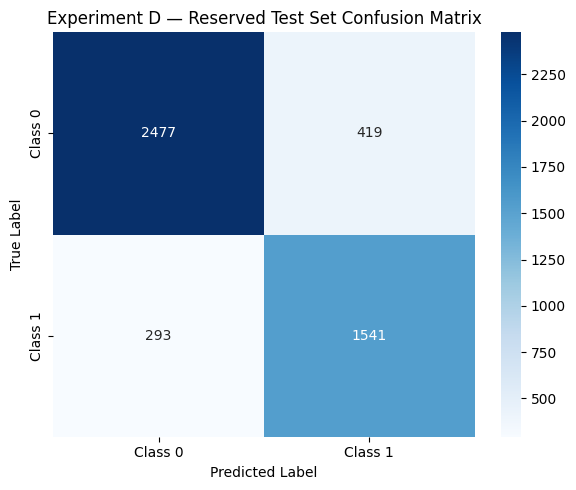

In [86]:
import torch
import numpy as np
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)
import matplotlib.pyplot as plt
import seaborn as sns

# Ensure the selected checkpoint is loaded
model_D.eval()

all_labels = []
all_predictions = []

with torch.inference_mode():
    for batch in test_loader:
        images = batch["image"].to(DEVICE)
        input_ids = batch["input_ids"].to(DEVICE)
        attention_mask = batch["attention_mask"].to(DEVICE)
        labels = batch["label"].to(DEVICE)

        outputs = model_D(images, input_ids, attention_mask)
        predictions = torch.argmax(outputs, dim=1)

        all_labels.extend(labels.cpu().numpy())
        all_predictions.extend(predictions.cpu().numpy())

# Calculate final metrics
test_accuracy = accuracy_score(all_labels, all_predictions)
test_precision = precision_score(
    all_labels, all_predictions, average="macro", zero_division=0
)
test_recall = recall_score(
    all_labels, all_predictions, average="macro", zero_division=0
)
test_macro_f1 = f1_score(
    all_labels, all_predictions, average="macro", zero_division=0
)

print("=" * 55)
print("FINAL TEST RESULTS — EXPERIMENT D")
print("=" * 55)
print(f"Test samples:       {len(all_labels)}")
print(f"Accuracy:           {test_accuracy:.4f}")
print(f"Macro Precision:    {test_precision:.4f}")
print(f"Macro Recall:       {test_recall:.4f}")
print(f"Macro F1-score:     {test_macro_f1:.4f}")

print("\nClassification Report:")
print(classification_report(
    all_labels,
    all_predictions,
    labels=[0, 1],
    target_names=["Class 0", "Class 1"],
    digits=4,
    zero_division=0
))

cm = confusion_matrix(all_labels, all_predictions, labels=[0, 1])

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Class 0", "Class 1"],
    yticklabels=["Class 0", "Class 1"]
)
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Experiment D — Reserved Test Set Confusion Matrix")
plt.tight_layout()
plt.show()

In [87]:
print("Confusion matrix:")
print(cm)

tn, fp, fn, tp = cm.ravel()

print(f"\nTrue negatives:  {tn}")
print(f"False positives: {fp}")
print(f"False negatives: {fn}")
print(f"True positives:  {tp}")

Confusion matrix:
[[2477  419]
 [ 293 1541]]

True negatives:  2477
False positives: 419
False negatives: 293
True positives:  1541
